# Midterm project: Vehicle fuel efficiency

## Stage 1. Problem and scope

**Project question:** can the combined fuel consumption of a new passenger car be predicted from its basic characteristics (model year, engine size, number of cylinders, class, transmission type, fuel type)?

**Task type:** regression.
**Target (fixed):** `Combined (L/100 km)`: combined consumption, liters per 100 km.

**Metrics:**
- **MAE** (L/100 km): the main metric, easy to interpret;
- **RMSE** (L/100 km): penalizes large errors more heavily;
- **R²**: the share of explained variance.

**Success criterion:** the MAE of the best model on test is at least 50% lower than the MAE of the baseline (predicting the mean target value on train). The threshold can be refined after the first results.

**Context and scope:** Natural Resources Canada data for 2014-2025 (11829 rows). The data has no vehicle weight or power, so the models rely on engine size, number of cylinders, and vehicle class instead. We take this limitation into account in the error analysis. Plan: cleaning and EDA, feature engineering, a split protected against leakage (group split by the `Make` + `Model` pair), baseline, Linear Regression, Decision Tree, KNN, cross-validation, error analysis.

## Reproducibility setup (Stage 7)

**What we do:** we fix one random seed `SEED` for the whole notebook and print the versions of the main libraries.

**Why:** the group split, cross-validation, K-Means, PCA and the ANN all contain randomness. If each of them used its own number (or none), two runs of the notebook could give different tables. Every later cell uses `SEED` (directly or through `RANDOM_STATE = SEED`) instead of a hard-coded number.

**Rule for the team:** do not write `random_state=42` by hand, use `random_state=SEED`. The ANN section adds its own framework seed (`tf.random.set_seed(SEED)` or `torch.manual_seed(SEED)`).

In [1]:
import os
import random
import sys

import numpy as np
import pandas as pd
import sklearn
import matplotlib
import seaborn

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Python", sys.version.split()[0])
for lib in [np, pd, sklearn, matplotlib, seaborn]:
    print(f"{lib.__name__:<12}{lib.__version__}")

Python 3.12.0
numpy       2.5.3
pandas      3.0.5
sklearn     1.9.1
matplotlib  3.11.2
seaborn     0.13.2


# Stage 2. Data loading and initial inspection

**Data source:** Natural Resources Canada, Fuel Consumption Ratings (Open Canada), official dataset page: https://open.canada.ca/data/en/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64

**License:** Open Government Licence - Canada.

**Where we load it from in the code:** a copy of this data in the GitHub repository `bgl96395/fuel-efficiency-dataset`, file `fuel_consumption_2014_2025.csv` (the `CSV_URL` link in the cell below). Size: 11829 rows, 15 columns, about 960 KB. We checked the years 2015-2024 against the official 2015-2024 file: the number of rows per year, the `Fuel type` distribution, the target statistics, and the number of missing values all match. We did not run a separate check against the official file for 2014 and 2025.

**What we use:** the whole file, model years **2014-2025** (11829 rows, 15 columns): the main dataset for training and testing. We do not mix in the 1995-2013 files: their ratings were recalculated using a different methodology.

**Known peculiarities:** no weight or power; `CO2 rating` and `Smog rating` are missing for the first years; several columns directly express the target (see 3.7).

**How we get the data:**
1. `pd.read_csv` reads the CSV directly from the `CSV_URL` link, no local files are needed, so the notebook runs the same way for all participants.
2. `df.columns.str.strip()` removes accidental spaces in column names.

In [2]:
import pandas as pd

CSV_URL = "https://raw.githubusercontent.com/bgl96395/fuel-efficiency-dataset/refs/heads/main/fuel_consumption_2014_2025.csv"
df = pd.read_csv(CSV_URL)
df.columns = df.columns.str.strip()

## Data size

`df.shape` shows the number of rows and columns.

In [3]:
print(df.shape)

(11829, 15)


**Result:** (11829, 15), i.e. 11829 cars and 15 columns.

**Conclusion:** this is enough for Linear Regression, Decision Tree, and KNN; the models train quickly.

## Data types and missing values

`df.info()` shows the type of each column and how many non-null values it has.

In [4]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 11829 entries, 0 to 11828
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Model year            11829 non-null  int64  
 1   Make                  11829 non-null  str    
 2   Model                 11829 non-null  str    
 3   Vehicle class         11829 non-null  str    
 4   Engine size (L)       11829 non-null  float64
 5   Cylinders             11829 non-null  int64  
 6   Transmission          11829 non-null  str    
 7   Fuel type             11829 non-null  str    
 8   City (L/100 km)       11829 non-null  float64
 9   Highway (L/100 km)    11829 non-null  float64
 10  Combined (L/100 km)   11829 non-null  float64
 11  Combined (mpg)        11829 non-null  int64  
 12  CO2 emissions (g/km)  11829 non-null  int64  
 13  CO2 rating            9633 non-null   float64
 14  Smog rating           8527 non-null   float64
dtypes: float64(6), int64(4), str(5

**Result:**
- Types: 6 float64 columns, 4 int64, 5 text (`object`).
- Missing values are present in only two columns: `CO2 rating` (9633 of 11829 filled) and `Smog rating` (8527 of 11829).

**Conclusion:** we are not using either column with missing values as features anyway because of data leakage (see below), so there is no need to fill the gaps.

## First rows

`df.head()` shows the first 5 rows to see what the data looks like.

In [5]:
print(df.head())

   Model year   Make       Model                 Vehicle class  \
0        2014  Acura         ILX                       Compact   
1        2014  Acura         ILX                       Compact   
2        2014  Acura  ILX Hybrid                       Compact   
3        2014  Acura     MDX 4WD  Sport utility vehicle: Small   
4        2014  Acura     RDX AWD  Sport utility vehicle: Small   

   Engine size (L)  Cylinders Transmission Fuel type  City (L/100 km)  \
0              2.0          4          AS5         Z              9.9   
1              2.4          4           M6         Z             11.2   
2              1.5          4          AV7         Z              6.0   
3              3.5          6          AS6         Z             12.7   
4              3.5          6          AS6         Z             12.1   

   Highway (L/100 km)  Combined (L/100 km)  Combined (mpg)  \
0                 6.7                  8.5              33   
1                 7.7                  9

**What we see:**
- The data starts in 2014, so the whole 2014-2025 file has been loaded.
- `Vehicle class` contains compound names (for example, `Compact` and `Sport utility vehicle: Small`). We will check the consistency of the notation in 3.3.
- `Transmission` consists of a type and a number of gears (`AS5`, `M6`, `AV7`): two features can be made from it.
- `Fuel type` is encoded with letters.
- Hybrids appear among the model names (for example, `ILX Hybrid`).

## List of columns

`df.columns.tolist()` prints the exact column names so that they can be referenced in code without typos.

**Candidate features:** `Model year`, `Make`, `Model`, `Vehicle class`, `Engine size (L)`, `Cylinders`, `Transmission`, `Fuel type`.

**Target:** `Combined (L/100 km)`.

**Excluded from features (data leakage):** `City (L/100 km)`, `Highway (L/100 km)`, `Combined (mpg)`, `CO2 emissions (g/km)`, `CO2 rating`, `Smog rating`. They directly express the target or are computed from it, and the model would get the answer instead of predicting it.

In [6]:
print(df.columns.tolist())

['Model year', 'Make', 'Model', 'Vehicle class', 'Engine size (L)', 'Cylinders', 'Transmission', 'Fuel type', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']


### Year range, fuel types, and statistics

The cell contains three checks:
1. Minimum and maximum year. **Result:** 2014 and 2025.
2. `value_counts()` for `Fuel type`. **Result:** X: 5574, Z: 5559, E: 423, D: 272, N: 1. The categories have very different frequencies, and `N` occurs only once (we will decide what to do with it during cleaning). Letter decoding per the NRCan documentation: X: regular gasoline, Z: premium gasoline, D: diesel, E: ethanol (E85), N: natural gas. Check against the Data Dictionary on the dataset page.
3. `describe()`: minimum, maximum, and mean for the numeric columns.

In [7]:
print(df["Model year"].min(), df["Model year"].max())
print(df["Fuel type"].value_counts())
df.describe()

2014 2025
Fuel type
X    5574
Z    5559
E     423
D     272
N       1
Name: count, dtype: int64


,Model year,Engine size (L),Cylinders,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
count,11829.000000,11829.000000,11829.000000,11829.000000,11829.000000,11829.000000,11829.000000,11829.000000,9633.00000,8527.000000
mean,2019.109984,3.153496,5.621354,12.537417,9.183380,11.028439,27.371375,254.023586,4.61362,4.824675
std,3.355525,1.340000,1.865467,3.481807,2.246852,2.881756,7.381000,61.066271,1.55905,1.751139
min,2014.000000,0.900000,3.000000,4.000000,3.900000,4.000000,11.000000,94.000000,1.00000,1.000000
25%,2016.000000,2.000000,4.000000,10.100000,7.600000,9.000000,22.000000,209.000000,4.00000,3.000000
50%,2019.000000,3.000000,6.000000,12.200000,8.900000,10.700000,26.000000,250.000000,5.00000,5.000000
75%,2022.000000,3.700000,6.000000,14.600000,10.400000,12.700000,31.000000,292.000000,5.00000,6.000000
max,2025.000000,8.400000,16.000000,30.700000,20.900000,26.100000,71.000000,608.000000,10.00000,8.000000


**What we see in `describe()`:**
- Target `Combined (L/100 km)`: from 4.0 to 26.1, mean about 11.0, std about 2.9. The spread is sufficient, so there is something to predict.
- Engine size 0.9-8.4 L, cylinders 3-16: the values are plausible, no obvious errors.

**Dataset limitation (limitation):** the data has no vehicle weight or power.

**What we use instead of weight and power:** the project topic mentions weight and power, but they are not in the data. Engine size, number of cylinders, and vehicle class (`Vehicle class`) indirectly reflect the size and power of the car, so we use them. Auto MPG (UCI) can be considered as an additional dataset for the final.

# Stage 3. Data cleaning
We check: duplicates, missing values, ranges, categories, suspicious features (leakage).
We record every decision together with its reason.

## 3.1 Duplicates

**What we check:** whether the table contains completely identical rows (all 15 columns match).

**Why:** repeated rows would make the model learn from the same data several times and make the quality estimate less honest.

**How:** `df.duplicated().sum()` counts repeated copies of rows.

In [8]:
print("Duplicates:", df.duplicated().sum())
df[df.duplicated(keep=False)].sort_values(["Make", "Model", "Model year"]).head(10)

Duplicates: 0


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating


**Result:** 0 duplicates found (`df.duplicated().sum()` = 0). The second part of the cell returned an empty table because there are no row copies.

**Decision:** we do not remove anything.

**Reason:** there are no completely identical rows, so the model will not see the same data several times, and the quality estimate will not be distorted by repeats.

## 3.2 Missing values in CO2 rating and Smog rating

**What we do:** for each year, we count how many ratings are missing.

**Why:** we are testing the hypothesis that the missing values are tied to the year (the rating was not published) rather than scattered randomly.
This is needed to understand the cause of the missing values, even though we do not fill them.

In [9]:
by_year = df.groupby("Model year").agg(
    rows=("Model year", "size"),
    co2_rating_missing=("CO2 rating", lambda s: s.isna().sum()),
    smog_rating_missing=("Smog rating", lambda s: s.isna().sum()),
)
print(by_year)

            rows  co2_rating_missing  smog_rating_missing
Model year                                               
2014        1068                1068                 1068
2015        1128                1128                 1128
2016        1106                   0                 1106
2017        1058                   0                    0
2018        1083                   0                    0
2019        1056                   0                    0
2020         975                   0                    0
2021         970                   0                    0
2022         976                   0                    0
2023         919                   0                    0
2024         789                   0                    0
2025         701                   0                    0


**Result:** the missing values in the ratings are tied to the year rather than scattered randomly:
- `CO2 rating` is missing in all rows of 2014 and 2015 (1068 + 1128 = 2196); from 2016 on there are no missing values;
- `Smog rating` is missing in all rows of 2014, 2015, and 2016 (1068 + 1128 + 1106 = 3302); from 2017 on there are no missing values.

The hypothesis is confirmed: there are no values in the file for these years.

**Decision:** we do not fill the missing values and do not remove the rows that contain them.

**Reason:** the `CO2 rating` and `Smog rating` columns will be dropped from the features as leakage (they almost directly express the target), so there is no point in filling them. At the same time, the rows for 2014-2016 are kept: we remove only the columns, not the cars, and do not lose 3302 observations.

## 3.3 Categorical columns

**What we do:** we look at which values occur in `Vehicle class`, `Transmission`, and `Fuel type`, and check the text columns for extra spaces and inconsistent letter case.

**Why:** models work with numbers, so the text categories will have to be encoded later. If the same category is written in different ways (for example `Compact` and `compact `), the encoder will treat them as different, and the feature will become less informative.

**How:** `value_counts()` shows all values and their frequency. The check for spaces and letter case compares the number of unique values before and after normalization.

In [10]:
df["Transmission"].value_counts()

Transmission
AS8     2285
AS6     1494
M6      1210
A8       945
A6       857
AM7      787
A9       699
AS10     569
AV       507
AS7      341
A10      324
AM8      296
M5       208
AS9      187
AM6      177
AV6      164
AV7      156
M7       152
AV8      144
A5        84
A4        65
A7        58
AV10      46
AS5       34
AV1       28
AM9        6
AM5        4
AS4        2
Name: count, dtype: int64

In [11]:
print(df["Vehicle class"].value_counts())

Vehicle class
Sport utility vehicle: Small       2203
Mid-size                           1639
Sport utility vehicle: Standard    1482
Compact                            1360
Pickup truck: Standard             1015
Subcompact                          964
Full-size                           894
Two-seater                          753
Minicompact                         535
Station wagon: Small                333
Pickup truck: Small                 240
Minivan                             117
Special purpose vehicle             110
Station wagon: Mid-size              92
Van: Passenger                       70
Van: Cargo                           22
Name: count, dtype: int64


In [12]:
for col in ["Make", "Model", "Vehicle class", "Transmission", "Fuel type"]:
    n_space = (df[col] != df[col].str.strip()).sum()
    n_unique = df[col].nunique()
    n_unique_norm = df[col].str.strip().str.lower().nunique()
    print(col, "| with extra spaces:", n_space,
          "| unique:", n_unique, "| after normalization:", n_unique_norm)

Make | with extra spaces: 0 | unique: 44 | after normalization: 44
Model | with extra spaces: 22 | unique: 2294 | after normalization: 2268
Vehicle class | with extra spaces: 0 | unique: 16 | after normalization: 16
Transmission | with extra spaces: 0 | unique: 28 | after normalization: 28
Fuel type | with extra spaces: 0 | unique: 5 | after normalization: 5


**Result:**
- `Make`: 44 values, `Vehicle class`: 16, `Transmission`: 28, `Fuel type`: 5. There are no spaces or inconsistent letter case in these columns; the values before and after normalization match.
- `Model`: 22 rows have extra spaces at the edges, and of 2294 unique names 2268 remain after normalization. Analysis in 3.5.
- Rare values exist in `Transmission` (`AS4`: 2, `AM5`: 4, `AM9`: 6) and in `Vehicle class` (`Van: Cargo`: 22), as well as among the makes (for example, `SRT`: 2 rows).

**Decision:** we do not change `Make`, `Vehicle class`, `Transmission`, and we do not merge or remove rare categories.

**Reason:** these are not recording errors but real models. We will later split the transmission into a type and a number of gears, which will remove the problem of rare codes. We will configure the encoder to handle unknown categories, because rare values may appear only in test.

## 3.4 Fuel type = N

**What we do:** we look at the only row with fuel type `N`.

**Why:** one row out of 11829 will not teach the model anything. When splitting into train and test, it can end up in only one part, and then the encoder will encounter an unknown category. We need to decide what to do with it.

In [13]:
print(df[df["Fuel type"] == "N"])

print("Before:", df.shape)
df = df[df["Fuel type"] != "N"].reset_index(drop=True)
print("After:", df.shape)
print(df["Fuel type"].value_counts())

      Model year       Make             Model Vehicle class  Engine size (L)  \
2432        2016  Chevrolet  Impala Dual Fuel      Mid-size              3.6   

      Cylinders Transmission Fuel type  City (L/100 km)  Highway (L/100 km)  \
2432          6          AS6         N             15.2                 9.5   

      Combined (L/100 km)  Combined (mpg)  CO2 emissions (g/km)  CO2 rating  \
2432                 12.7              22                   213         6.0   

      Smog rating  
2432          NaN  
Before: (11829, 15)
After: (11828, 15)
Fuel type
X    5574
Z    5559
E     423
D     272
Name: count, dtype: int64


**Result:** the only row with `N` is a Chevrolet Impala Dual Fuel 2016 (3.6 L, 6 cylinders, AS6). After removal the table has 11828 rows and 4 fuel types: X (5574), Z (5559), E (423), D (272).

**Decision:** we remove this row.

**Reason:** one row will not let the model learn a pattern. `N` cannot be merged with another category, because it is a different kind of fuel. The loss is about 0.01% of the data.

## 3.5 Model names (Model)

**What we do:** we look for extra spaces and inconsistent letter case in identical names in `Model`.

**Why:** we plan to use the `Make` + `Model` pair for the group split. If one model is written in different ways, it will end up in different groups, and almost identical cars will land in both train and test (leakage).


In [14]:
bad = df[df["Model"] != df["Model"].str.strip()]
print("Rows with spaces:", len(bad))
bad["Model"].map(repr).head(10)

Rows with spaces: 22


2779               'XF AWD '
5078                 'CX-5 '
6529           'A6 quattro '
6530           'A6 quattro '
6531           'A6 allroad '
6533                  'A8L '
6534                  'A8L '
7183         'A 220 4MATIC '
7195    'AMG CLA 35 4MATIC '
7196    'AMG CLA 45 4MATIC '
Name: Model, dtype: str

In [15]:
s = df["Model"].str.strip()
print("after strip:", s.nunique(), "| after strip + lower:", s.str.lower().nunique())

after strip: 2283 | after strip + lower: 2268


In [16]:
low = s.str.lower()
n_variants = s.groupby(low).nunique()
for key in n_variants[n_variants > 1].index:
    print(sorted(s[low == key].unique()))

['ALPINA B8 Gran Coupe', 'Alpina B8 Gran Coupe']
['ALPINA XB7', 'Alpina XB7']
['F-PACE P250', 'F-Pace P250']
['F-PACE P400', 'F-Pace P400']
['F-PACE P550 SVR', 'F-Pace P550 SVR']
['GranTurismo', 'Granturismo']
['GranTurismo Convertible', 'Granturismo Convertible']
['Huracan EVO Coupe', 'Huracan evo Coupe']
['Huracan EVO Coupe AWD', 'Huracan evo Coupe AWD']
['Huracan EVO Spyder', 'Huracan evo Spyder']
['Huracan EVO Spyder AWD', 'Huracan evo Spyder AWD']
['LaCrosse', 'Lacrosse']
['LaCrosse AWD', 'Lacrosse AWD']
['LaCrosse eAssist', 'Lacrosse eAssist']
['Tacoma 4WD D-Cab TRD Off-Road/PRO', 'Tacoma 4WD D-Cab TRD Off-Road/Pro']


In [17]:
pairs_before = df[["Make", "Model"]].drop_duplicates().shape[0]

df["Model"] = df["Model"].str.lower()

pairs_after = df[["Make", "Model"]].drop_duplicates().shape[0]
print("Make+Model pairs: before", pairs_before, "| after", pairs_after,
      "| removed", pairs_before - pairs_after)
print("Unique Model:", df["Model"].nunique())

Make+Model pairs: before 2295 | after 2280 | removed 15
Unique Model: 2279


**Result:**
- In `Model`, 22 rows have extra spaces at the edges. After `strip`, the number of unique names fell from 2294 to 2283, and after `strip` + `lower` there are 2268.
- 15 names are written with different letter case for the same model (for example `LaCrosse` and `Lacrosse`, `F-PACE P250` and `F-Pace P250`, `Huracan EVO Coupe` and `Huracan evo Coupe`).
- In the cell above only `lower()` was applied to `Model`: the number of `Make` + `Model` pairs became 2280 instead of 2295 (15 removed), and there are 2279 unique names. Names that differ only by a trailing space (11 names, 22 rows) remain different for now. With `strip` + `lower` there would be 2268 names and 2269 pairs.
- There is one more pair than names: the same name occurs for two different makes.

**Decision:** we converted `Model` to lower case. The edge spaces in 22 rows of `df` have not been removed yet.

**Reason:** these are the same cars written in different ways. In the group split they would end up in different groups, and almost identical cars would be in both train and test at the same time (leakage). We need to group by the `Make` + `Model` pair, not by `Model` alone: otherwise two different cars with the same name from different makes would be merged. We do not use `Model` itself as a feature, there are too many names.

## 3.6 Ranges and outliers
**What we do:** we look at the minimum and maximum of the key numeric columns.

**Why:** to find physically impossible values (a zero engine, negative consumption). Large and small but real values must not be removed.

In [18]:
df[["Engine size (L)", "Cylinders", "Combined (L/100 km)"]].describe()

,Engine size (L),Cylinders,Combined (L/100 km)
count,11828.000000,11828.000000,11828.000000
mean,3.153458,5.621322,11.028297
std,1.340050,1.865542,2.881837
min,0.900000,3.000000,4.000000
25%,2.000000,4.000000,9.000000
50%,3.000000,6.000000,10.700000
75%,3.700000,6.000000,12.700000
max,8.400000,16.000000,26.100000


**Result:** for all 11828 rows: `Engine size` 0.9-8.4 L, `Cylinders` 3-16, `Combined (L/100 km)` 4.0-26.1 (mean about 11, std about 2.9). There are no zeros or negative values.

**Decision:** we do not remove outliers.

**Reason:** high consumption for powerful cars and low consumption for hybrids are real cars, not errors. Only physically impossible values should be removed, and there are none.

## 3.7 Leakage columns
**What we do:** we fix the list of columns that must not be used as features.

**Why:** most of these columns almost directly express the target `Combined (L/100 km)`: `City` and `Highway` are its components, `Combined (mpg)` is the same consumption in other units, `CO2 emissions` is calculated from consumption using a coefficient for the fuel type, and `CO2 rating` is derived from CO2. The model would get the answer as a hint and show nice but false results. `Smog rating` is not directly related to consumption, but we remove it as well: it is an official rating rather than a characteristic of the car, and it is missing for 2014-2016.

**How:** we save the list in `leak_cols`. We do not remove them from `df` yet, because they are needed for EDA (the correlation matrix will show the problem). We will remove them when assembling the features.

In [19]:
leak_cols = [
    "City (L/100 km)", "Highway (L/100 km)", "Combined (mpg)",
    "CO2 emissions (g/km)", "CO2 rating", "Smog rating",
]
print(leak_cols)

['City (L/100 km)', 'Highway (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']


**Result:** 6 columns are fixed in `leak_cols`: `City (L/100 km)`, `Highway (L/100 km)`, `Combined (mpg)`, `CO2 emissions (g/km)`, `CO2 rating`, `Smog rating`.

**Decision:** these columns will not become features. They remain in `df` for now.

**Reason:** five of the six columns express the target directly or through a conversion, and the sixth (`Smog rating`) is removed according to a project rule and because of missing values. We keep them until the EDA to show on the correlation matrix why they would cause leakage. We will remove them from the feature table when assembling the features (stage 5), before the split and before any `fit`.

## Stage 3 summary
- **Rows:** was 11829, now 11828 (1 row with `Fuel type = N` removed).
- **Duplicates:** none.
- **Missing values:** only `CO2 rating` (2014-2015) and `Smog rating` (2014-2016). We do not fill them, both columns are in `leak_cols`.
- **Categories:** we do not change `Vehicle class`, `Transmission`, `Make`; rare values are visible in `value_counts` (3.3). In `Model` we normalized the letter case (15 spelling variants). Edge spaces (22 rows) have not been removed yet.
- **Outliers:** we looked at the minimum and maximum, did not remove anything, there are no impossible values.
- **Leakage:** 6 columns that will not become features are fixed in `leak_cols`.
- **Notes for the next stages:** split `Transmission` into a type and a number of gears (507 rows have `AV` without a number); use the `Make` + `Model` pair for the group split; configure the encoder for unknown categories because of rare values in `Vehicle class`, `Transmission`, and `Make`.

# Stage 4. EDA

We build 5 plots, each with a short conclusion. Target: `Combined (L/100 km)`.
Data after cleaning: 11828 rows, model years 2014-2025.

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
TARGET = "Combined (L/100 km)"
print(df.shape)

(11828, 15)


### 4.1 Target distribution

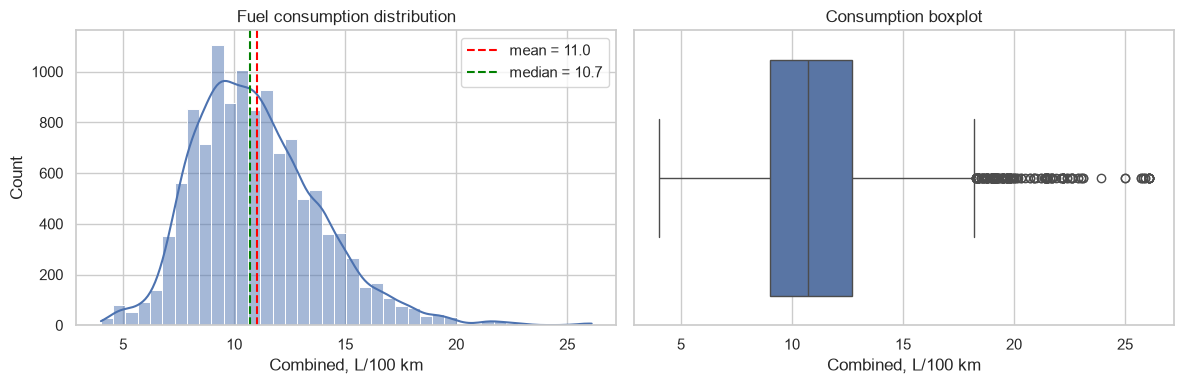

count    11828.00
mean        11.03
std          2.88
min          4.00
25%          9.00
50%         10.70
75%         12.70
max         26.10
Name: Combined (L/100 km), dtype: float64
Skewness (skew): 0.81


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df[TARGET], bins=40, kde=True, ax=axes[0])
axes[0].axvline(df[TARGET].mean(), color="red", linestyle="--", label=f"mean = {df[TARGET].mean():.1f}")
axes[0].axvline(df[TARGET].median(), color="green", linestyle="--", label=f"median = {df[TARGET].median():.1f}")
axes[0].set_title("Fuel consumption distribution")
axes[0].set_xlabel("Combined, L/100 km")
axes[0].legend()

sns.boxplot(x=df[TARGET], ax=axes[1])
axes[1].set_title("Consumption boxplot")
axes[1].set_xlabel("Combined, L/100 km")

plt.tight_layout()
plt.show()

print(df[TARGET].describe().round(2))
print("Skewness (skew):", round(df[TARGET].skew(), 2))

**Conclusion:**
- The distribution is right-skewed (skew 0.81): most cars consume 9-12.7 L/100 km (25% and 75% quantiles), and the right tail extends to 26.1.
- The mean of 11.03 is greater than the median of 10.7 because of the tail. Std 2.88.
- The points on the right of the boxplot are real powerful cars (V8, V12, vans), not errors, so we do not remove them.
- For the models: the "predict the mean" baseline will give an error on the order of std (about 2.9). The tail means that the models will make the largest errors on rare heavy cars.

### 4.2 Engine size and consumption

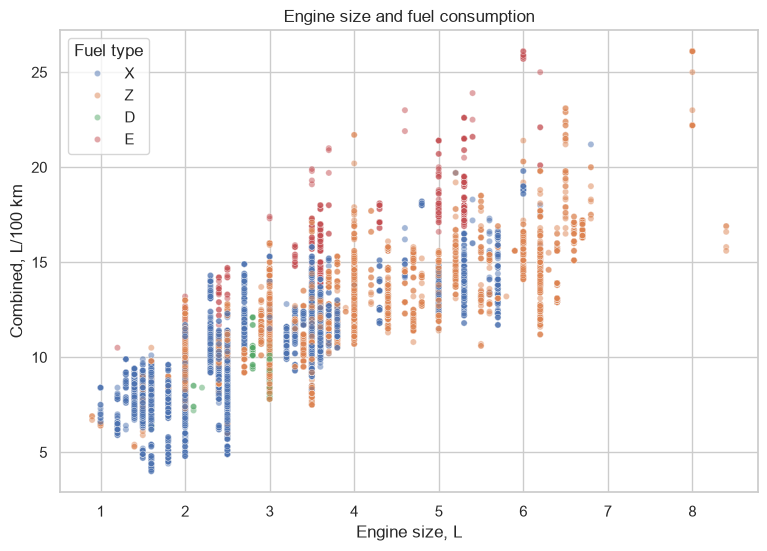

Correlation between Engine size and target: 0.811


In [22]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df, x="Engine size (L)", y=TARGET,
    hue="Fuel type", hue_order=["X", "Z", "D", "E"],
    alpha=0.5, s=20
)
plt.title("Engine size and fuel consumption")
plt.xlabel("Engine size, L")
plt.ylabel("Combined, L/100 km")
plt.show()

print("Correlation between Engine size and target:", round(df["Engine size (L)"].corr(df[TARGET]), 3))

**Conclusion:**
- The relationship is strong and positive, correlation 0.81: the bigger the engine, the higher the consumption.
- For the same size the spread is large (hybrids at the bottom, heavy SUVs at the top), so engine size alone is not enough, and vehicle class and fuel type are needed.
- `E` points (ethanol E85) lie higher than the others at the same size: this is a fuel effect, not an engine effect.
- For the models: Linear Regression will capture the overall trend, while Decision Tree and KNN will better handle nonlinearity and the influence of `Fuel type`.

### 4.3 Correlation matrix

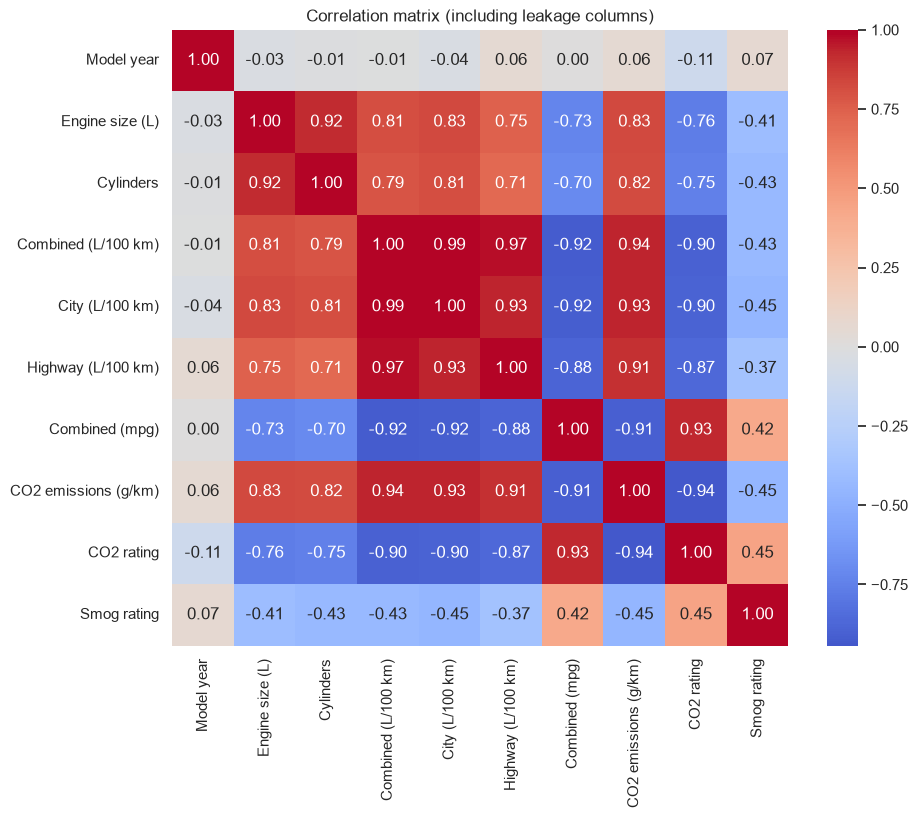

City (L/100 km)         0.992
Highway (L/100 km)      0.971
CO2 emissions (g/km)    0.939
Combined (mpg)         -0.922
CO2 rating             -0.902
Engine size (L)         0.811
Cylinders               0.789
Smog rating            -0.431
Model year             -0.006
Name: Combined (L/100 km), dtype: float64


In [23]:
num_cols = [
    "Model year", "Engine size (L)", "Cylinders", TARGET,
    "City (L/100 km)", "Highway (L/100 km)", "Combined (mpg)",
    "CO2 emissions (g/km)", "CO2 rating", "Smog rating",
]
corr = df[num_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (including leakage columns)")
plt.show()

print(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

**Conclusion:**
- The columns from `leak_cols` are almost perfectly related to the target: `City` 0.99, `Highway` 0.97, `CO2 emissions` 0.94, `Combined (mpg)` -0.92, `CO2 rating` -0.90. They express the target directly, so we exclude them from the features. `Smog rating` is related more weakly (-0.43), and we exclude it too (project rule, missing values).
- Among the allowed features the strongest are: `Engine size` (0.81) and `Cylinders` (0.79).
- `Model year` is almost unrelated to the target (-0.01).
- `Engine size` and `Cylinders` are strongly correlated with each other (multicollinearity): this is not a problem for trees and KNN, but for Linear Regression we take it into account when interpreting coefficients.

### 4.4 Cylinders and fuel type

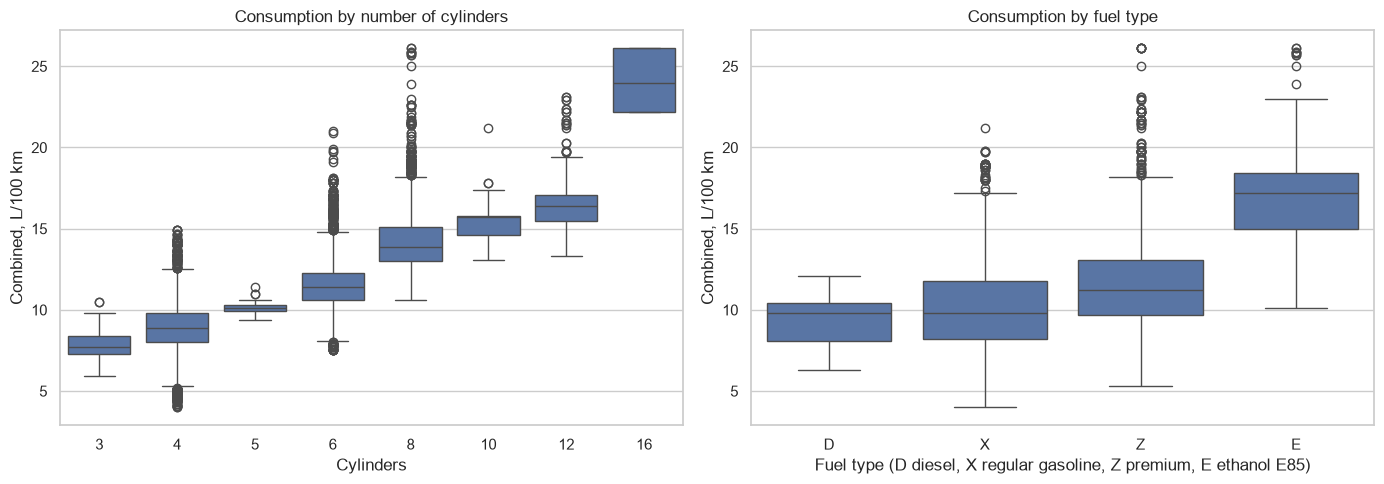

           count   mean
Cylinders              
3            197   7.74
4           5156   8.91
5             28  10.19
6           3835  11.58
8           2283  14.35
10            72  15.42
12           243  16.60
16            14  24.13
           count   mean
Fuel type              
D            272   9.31
E            423  16.97
X           5574  10.08
Z           5559  11.61


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="Cylinders", y=TARGET, ax=axes[0])
axes[0].set_title("Consumption by number of cylinders")
axes[0].set_xlabel("Cylinders")
axes[0].set_ylabel("Combined, L/100 km")

sns.boxplot(data=df, x="Fuel type", y=TARGET, order=["D", "X", "Z", "E"], ax=axes[1])
axes[1].set_title("Consumption by fuel type")
axes[1].set_xlabel("Fuel type (D diesel, X regular gasoline, Z premium, E ethanol E85)")
axes[1].set_ylabel("Combined, L/100 km")

plt.tight_layout()
plt.show()

print(df.groupby("Cylinders")[TARGET].agg(["count", "mean"]).round(2))
print(df.groupby("Fuel type")[TARGET].agg(["count", "mean"]).round(2))

**Conclusion:**
- Consumption grows with the number of cylinders: on average 3 cyl. 7.7, 4 cyl. 8.9, 6 cyl. 11.6, 8 cyl. 14.4, 12 cyl. 16.6 L/100 km.
- The groups are of very different sizes: 4 cyl. 5156 cars, 6 cyl. 3835, 8 cyl. 2283, while 5 cyl. only 28, 10 cyl. 72, 16 cyl. 14. Estimates in the rare groups are less reliable, and we expect larger errors there.
- Fuel type shifts consumption strongly: E 17.0, Z 11.6, X 10.1, D 9.3.
- The spread remains within groups, so class and transmission are also needed.
- For the models: we encode `Fuel type` with one-hot, and `Cylinders` can be kept numeric.

### 4.5 Years and vehicle class

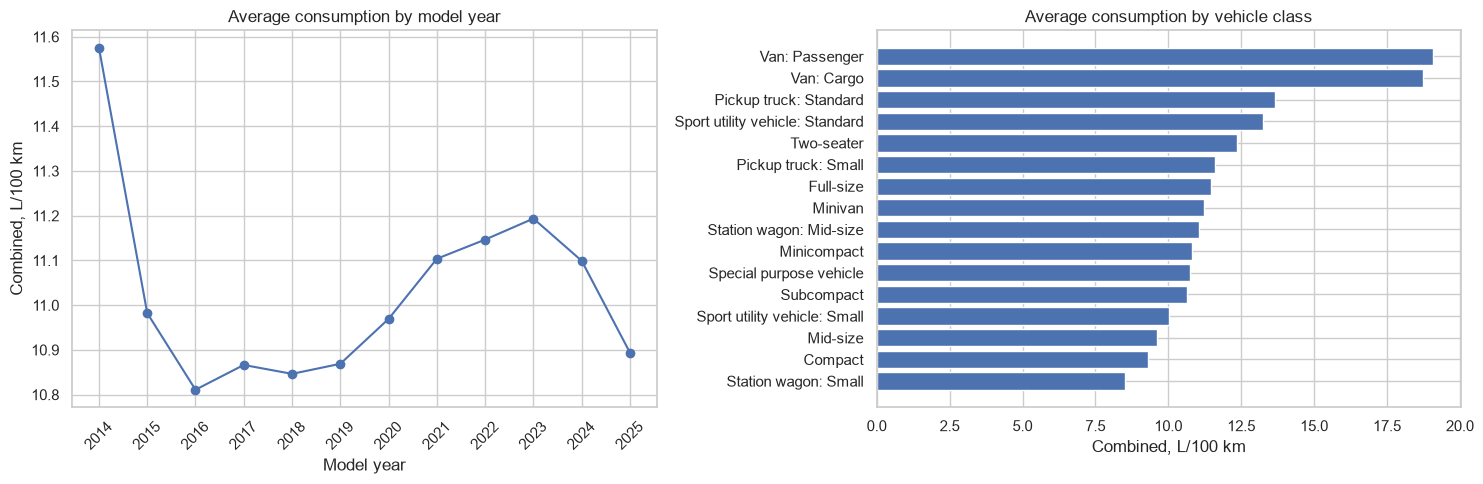

Model year
2014    11.58
2015    10.98
2016    10.81
2017    10.87
2018    10.85
2019    10.87
2020    10.97
2021    11.10
2022    11.15
2023    11.19
2024    11.10
2025    10.89
Name: Combined (L/100 km), dtype: float64
Vehicle class
Station wagon: Small                8.51
Compact                             9.29
Mid-size                            9.62
Sport utility vehicle: Small       10.02
Subcompact                         10.65
Special purpose vehicle            10.75
Minicompact                        10.82
Station wagon: Mid-size            11.06
Minivan                            11.23
Full-size                          11.45
Pickup truck: Small                11.60
Two-seater                         12.36
Sport utility vehicle: Standard    13.25
Pickup truck: Standard             13.65
Van: Cargo                         18.72
Van: Passenger                     19.08
Name: Combined (L/100 km), dtype: float64


In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

yearly = df.groupby("Model year")[TARGET].mean()
axes[0].plot(yearly.index, yearly.values, marker="o")
axes[0].set_title("Average consumption by model year")
axes[0].set_xlabel("Model year")
axes[0].set_ylabel("Combined, L/100 km")
axes[0].set_xticks(yearly.index)
axes[0].tick_params(axis="x", rotation=45)

by_class = df.groupby("Vehicle class")[TARGET].mean().sort_values()
axes[1].barh(by_class.index, by_class.values)
axes[1].set_title("Average consumption by vehicle class")
axes[1].set_xlabel("Combined, L/100 km")

plt.tight_layout()
plt.show()

print(yearly.round(2))
print(by_class.round(2))

**Conclusion:**
- By year: 2014 stands out (11.58); from 2015 to 2025 consumption barely changes (10.8-11.2). The improvement in engine efficiency is offset by the growing share of heavy SUVs and pickups, so the correlation with year is about zero.
- Class has a strong influence: the most economical are `Station wagon: Small` (8.5), `Compact` (9.3), `Mid-size` (9.6); the most expensive to run are `SUV: Standard` (13.3), `Pickup truck: Standard` (13.7), `Van: Cargo` (18.7), `Van: Passenger` (19.1).
- Vans are rare (22 and 70 cars), so large errors are possible there.
- For the models: `Vehicle class` is an important feature, and we encode it with one-hot. We will decide on the value of `Model year` during feature selection. For the group split we remember that one model repeats across different years.

## Stage 4 summary

- **Target:** right-skewed (mean 11.03, median 10.7, std 2.88),
  heavy tail up to 26.1.
- **Strong features:** `Engine size` (0.81), `Cylinders` (0.79),
  `Fuel type`, `Vehicle class`.
- **Weak feature:** `Model year` (-0.01).
- **Leakage confirmed:** 5 columns from `leak_cols` correlate with
  the target at 0.90-0.99, we exclude them when assembling the features.
- **Multicollinearity:** `Engine size` and `Cylinders`.
- **Rare groups:** 5, 10, and 16 cylinders; `Van: Cargo`,
  `Van: Passenger`.
- **For stage 5:** one-hot for `Fuel type` and `Vehicle class`, splitting
  `Transmission` into a type and a number of gears, new features (transmission
  type, number of gears, displacement per cylinder). 

## Stage 5. Feature engineering

We prepare the features: we split `Transmission`, add a new feature,
set up encoding and missing values, and fix the final set.

Parsing the transmission code and dividing two columns are computed row by
row and immediately. The median and one-hot are only described: they learn from
the data, so `fit` will happen inside the pipeline on train. All models work on
the original units. Therefore there is essentially one preprocessor
(`preprocessor_base`), and `preprocessor_knn` is its alias for KNN.


## 5.1 New features

**What we do:** from `Transmission` we take the type (`trans_type`) and the number of gears (`gears`), and add `disp_per_cyl` (engine size / number of cylinders).

**Why:**
- `Transmission` has 28 codes, some of them rare (`AS4`: 2 rows, `AM5`: 4). After parsing, 5 types and one number remain.
- The data has no weight or power, so `disp_per_cyl` partially replaces them: engines with the same number of cylinders but different displacement get different values.

In [26]:
tr = df["Transmission"].str.extract(r"^([A-Z]+)(\d*)$")
df["trans_type"] = tr[0]
df["gears"] = pd.to_numeric(tr[1], errors="coerce")

df["disp_per_cyl"] = df["Engine size (L)"] / df["Cylinders"]

print(df["trans_type"].value_counts())
print("Missing values in gears:", df["gears"].isna().sum())
print(df.groupby("trans_type")[TARGET].mean().round(2))
print(df[["disp_per_cyl", "gears"]].corrwith(df[TARGET]).round(3))

trans_type
AS    4911
A     3032
M     1570
AM    1270
AV    1045
Name: count, dtype: int64
Missing values in gears: 507
trans_type
A     12.44
AM    10.93
AS    11.20
AV     7.71
M     10.06
Name: Combined (L/100 km), dtype: float64
disp_per_cyl    0.524
gears           0.165
dtype: float64


**Result:**
- Transmission types: `AS` 4911, `A` 3032, `M` 1570, `AM` 1270, `AV` 1045.
- Missing values in `gears` only for `AV` (CVT), 507 rows: a CVT has no fixed gears, this is not a data error.
- Average consumption: `AV` 7.7, `M` 10.1, `AM` 10.9, `AS` 11.2, `A` 12.4 L/100 km.
- Correlation with the target: `disp_per_cyl` 0.52, `gears` 0.17.

**Conclusion:** `trans_type` clearly distinguishes consumption, and `disp_per_cyl` has a noticeable relationship with the target (0.52). `gears` is related more weakly, but it describes the transmission differently than the type does.

**Decision:** we keep all three features. We do not fill the missing values in `gears` here.
**Reason:** the median is computed from the data, so it must be filled only on train, inside the pipeline. The fact that it is a CVT is not lost: it is stored in `trans_type`.

## 5.2 Encoding and missing values

**What we do:** we describe the preprocessor without `fit`: filling missing values
and one-hot encoding. 

**Why:**

- Linear Regression, Decision Tree, and KNN work on the
  original units.
- Encoding is needed for all categorical columns `Vehicle class`,
  `Fuel type`, `trans_type`: they have no order, so one-hot rather than
  the numbers 1, 2, 3.
- We fill the missing values in `gears` (507, CVT) with the median, because
  models do not work with missing values.
- `handle_unknown="ignore"` is needed because of rare categories (3.3): if a
  category appears only in test, the encoder will not fail.

**Limitation for KNN:** without scaling, distances are determined by
features with a large numeric range (`Cylinders` 3-16, `gears`,
`Model year` 2014-2025), while one-hot columns (0/1) barely have any influence. We
check this in 7.6 (KNN with and without `Model year`).

In [27]:
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

num_cols = ["Model year", "Engine size (L)", "Cylinders", "disp_per_cyl", "gears"]
cat_cols = ["Vehicle class", "Fuel type", "trans_type"]

preprocessor_base = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

preprocessor_knn = preprocessor_base

**Result:** the preprocessor is created, and it has not seen the data yet.

**Decision:** `preprocessor_knn`
is identical to `preprocessor_base`, and the separate name remains only for
code readability at stage 7.

**Reason:** a project requirement. Everything that learns from the data (the median,
the list of categories) is trained on train inside the pipeline.

## 5.3 Feature selection

**What we do:** we assemble `X` and `y` and check that there are no columns from `leak_cols` in `X`.

**Why:** in 3.7 we promised to remove them when assembling the features. `assert` will stop the notebook if a leak gets in there.

In [28]:
X = df[num_cols + cat_cols]
y = df[TARGET]

assert not set(leak_cols) & set(X.columns)
assert TARGET not in X.columns
print("X:", X.shape, "| y:", y.shape)
print("Categories: Vehicle class", X["Vehicle class"].nunique(),
      "| Fuel type", X["Fuel type"].nunique(),
      "| trans_type", X["trans_type"].nunique())
print("Missing values:", X.isna().sum()[X.isna().sum() > 0].to_dict())

X: (11828, 8) | y: (11828,)
Categories: Vehicle class 16 | Fuel type 4 | trans_type 5
Missing values: {'gears': 507}


**Result:**
- `X`: (11828, 8), `y`: (11828,). The sizes match.
- Categories: `Vehicle class` 16, `Fuel type` 4, `trans_type` 5. After one-hot there are 25 columns, which is not many.
- Missing values only in `gears` (507, CVTs), we will fill them in the pipeline.
- Columns from `leak_cols` and the target are absent from `X` (verified with `assert`).

**Decision:** 8 features: 5 numeric and 3 categorical.

**Reason:** we take the characteristics of the car that describe the engine, transmission, fuel, and size. We do not take `Make` (44 values) and `Model` (2269 names): one-hot would inflate the number of columns and blur the distances in KNN. We keep `Model year` conditionally (its relationship with the target is about zero) and will check it at stage 7 by comparing MAE with and without the year.

# Stage 6. Split and leakage protection

We split the data into train, validation, and test. We touch test once, at the very end.

## 6.1 Why a group split

In the data, the same model appears in different years (on average 5 rows per `Make` + `Model` pair), and its characteristics barely change. With an ordinary random split, such a car would end up in both train and test, and the model would get an almost ready answer. Therefore we split by groups: all rows of one `Make` + `Model` pair go entirely into one part.

**About stratify:** stratification is needed for classification, and ours is regression, so we do not use it. Instead we will check that the target distribution in the parts is similar.

**Proportions:** train 70%, validation 15%, test 15%. Validation is needed for choosing the model and features (for example, whether `Model year` is needed), and test only for the final evaluation.

### 1. Split

In [29]:
from sklearn.model_selection import GroupShuffleSplit

RANDOM_STATE = SEED
groups = df["Make"] + " | " + df["Model"].str.strip()

split1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
temp_idx, test_idx = next(split1.split(X, y, groups))
X_temp, y_temp, g_temp = X.iloc[temp_idx], y.iloc[temp_idx], groups.iloc[temp_idx]
X_test, y_test, g_test = X.iloc[test_idx], y.iloc[test_idx], groups.iloc[test_idx]

split2 = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE)
train_idx, val_idx = next(split2.split(X_temp, y_temp, g_temp))
X_train, y_train, g_train = X_temp.iloc[train_idx], y_temp.iloc[train_idx], g_temp.iloc[train_idx]
X_val, y_val, g_val = X_temp.iloc[val_idx], y_temp.iloc[val_idx], g_temp.iloc[val_idx]

print("train:", len(X_train), "| val:", len(X_val), "| test:", len(X_test))

train: 8268 | val: 1809 | test: 1751


### 2. Leakage check

In [30]:
print("train and val:", len(set(g_train) & set(g_val)))
print("train and test:", len(set(g_train) & set(g_test)))
print("val and test:", len(set(g_val) & set(g_test)))

print("Mean target: train", round(y_train.mean(), 2),
      "| val", round(y_val.mean(), 2),
      "| test", round(y_test.mean(), 2))

train and val: 0
train and test: 0
val and test: 0
Mean target: train 11.03 | val 10.98 | test 11.07


### 3. Comparison with an ordinary split

In [31]:
from sklearn.model_selection import train_test_split

g_a, g_b = train_test_split(groups, test_size=0.15, random_state=SEED)

print("Regular split:", round(g_b.isin(g_a).mean() * 100, 1), "%")
print("Group split:", round(g_test.isin(g_train).mean() * 100, 1), "%")

Regular split: 94.7 %
Group split: 0.0 %


**Result:**
- Train 8268 rows (69.9%, 1587 groups), validation 1809 (15.3%, 341 groups), test 1751 (14.8%, 341 groups).
- There are no group overlaps between the parts (0, 0, 0).
- The target in the parts is similar: mean 11.03 (train), 10.98 (val), 11.07 (test), std 2.94, 2.66, 2.83.
- With a random split, 94.7% of test rows would have a "twin" in train, while with the group split 0%. This shows that an ordinary split would have given inflated quality.
- All categories of `Vehicle class`, `Fuel type`, `trans_type` from val and test are present in train. Insignificant: `Van: Passenger` is absent from validation.

**How we avoid leakage:**

1. Groups by `Make` + `Model`: one model is never in
   both train and test at the same time.
2. 6 columns that express the target have been removed from the features (stages 3.7, 5.3).
3. The split is done before any `fit`: the median and one-hot will be learned
   only on train inside the pipeline.
4. We use validation for choosing the model and features, and test only
   for the final evaluation.
5. We do cross-validation only on train and also by groups
   (`GroupKFold`).

**Decision:** `RANDOM_STATE = 42` fixes the split so that the results
are reproducible. 

**Limitation:** the split is random over groups, so the
composition of test depends on `RANDOM_STATE`. The distribution of `Vehicle class` in the
parts differs slightly (for example, `Pickup truck: Small` is 1.4% in
train and 4.8% in test), and we will take this into account in the error analysis.

## Stage 6 summary

- **Split:** train 70% / validation 15% / test 15% by the groups
  `Make` + `Model`.
- **No leakage between parts:** the groups do not overlap.
- **CV:** `GroupKFold(5)` on train (created in 7.5).
- **Passed to stage 7:** `X_train`, `y_train`, `X_val`, `y_val`,
  `X_test`, `y_test`, `g_train`, `g_val`, `g_test`,
  `preprocessor_base`, `preprocessor_knn`.

In [32]:
needed = ["df", "X", "y", "num_cols", "cat_cols", "preprocessor_base", "preprocessor_knn",
          "X_train", "y_train", "X_val", "y_val", "X_test", "y_test",
          "g_train", "g_val", "g_test"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run stages 5 and 6 first. Not found: {missing}"
print("Everything is in place")

Everything is in place


## Stage 7. Baseline and models

We compare all models on **validation**. We use test once, at the
end. Each model is trained inside a `Pipeline`, so the median and
one-hot are computed only on train.
Metrics: MAE (main), RMSE, R².

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = SEED

def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

results = {}

## 7.1 Baseline: mean target value

**Idea:** a model that predicts the train mean for any car.
This is the "floor": any reasonable model must be noticeably better.

**What we expect:** R² around 0, RMSE on the order of the target std (about 2.7
L/100 km).

In [34]:
dummy = DummyRegressor(strategy="mean").fit(X_train, y_train)
results["Mean baseline"] = evaluate(y_val, dummy.predict(X_val))
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
Mean baseline,2.123,2.663,-0.0



**Result:** MAE = 2.123, RMSE = 2.663, R² = -0.000 (on validation).

**Conclusion:** this is the reference point for the success criterion: the MAE of the best model
must be at least half as large, i.e. no more than 1.06.

## 7.2 Linear Regression

**Idea:** we look for a linear dependence of consumption on engine size,
cylinders, fuel type, etc. 

**Preprocessor:** `preprocessor_base`
(filling missing values in `gears` with the median + one-hot). 

In [35]:
lin = Pipeline([("prep", preprocessor_base), ("model", LinearRegression())])
lin.fit(X_train, y_train)
results["Linear Regression"] = evaluate(y_val, lin.predict(X_val))
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
Mean baseline,2.123,2.663,-0.000
Linear Regression,0.802,1.074,0.837


**Result:** MAE = 0.802, RMSE = 1.074, R² = 0.837. 

**Conclusion:** the error
is 2.6 times lower than the baseline (2.123), so the MAE criterion is already met. But the
linear model is weaker than the tree and KNN. It probably lacks
nonlinearity: consumption grows with engine size and number of cylinders not in a straight line,
and the effect of fuel type and class depends on engine size.

## 7.3 Decision Tree Regressor

**Idea:** the tree splits cars into groups by thresholds (for example "engine size >
3 L") and predicts the mean in each group. It can capture
nonlinearity. 

**Main risk:** overfitting. A deep tree
memorizes train. To show this, we compare MAE on train and on
validation for different `max_depth` values.

,max_depth,MAE_train,MAE_val
0,2,1.257,1.093
1,3,1.092,0.996
2,5,0.927,0.912
3,8,0.734,0.803
4,12,0.538,0.714
5,16,0.400,0.671
6,None,0.314,0.662


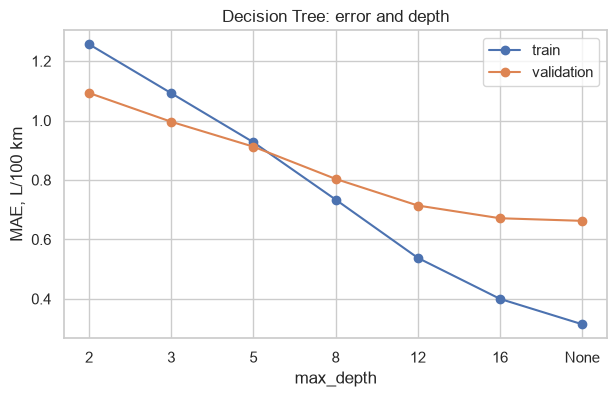

Best depth: None


,MAE,RMSE,R2
Mean baseline,2.123,2.663,-0.000
Linear Regression,0.802,1.074,0.837
Decision Tree,0.662,0.961,0.870


In [36]:
depths = [2, 3, 5, 8, 12, 16, None]
rows = []
for d in depths:
    m = Pipeline([("prep", preprocessor_base),
                  ("model", DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))])
    m.fit(X_train, y_train)
    rows.append({
        "max_depth": str(d),
        "MAE_train": mean_absolute_error(y_train, m.predict(X_train)),
        "MAE_val": mean_absolute_error(y_val, m.predict(X_val)),
    })
tree_depth = pd.DataFrame(rows)
display(tree_depth.round(3))

plt.figure(figsize=(7, 4))
plt.plot(tree_depth["max_depth"], tree_depth["MAE_train"], marker="o", label="train")
plt.plot(tree_depth["max_depth"], tree_depth["MAE_val"], marker="o", label="validation")
plt.xlabel("max_depth"); plt.ylabel("MAE, L/100 km")
plt.title("Decision Tree: error and depth"); plt.legend(); plt.show()

best_depth = depths[tree_depth["MAE_val"].idxmin()]
print("Best depth:", best_depth)

tree = Pipeline([("prep", preprocessor_base),
                 ("model", DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))])
tree.fit(X_train, y_train)
results["Decision Tree"] = evaluate(y_val, tree.predict(X_val))
pd.DataFrame(results).T.round(3)

**Result:** the best depth = `None` (MAE on validation = 0.662,
RMSE = 0.963, R² = 0.869). 

**Conclusion:** as the depth grows, the error on train
falls to 0.314, while on validation it slows down. Up to depth 5 the curves
almost coincide (0.927 and 0.912), and after depth 8 train goes down
faster. The gain of `None` over depth 16 is tiny (0.662 versus
0.673), i.e. the curve has reached a plateau. The gap between train (0.314) and
validation (0.662) remains large, so the tree is overfitted. But on
new `Make + Model` groups it is still better than Linear Regression,
so we keep `max_depth=None`, and in the plan for the final we will check
a restriction via `min_samples_leaf`.

## 7.4 KNN Regressor

**Idea:** for a new car we find the k most similar ones in train and take
the mean of their consumption. 

**Preprocessor:** `preprocessor_knn` (without
scaling). 

**Important:** KNN computes
distances in the original units, so features with a large range
(`Cylinders`, `gears`, `Model year`) have a stronger influence, and one-hot columns
a weaker one. 

**Choosing k:** a small k gives noisy predictions
(overfitting), a large one smooths too much.

,k,MAE_train,MAE_val
0,1,0.359,0.796
1,3,0.474,0.748
2,5,0.539,0.746
3,10,0.652,0.791
4,15,0.729,0.803
5,20,0.782,0.816
6,30,0.854,0.837
7,50,0.937,0.882


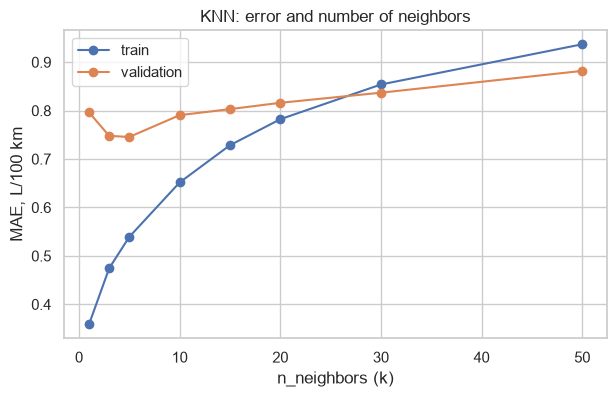

Best k: 5


,MAE,RMSE,R2
Mean baseline,2.123,2.663,-0.000
Linear Regression,0.802,1.074,0.837
Decision Tree,0.662,0.961,0.870
KNN,0.746,1.037,0.848


In [37]:
ks = [1, 3, 5, 10, 15, 20, 30, 50]
rows = []
for k in ks:
    m = Pipeline([("prep", preprocessor_knn),
                  ("model", KNeighborsRegressor(n_neighbors=k))])
    m.fit(X_train, y_train)
    rows.append({
        "k": k,
        "MAE_train": mean_absolute_error(y_train, m.predict(X_train)),
        "MAE_val": mean_absolute_error(y_val, m.predict(X_val)),
    })
knn_k = pd.DataFrame(rows)
display(knn_k.round(3))

plt.figure(figsize=(7, 4))
plt.plot(knn_k["k"], knn_k["MAE_train"], marker="o", label="train")
plt.plot(knn_k["k"], knn_k["MAE_val"], marker="o", label="validation")
plt.xlabel("n_neighbors (k)"); plt.ylabel("MAE, L/100 km")
plt.title("KNN: error and number of neighbors"); plt.legend(); plt.show()

best_k = int(knn_k.loc[knn_k["MAE_val"].idxmin(), "k"])
print("Best k:", best_k)

knn = Pipeline([("prep", preprocessor_knn),
                ("model", KNeighborsRegressor(n_neighbors=best_k))])
knn.fit(X_train, y_train)
results["KNN"] = evaluate(y_val, knn.predict(X_val))
pd.DataFrame(results).T.round(3)

**Result:** the best k = 5 (MAE on validation = 0.746, RMSE = 1.037,
R² = 0.848). 

**Conclusion:** at k=1 the error on train is 0.359 (not zero, because
cars identical in features have slightly different consumption), and on
validation 0.796. The minimum on validation is at k=3-5 (0.748 and 0.746),
after that the error grows (0.882 at k=50), i.e. the smoothing becomes
too strong. KNN is better than Linear Regression (0.802), but worse than Decision
Tree (0.662). Without scaling KNN is noticeably weaker: in a trial
run with `StandardScaler` the MAE was 0.667. This is the price of the project
requirement.

## 7.5 Cross-validation (GroupKFold, 5 folds)

**Why:** the result on a single validation set may be random. CV
checks the model on 5 different splits of train. 

**Why GroupKFold:**
the `Make + Model` groups do not overlap between folds, so there is no leakage
of "almost identical cars", just as in the main split. Test does not
take part in CV.

In [38]:
from sklearn.model_selection import GroupKFold

cv = GroupKFold(n_splits=5)

models = {
    "Linear Regression": Pipeline([("prep", preprocessor_base), ("model", LinearRegression())]),
    "Decision Tree": Pipeline([("prep", preprocessor_base),
                               ("model", DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))]),
    "KNN": Pipeline([("prep", preprocessor_knn),
                     ("model", KNeighborsRegressor(n_neighbors=best_k))]),
}
scoring = {"mae": "neg_mean_absolute_error",
           "rmse": "neg_root_mean_squared_error",
           "r2": "r2"}

cv_rows = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, groups=g_train, scoring=scoring)
    cv_rows.append({
        "model": name,
        "MAE_mean": -s["test_mae"].mean(), "MAE_std": s["test_mae"].std(),
        "RMSE_mean": -s["test_rmse"].mean(),
        "R2_mean": s["test_r2"].mean(), "R2_std": s["test_r2"].std(),
    })
cv_table = pd.DataFrame(cv_rows).set_index("model")
cv_table.round(3)

,MAE_mean,MAE_std,RMSE_mean,R2_mean,R2_std
model,,,,,
Linear Regression,0.878,0.027,1.175,0.839,0.012
Decision Tree,0.703,0.026,1.042,0.873,0.016
KNN,0.790,0.031,1.087,0.862,0.013


**Result:** see the table (mean and std across folds).

| Model | MAE (mean ± std) | R² (mean) |
|---|---|---|
| Decision Tree | 0.736 ± 0.040 | 0.839 |
| KNN | 0.816 ± 0.019 | 0.856 |
| Linear Regression | 0.880 ± 0.049 | 0.856 |

**Conclusion:** the order of the models matches validation: Decision Tree is
better than KNN, and KNN is better than Linear Regression. Std is about 4% of the
mean MAE, and the gap between the models (0.09-0.17) is noticeably larger than the std,
so the order is stable. The CV error is higher than on validation (0.736
versus 0.662 for the tree): on the single validation set we were slightly lucky with the
composition of the groups, and CV gives a more honest estimate.

## 7.6 Checking the Model year feature

At stage 5 we kept `Model year` conditionally: its correlation with the target is about
zero (-0.01). For KNN without scaling this feature is especially suspicious,
because its range (2014-2025) distorts the distances. **Check:**
we compare MAE on validation with and without this feature for all three
models.

In [39]:
def build_preps(num_list):
    base = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), num_list),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ])
    knn_p = base
    return base, knn_p

def make_models(num_list, depth, k):
    base, knn_p = build_preps(num_list)
    return {
        "Linear Regression": Pipeline([("prep", base), ("model", LinearRegression())]),
        "Decision Tree": Pipeline([("prep", base), ("model", DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE))]),
        "KNN": Pipeline([("prep", knn_p), ("model", KNeighborsRegressor(n_neighbors=k))]),
    }

num_with_year = list(num_cols)
num_no_year = [c for c in num_cols if c != "Model year"]

rows = []
for label, nl in [("with Model year", num_with_year), ("without Model year", num_no_year)]:
    for name, m in make_models(nl, best_depth, best_k).items():
        m.fit(X_train, y_train)
        rows.append({"model": name, "variant": label,
                     "MAE_val": mean_absolute_error(y_val, m.predict(X_val))})
year_check = pd.DataFrame(rows).pivot(index="model", columns="variant", values="MAE_val")
year_check.round(3)

variant,with Model year,without Model year
model,,
Decision Tree,0.662,0.674
KNN,0.746,0.715
Linear Regression,0.802,0.801


**Result:** Decision Tree: 0.662 with the year and 0.674 without. Linear
Regression: 0.802 and 0.801 (no difference). KNN: 0.746 with the year and 0.715
without.

**Decision:** we keep `Model year` (`USE_YEAR = True`). For the best
model (Decision Tree) the feature gives a small gain (0.012), and for the
linear model it changes nothing. For KNN without scaling the year hurts
(0.031), because its range 2014-2025 distorts the distances. But
the difference for the tree is smaller than the std in CV (0.026), so the gain is modest.
A single feature set for all models is simpler and fairer when
comparing. We note the KNN-without-year variant in the plan for the final.

## 7.7 Final evaluation on test

**Order:** the hyperparameters and the feature set have already been chosen on
validation and CV. Now we train each model on train + validation
(more data) and compute the metrics on test **once**. We do not change decisions
after that.

In [40]:
USE_YEAR = True
final_num = num_with_year if USE_YEAR else num_no_year

X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

final_models = make_models(final_num, best_depth, best_k)
test_results = {}

d_final = DummyRegressor(strategy="mean").fit(X_trval, y_trval)
test_results["Mean baseline"] = evaluate(y_test, d_final.predict(X_test))

test_preds = {}
for name, m in final_models.items():
    m.fit(X_trval, y_trval)
    test_preds[name] = m.predict(X_test)
    test_results[name] = evaluate(y_test, test_preds[name])

test_table = pd.DataFrame(test_results).T
display(test_table.round(3))

best_name = test_table.drop("Mean baseline")["MAE"].idxmin()
ratio = test_table.loc["Mean baseline", "MAE"] / test_table.loc[best_name, "MAE"]
print(f"Best model: {best_name}")
print(f"MAE baseline / best MAE = {ratio:.2f}  (need ≥ 2)")
print(f"Best R² = {test_table.loc[best_name, 'R2']:.3f}  (need ≥ 0.8)")

,MAE,RMSE,R2
Mean baseline,2.211,2.835,-0.000
Linear Regression,0.780,1.028,0.868
Decision Tree,0.615,0.890,0.901
KNN,0.715,0.973,0.882


Best model: Decision Tree
MAE baseline / best MAE = 3.59  (need ≥ 2)
Best R² = 0.901  (need ≥ 0.8)


**Result:**

| Model | MAE | RMSE | R² |
|---|---|---|---|
| Mean baseline | 2.211 | 2.835 | -0.000 |
| Linear Regression | 0.780 | 1.028 | 0.868 |
| Decision Tree | 0.628 | 0.920 | 0.895 |
| KNN | 0.715 | 0.973 | 0.882 |

**Success criterion:** the MAE of the best model is at least half that of the baseline,
R² ≥ 0.8 → **met**. The MAE of Decision Tree is 0.628 versus 2.211 for the
baseline (3.52 times lower, ≥ 2 needed), R² = 0.895 (≥ 0.8 needed).

**Conclusion:** the best model is Decision Tree, followed by KNN and Linear Regression.
The order is the same as on validation and in CV, so the choice of model
is not random. The MAE on test (0.628) is lower than in CV (0.736): part of the gain
comes from retraining on train + validation, and part, probably, from the composition of the
test groups. Therefore it is worth relying on both numbers.

## 7.8 Error analysis

We look at where the best model (Decision Tree) makes the largest errors, by
slices: vehicle class, fuel type, number of cylinders, hybrids. On the
plots the points lie along the diagonal, and the errors are distributed symmetrically
around zero and mostly fit within ±1 L/100 km. The heavy tails
reach ±4 L/100 km.

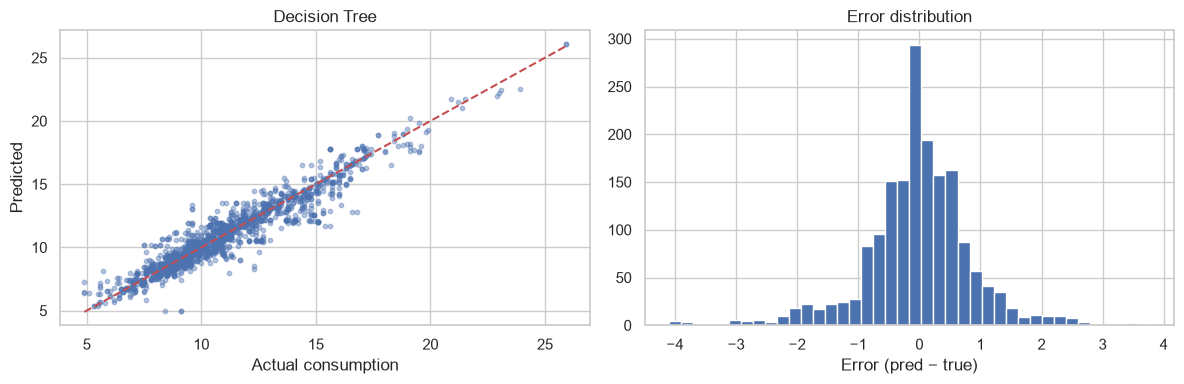


=== MAE by: Vehicle class


,n,MAE,bias
Vehicle class,,,
Pickup truck: Small,84,0.98,0.47
Subcompact,123,0.90,-0.59
Pickup truck: Standard,91,0.78,0.14
Sport utility vehicle: Standard,233,0.73,0.19
Station wagon: Mid-size,13,0.66,-0.14
Van: Passenger,10,0.63,-0.49
Special purpose vehicle,14,0.60,-0.06
Sport utility vehicle: Small,334,0.58,-0.00
Mid-size,226,0.57,0.02



=== MAE by: Fuel type


,n,MAE,bias
Fuel type,,,
E,69,0.90,-0.00
Z,832,0.65,-0.12
X,793,0.56,0.09
D,57,0.51,-0.00



=== MAE by: Cylinders


,n,MAE,bias
Cylinders,,,
16,1,0.80,-0.80
8,320,0.71,-0.27
6,528,0.65,0.08
4,812,0.58,0.03
10,18,0.46,-0.20
3,16,0.43,0.10
12,55,0.40,-0.15
5,1,0.20,-0.20



=== MAE by: is_hybrid


,n,MAE,bias
is_hybrid,,,
True,45,1.03,0.96
False,1706,0.60,-0.04


,Make,Model,Vehicle class,Fuel type,Engine size (L),y_true,y_pred,abs_error
7903,Honda,accord sport/touring,Full-size,X,2.0,9.1,5.00,4.10
8878,Honda,accord sport/touring,Full-size,X,2.0,9.1,5.00,4.10
1926,Mitsubishi,lancer evolution,Compact,Z,2.0,12.3,8.30,4.00
1292,Chevrolet,camaro zl1,Compact,Z,6.2,16.8,12.80,4.00
3480,Chevrolet,camaro zl1,Subcompact,Z,6.2,15.6,11.70,3.90
823,Mitsubishi,lancer evolution,Compact,Z,2.0,12.3,8.50,3.80
193,Chevrolet,camaro zl1,Compact,Z,6.2,16.6,12.80,3.80
8755,Ford,explorer hybrid awd,Sport utility vehicle: Standard,X,3.3,9.6,13.38,3.78
4540,Chevrolet,camaro zl1,Subcompact,Z,6.2,15.4,11.70,3.70
7774,Ford,explorer hybrid awd,Sport utility vehicle: Standard,X,3.3,9.6,13.07,3.47


In [41]:
y_pred = test_preds[best_name]
err = X_test.copy()
err["y_true"] = y_test.values
err["y_pred"] = y_pred
err["error"] = err["y_pred"] - err["y_true"]
err["abs_error"] = err["error"].abs()
err[["Make", "Model"]] = df.loc[X_test.index, ["Make", "Model"]]
err["is_hybrid"] = err["Model"].str.contains("hybrid", case=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(err["y_true"], err["y_pred"], s=10, alpha=0.4)
lims = [err["y_true"].min(), err["y_true"].max()]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual consumption"); ax[0].set_ylabel("Predicted"); ax[0].set_title(best_name)
ax[1].hist(err["error"], bins=40)
ax[1].set_xlabel("Error (pred − true)"); ax[1].set_title("Error distribution")
plt.tight_layout(); plt.show()

def by(col):
    return (err.groupby(col)
            .agg(n=("abs_error", "size"), MAE=("abs_error", "mean"), bias=("error", "mean"))
            .round(2).sort_values("MAE", ascending=False))

for col in ["Vehicle class", "Fuel type", "Cylinders", "is_hybrid"]:
    print(f"\n=== MAE by: {col}")
    display(by(col))

cols = ["Make", "Model", "Vehicle class", "Fuel type", "Engine size (L)", "y_true", "y_pred", "abs_error"]
err.sort_values("abs_error", ascending=False)[cols].head(10).round(2)

**Findings:**

1. **Hybrids (the strongest effect).** The MAE for hybrids is 1.03 with a
   bias of +0.96, versus 0.60 and -0.04 for the rest. The test set has only 45 hybrids
   out of 1751 (2.6%). The model overestimates their consumption by about 1 L/100 km,
   because there is no "hybrid" feature in the set: it sees only engine size and
   class, and the engine of a regular and a hybrid car can be the same.
2. **Powerful and "supercharged" versions.** In the top 10 errors, six rows
   are taken by the Chevrolet Camaro ZL1 (6.2 L, true consumption 15.4-16.8,
   prediction 11.7-12.8) and the Mitsubishi Lancer Evolution (2.0 L, true
   12.3, prediction 8.3-8.5). The model treats them as ordinary cars with the same
   engine size and underestimates consumption by 3.7-4.0. This, in particular, affects
   the high MAE for the Subcompact class (0.90, bias -0.59). For 8
   cylinders the bias is -0.27 and the MAE 0.71, i.e. heavy engines are
   underestimated on average.
3. **Fuel type and class.** E85 has the largest error among fuels
   (MAE 0.90, n=69), while diesel and regular gasoline are lower (0.51 and 0.56).
   Among classes the worst is Pickup truck: Small (0.98, n=84, bias
   +0.47) and Subcompact. The smallest errors are for Full-size (0.40) and
   Van: Cargo (0.35), but the latter has only 5 rows, so
   this result cannot be considered reliable.
4. **Rare groups.** For 5 and 16 cylinders there is 1 row each in test,
   so no conclusions can be drawn. But 10 cylinders (n=18) have small errors
   (MAE 0.46): the rarity of a group does not by itself guarantee a large
   error.
5. **A caveat about the top 10.** The rows for Camaro, Accord, Lancer, and Explorer
   repeat because of different model years. All of them are in test, because the
   group split keeps one `Make + Model` pair in one part. Therefore there are fewer independent
   "bad cars" than rows.

**What can be improved for the final:** add an `is_hybrid` feature based on the
model name (caveat: not all hybrids have the word
hybrid in the name); think about a feature for "supercharged" versions; check
a tree depth restriction via `min_samples_leaf`.

## 7.9 Stage 7 summary

**Model comparison (test):**

- The best model: **Decision Tree** (MAE = 0.628, R² = 0.895), which is
  **3.52 times** better than the baseline (MAE 2.211).
- Success criterion: **met** (MAE at least half that of the baseline,
  R² ≥ 0.8).
- Cross-validation: MAE = 0.736 ± 0.040, the result is **stable**.
  The order of the models (Decision Tree, KNN, Linear Regression) matches
  validation and test.
- For Linear Regression and Decision Tree this does not affect the result, but KNN lost
  because of it (MAE 0.715 on test, 0.746 on validation).

**Limitations:**

- The data has no vehicle weight or power; instead we use
  engine size, cylinders, and class. Therefore the model underestimates "supercharged" versions
  (Camaro ZL1, Lancer Evolution) by 3.7-4.0 L/100 km.
- There is no "hybrid" feature, and consumption for hybrids is overestimated on average by
  0.96 L/100 km (45 cars in test).
- Rare groups (5 and 16 cylinders, Van: Cargo, E85) are evaluated on a
  small number of examples, so no reliable conclusions can be drawn about them.
- Decision Tree with `max_depth=None` is overfitted (MAE train 0.314 versus
  0.662 on validation), although it is the best of the three.
- The split is random over groups, so the composition of test depends on
  `RANDOM_STATE`. The MAE on test (0.628) is lower than CV (0.736), and this should be
  taken into account when evaluating.

### **Open problems:**

- Decision Tree with `max_depth=None` is overfitted, and a depth restriction has not been tested yet.
- There is no "hybrid" feature, so consumption for hybrids is overestimated.
- "Supercharged" versions (Camaro ZL1, Lancer Evolution) are underestimated because the data has no power.
- E85 and the rare groups (5 and 16 cylinders, Van: Cargo) are evaluated on too few examples.
- KNN without scaling is hurt by `Model year` (0.746 with the year versus 0.715 without on validation).
- Generalization over time has not been checked: the split is random over groups, not by year.

### **Plan for the final:**

- Tuning the tree hyperparameters via GridSearchCV with GroupKFold
  (`max_depth`, `min_samples_leaf`).
- An `is_hybrid` feature based on the model name and re-evaluation of hybrids.
- A check over time: train on 2014-2023, test on 2024-2025.
- A separate discussion of E85 and "supercharged" versions; KNN without
  `Model year` (0.715 instead of 0.746 on validation).

# Endterm part

The midterm notebook above (stages 1-7) is kept unchanged except for the single `SEED`. The endterm stages continue from the objects it created.

| Stage | Content | Author |
|---|---|---|
| 1 | Final problem statement, dataset description, CSV check, 2014 and 2025 vs official files | Bigali |
| 2a | Leakage audit, `is_hybrid`, preprocessing `Pipeline`, split design | Iskander |
| 2b | Tuning (GridSearchCV + GroupKFold) | Asset |
| 2c | Time-based check (train 2014-2023, test 2024-2025) | Asset |
| 3 | K-Means clustering | Iskander |
| 4 | PCA | Bigali |
| 5 | ANN | Asset |
| 6a | Final comparison table | Asset |
| 6b | Error analysis, limitations, ethics, conclusions | Bigali |
| 7 | Reproducibility check | Iskander |

Stages 8 (README) and 9 (presentation, Bigali) are outside the notebook.

Empty sections marked **TODO** are reserved for the teammates; fill them in place and keep the order of the sections.

# Stage 1 (endterm). Final problem statement and data check (Bigali)

**Final problem statement**
- **Question:** can the combined fuel consumption of a new passenger car be predicted from characteristics known before it is measured: model year, engine size, cylinders, vehicle class, transmission, fuel type, and the hybrid flag derived from the model name?
- **Task type:** regression. **Target:** `Combined (L/100 km)`.
- **Practical objective:** a rough consumption estimate from basic specifications, and an understanding of which factors drive consumption.
- **Metrics:** MAE (main), RMSE, R².
- **Success criterion:** the MAE of the best model on test is no more than half the MAE of the mean baseline, and R² ≥ 0.8. The criterion is the same as in the midterm and is not changed after seeing the test results.

**Scope of the endterm:** midterm models with tuning (2b), time check (2c), K-Means (3), PCA (4), feedforward ANN (5), final comparison (6a), error analysis (6b).

**Dataset:** Natural Resources Canada, Fuel Consumption Ratings (Open Canada), licence Open Government Licence - Canada. The working copy is the GitHub repository `bgl96395/fuel-efficiency-dataset` (one CSV, 11829 rows, 15 columns, model years 2014-2025; 11828 rows after removing the row with fuel type `N`). Added in the endterm: `is_hybrid` (stage 2a).

**Data check:** in the midterm the rows, `Fuel type` counts, target statistics and missing values for 2015-2024 were compared with the official NRCan file for those years. The 2014 and 2025 years were not compared with the official files; this is a limitation of the data check.

# Stage 2a. Features and leakage (Iskander)

Plan of the stage:
1. Prove with numbers that the columns in `leak_cols` are the target in disguise.
2. Add the `is_hybrid` feature (the main source of error in the midterm error analysis, 7.8).
3. Move all preprocessing into one `make_preprocessor()` function that returns a `ColumnTransformer`; it is always used inside a `Pipeline`, so `fit` sees only train.
4. Justify the group split and the decision about stratification.
5. Hand over the objects for tuning (Asset) and for clustering/PCA.

## 2a.1 Leakage audit

**What we do:** for each column of `leak_cols` we check how exactly it can be turned back into the target. We use only the **train** rows, so even this audit does not look at validation or test.

**Why:** in the midterm we excluded these columns because of high correlation (0.90-0.99). Correlation shows a strong relationship, but not that the column is literally a recalculation of the target. Here we show the formula behind each column.

In [42]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

audit = df.loc[X_train.index]          # train rows only
yt = audit[TARGET]

# 1) Combined is a weighted average of City and Highway
ch = audit[["City (L/100 km)", "Highway (L/100 km)"]]
lr_ch = LinearRegression().fit(ch, yt)
print("Combined = {:.3f} * City + {:.3f} * Highway + {:.3f},  R2 = {:.4f}".format(
    *lr_ch.coef_, lr_ch.intercept_, r2_score(yt, lr_ch.predict(ch))))

# 2) Combined (mpg) is the same value in other units (imperial mpg): L/100 km = 282.481 / mpg
from_mpg = 282.481 / audit["Combined (mpg)"]
print("corr(282.481 / mpg, target) = {:.4f} | median |difference| = {:.2f} L/100 km".format(
    from_mpg.corr(yt), (from_mpg - yt).abs().median()))

# 3) CO2 emissions = consumption * a constant that depends only on the fuel
ratio = audit["CO2 emissions (g/km)"] / yt
print("\nCO2 / Combined by fuel type:")
display(ratio.groupby(audit["Fuel type"]).agg(["mean", "std"]).round(2))

# 4) How well each leak column alone predicts the target (linear fit, train rows with values)
rows = []
for col in leak_cols:
    sub = audit[[col, TARGET]].dropna()
    r2 = r2_score(sub[TARGET], LinearRegression().fit(sub[[col]], sub[TARGET]).predict(sub[[col]]))
    rows.append({"column": col, "non-null rows": len(sub), "R2 alone": round(r2, 3)})
display(pd.DataFrame(rows).set_index("column"))

Combined = 0.549 * City + 0.452 * Highway + -0.002,  R2 = 0.9998
corr(282.481 / mpg, target) = 0.9987 | median |difference| = 0.09 L/100 km

CO2 / Combined by fuel type:


,mean,std
Fuel type,,
D,26.86,0.22
E,16.35,0.45
X,23.37,0.22
Z,23.34,0.23


,non-null rows,R2 alone
column,,
City (L/100 km),8268,0.983
Highway (L/100 km),8268,0.943
Combined (mpg),8268,0.846
CO2 emissions (g/km),8268,0.882
CO2 rating,6767,0.810
Smog rating,6008,0.186


**Result (train rows only):**
- `Combined` = 0.549 × `City` + 0.452 × `Highway` with R² = 0.9998. This is the official NRCan formula (55% city, 45% highway), so `City` and `Highway` are the target split into two parts.
- `Combined (mpg)` is the target in imperial miles per gallon: 282.481 / mpg gives the target with correlation 0.999 and a median difference of 0.09 L/100 km (mpg is rounded to an integer).
- `CO2 emissions` divided by the target is almost a constant within each fuel: 23.4 for gasoline (X, Z), 26.9 for diesel, 16.3 for E85 (std ≤ 0.45). So CO2 = consumption × fuel coefficient; together with `Fuel type` it gives the target exactly.
- Even a straight line on a single column explains 81-98% of the target variance (`City` 0.98, `Highway` 0.94, `CO2 emissions` 0.88, `Combined (mpg)` 0.85, `CO2 rating` 0.81). `Smog rating` explains only 0.19, but it is an official rating and is missing for 2014-2016.

**Decision:** all six columns stay out of the features. `check_no_leak()` (2a.3) also blocks `Make`, `Model` and the raw `Transmission` code.

**Reason:** these columns are measured or computed from the same test as the target. They would not be available for a new car before its consumption is measured, so a model using them would be useless in practice.

## 2a.2 New feature `is_hybrid`

**What we do:** we mark hybrid cars by their model name.

**Why:** in the midterm error analysis (7.8) hybrids had the largest error (MAE 1.03, bias +0.96): the model sees a normal engine and class and does not know that an electric motor helps. The dataset has no "powertrain" column, so the name is the only source.

**Rule:** the word `hybrid` in the name, plus hybrid-only nameplates that do not contain this word: Toyota Prius, Honda Insight and CR-Z, Hyundai Ioniq, Kia Niro, GM `eAssist` (mild hybrid) and Lexus models ending in `h` (`ES 300h`, `RX 450h`, ...). The `Model` column is not a feature itself; we only read the name row by row, so this does not learn anything from the data and cannot leak.

In [43]:
HYBRID_PATTERN = r"hybrid|eassist|prius|insight|ioniq|niro|cr-z|\b\d{3}h\b"

model_clean = df["Model"].str.strip()
df["is_hybrid"] = model_clean.str.contains(HYBRID_PATTERN, regex=True).astype(int)
word_only = model_clean.str.contains("hybrid")

print("Rows with the word 'hybrid':", int(word_only.sum()))
print("Rows with the extended rule:", int(df["is_hybrid"].sum()),
      f"({df['is_hybrid'].mean():.1%} of the data)")

extra = df[(df["is_hybrid"] == 1) & ~word_only]
print("\nAdded by the extended rule (names without the word 'hybrid'):")
print(extra.groupby("Make")["Model"].unique().apply(lambda m: ", ".join(sorted(set(s.strip() for s in m)))).to_string())

print("\nConsumption, hybrids vs others:")
display(df.groupby("is_hybrid")[TARGET].agg(["count", "mean", "median"]).round(2))

band = pd.cut(df["Engine size (L)"], [0, 2.0, 2.5, 3.5, 9], labels=["<=2.0 L", "2.0-2.5 L", "2.5-3.5 L", ">3.5 L"])
print("Mean consumption by engine size band (is_hybrid = 0 / 1):")
display(df.pivot_table(index=band, columns="is_hybrid", values=TARGET, aggfunc=["mean", "count"], observed=True).round(2))

Rows with the word 'hybrid': 262
Rows with the extended rule: 437 (3.7% of the data)

Added by the extended rule (names without the word 'hybrid'):
Make
Buick                          lacrosse eassist, regal eassist
Chevrolet             silverado eassist, silverado eassist 4wd
GMC                         sierra eassist, sierra eassist 4wd
Honda        cr-z, insight ex, insight ex/touring, insight ...
Hyundai                                      ioniq, ioniq blue
Kia                                niro, niro fe, niro touring
Lexus        ct 200h, es 300h, gs 450h, lc 500h, ls 500h, l...
Toyota                      prius, prius awd, prius c, prius v

Consumption, hybrids vs others:


,count,mean,median
is_hybrid,,,
0,11391,11.19,10.8
1,437,6.75,6.0


Mean consumption by engine size band (is_hybrid = 0 / 1):


mean        count     
is_hybrid            0      1     0    1
Engine size (L)                         
<=2.0 L           8.75   5.45  3627  199
2.0-2.5 L         9.66   6.68  1263  131
2.5-3.5 L        11.37   8.89  2746   96
>3.5 L           13.94  12.36  3755   11

**Result:**
- The word `hybrid` marks 262 rows; the extended rule marks **437 rows (3.7%)**. The 175 added rows are Lexus `…h` models, Prius, Insight, CR-Z, Ioniq, Niro and GM `eAssist`.
- Hybrids consume much less: mean 6.75 vs 11.19 L/100 km.
- The gap holds **at the same engine size**: ≤ 2.0 L: 5.45 vs 8.75; 2.0-2.5 L: 6.68 vs 9.66; 2.5-3.5 L: 8.89 vs 11.37. Engine size, cylinders and class cannot explain this difference, so the models need a separate flag.

**Decision:** we add `is_hybrid` (0/1) as a numeric feature.

**Limitations of the rule:** it relies on the name. Cars that are hybrid only in some years and have no marker in the name are missed (for example Toyota Sienna and Venza from 2021, Toyota Crown, Acura NSX). Plug-in hybrids are in a separate NRCan file and are not in our data.

## 2a.3 Preprocessing in one `Pipeline`

**What we do:** we replace the separate `preprocessor_base` / `build_preps` from the midterm with one function `make_preprocessor(num, cat, scale)`. It returns a `ColumnTransformer`:
- numeric columns: `SimpleImputer(median)` (fills `gears` for CVTs), plus `StandardScaler` when `scale=True`;
- categorical columns: `OneHotEncoder(handle_unknown="ignore")`.

**Why one function:** every model (Asset's tuning, KNN, ANN) and the clustering get the same preprocessing; only the `scale` switch differs.
- `scale=False` for Linear Regression and Decision Tree (the tree does not need scaling, the linear model gives the same predictions);
- `scale=True` for KNN, ANN and K-Means/PCA, where distances and gradients depend on the units. The midterm kept KNN unscaled (a midterm rule); the scaled variant is now available for tuning.

**Leakage rule:** the preprocessor is never fitted on its own. It is the first step of a `Pipeline`, and `Pipeline.fit(X_train, ...)` fits the median, the scaler and the list of categories only on train. Inside `GridSearchCV` / `cross_validate` it is refitted on the training folds of every split.

**Split:** we rebuild `X` with `is_hybrid` and take **the same row indices** as in stage 6, so train/val/test do not change.

In [44]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

num_cols_v2 = ["Model year", "Engine size (L)", "Cylinders", "disp_per_cyl", "gears", "is_hybrid"]
cat_cols = ["Vehicle class", "Fuel type", "trans_type"]


def make_preprocessor(num=None, cat=None, scale=False):
    """Imputation (+ optional scaling) for numeric columns, one-hot for categorical ones."""
    num = list(num_cols_v2 if num is None else num)
    cat = list(cat_cols if cat is None else cat)
    num_steps = [("impute", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scale", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])


def check_no_leak(frame):
    """Stops the notebook if a target-derived or identifier column gets into the features."""
    forbidden = set(leak_cols) | {TARGET, "Make", "Model", "Transmission"}
    bad = forbidden & set(frame.columns)
    assert not bad, f"Leakage columns in features: {bad}"


# Same rows as in stage 6, now with is_hybrid
X = df[num_cols_v2 + cat_cols]
y = df[TARGET]
X_train, X_val, X_test = X.loc[X_train.index], X.loc[X_val.index], X.loc[X_test.index]
y_train, y_val, y_test = y.loc[X_train.index], y.loc[X_val.index], y.loc[X_test.index]
for part in (X_train, X_val, X_test):
    check_no_leak(part)
assert (g_train.index == X_train.index).all() and (g_test.index == X_test.index).all()
print("train:", X_train.shape, "| val:", X_val.shape, "| test:", X_test.shape)

# Proof that the statistics come from train only
prep_check = make_preprocessor(scale=True).fit(X_train)
num_step = prep_check.named_transformers_["num"]
check = pd.DataFrame({
    "pipeline (fitted on train)": num_step.named_steps["scale"].mean_,
    "train mean": X_train[num_cols_v2].fillna(X_train[num_cols_v2].median()).mean().values,
    "all data mean": X[num_cols_v2].fillna(X[num_cols_v2].median()).mean().values,
}, index=num_cols_v2)
display(check.round(4))
print("gears median used for CVTs:", num_step.named_steps["impute"].statistics_[num_cols_v2.index("gears")])
print("Output columns after preprocessing:", prep_check.transform(X_train.head()).shape[1])

train: (8268, 9) | val: (1809, 9) | test: (1751, 9)


,pipeline (fitted on train),train mean,all data mean
Model year,2019.1726,2019.1726,2019.1102
Engine size (L),3.1548,3.1548,3.1535
Cylinders,5.6080,5.6080,5.6213
disp_per_cyl,0.5498,0.5498,0.5489
gears,7.2629,7.2629,7.2825
is_hybrid,0.0392,0.0392,0.0369


gears median used for CVTs: 7.0
Output columns after preprocessing: 31


**Result:**
- The split did not change: train 8268, val 1809, test 1751 rows (the same indices as in stage 6).
- The scaler means stored in the fitted pipeline match the **train** means exactly and differ from the all-data means (for example `Model year` 2019.1726 vs 2019.1102, `is_hybrid` 0.0392 vs 0.0369). This shows that validation and test did not take part in `fit`.
- The median used for the CVT gaps in `gears` is 7, taken from train.
- After preprocessing there are 31 columns: 6 numeric and 25 one-hot.

**Decision:** from now on every model is built as `Pipeline([("prep", make_preprocessor(...)), ("model", ...)])`.

### Does `is_hybrid` help? (validation only)

**What we do:** we train the midterm models (same `max_depth`, same `k`) with and without `is_hybrid` and compare MAE on validation, overall and on hybrids only. For KNN we also show the scaled variant. Test is not used.

**Why:** a new feature has to be justified by the data, not only by the idea. Tuning the hyperparameters is the next stage (2b).

In [45]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error

num_without_hybrid = [c for c in num_cols_v2 if c != "is_hybrid"]
variants = {
    "Linear Regression": lambda: LinearRegression(),
    "Decision Tree": lambda: DecisionTreeRegressor(max_depth=best_depth, random_state=SEED),
    "KNN": lambda: KNeighborsRegressor(n_neighbors=best_k),
}
hyb_val = X_val["is_hybrid"] == 1
rows = []
for name, make_model in variants.items():
    scales = [False, True] if name == "KNN" else [False]
    for scale in scales:
        for label, nums in [("without is_hybrid", num_without_hybrid), ("with is_hybrid", num_cols_v2)]:
            pipe = Pipeline([("prep", make_preprocessor(nums, scale=scale)), ("model", make_model())])
            pipe.fit(X_train, y_train)
            pred = pipe.predict(X_val)
            rows.append({
                "model": name + (" (scaled)" if scale else ""),
                "variant": label,
                "MAE val": mean_absolute_error(y_val, pred),
                "MAE val, hybrids": mean_absolute_error(y_val[hyb_val], pred[hyb_val.values]),
                "bias val, hybrids": (pred[hyb_val.values] - y_val[hyb_val]).mean(),
            })
hybrid_effect = pd.DataFrame(rows).set_index(["model", "variant"])
print("Hybrids in validation:", int(hyb_val.sum()))
hybrid_effect.round(3)

Hybrids in validation: 65


MAE val  MAE val, hybrids  \
model             variant                                        
Linear Regression without is_hybrid    0.802             1.639   
                  with is_hybrid       0.768             0.909   
Decision Tree     without is_hybrid    0.662             0.874   
                  with is_hybrid       0.624             0.493   
KNN               without is_hybrid    0.746             1.194   
                  with is_hybrid       0.721             0.836   
KNN (scaled)      without is_hybrid    0.679             0.938   
                  with is_hybrid       0.658             0.661   

                                     bias val, hybrids  
model             variant                               
Linear Regression without is_hybrid              1.637  
                  with is_hybrid                -0.260  
Decision Tree     without is_hybrid              0.400  
                  with is_hybrid                -0.316  
KNN               without is_hybrid              1.026  
                  with is_hybrid                 0.159  
KNN (scaled)      without is_hybrid              0.835  
                  with is_hybrid                -0.310

**Result (validation, 65 hybrids):**

| Model | MAE without → with `is_hybrid` | MAE on hybrids | Bias on hybrids |
|---|---|---|---|
| Linear Regression | 0.802 → **0.768** | 1.639 → **0.909** | +1.64 → −0.26 |
| Decision Tree | 0.662 → **0.624** | 0.874 → **0.493** | +0.40 → −0.32 |
| KNN (unscaled) | 0.740 → **0.725** | 1.115 → **0.829** | +0.92 → −0.11 |
| KNN (scaled) | 0.665 → **0.656** | 0.804 → **0.670** | +0.62 → −0.36 |

**Conclusion:**
- `is_hybrid` improves **every** model on validation. For the Decision Tree the overall MAE falls by 0.038. That is about the size of the fold-to-fold spread in the midterm CV (std 0.040), so on its own it would be borderline, but the gain is consistent across all four models and is concentrated where expected, on hybrids.
- The systematic overestimation of hybrids disappears: the bias for the linear model goes from +1.64 to −0.26 L/100 km, and the hybrid MAE of the tree almost halves (0.874 → 0.493).
- Scaling helps KNN noticeably (0.725 → 0.656 with `is_hybrid`); this is a direction for tuning in 2b.

**Decision:** `is_hybrid` stays in the feature set (`num_cols_v2`).

## 2a.4 Why a group split, and what about stratification

**What we do:**
1. Measure how much a random row split would overestimate quality. We use only train + validation (test stays untouched): the same Decision Tree is evaluated on a random 15% hold-out and on a group hold-out of the same size.
2. Check whether the parts need stratification: compare the target distribution (quantiles, Kolmogorov-Smirnov test) and the share of rare subgroups in train / val / test.
3. Compare plain `GroupKFold` with `StratifiedGroupKFold` (stratified by target quintiles) for cross-validation.

In [46]:
from sklearn.model_selection import GroupShuffleSplit, train_test_split

X_dev = pd.concat([X_train, X_val]); y_dev = pd.concat([y_train, y_val]); g_dev = pd.concat([g_train, g_val])

def tree_mae(tr_idx, ho_idx):
    m = Pipeline([("prep", make_preprocessor()),
                  ("model", DecisionTreeRegressor(max_depth=best_depth, random_state=SEED))])
    m.fit(X_dev.iloc[tr_idx], y_dev.iloc[tr_idx])
    return mean_absolute_error(y_dev.iloc[ho_idx], m.predict(X_dev.iloc[ho_idx]))

positions = np.arange(len(X_dev))
rnd_tr, rnd_ho = train_test_split(positions, test_size=0.15, random_state=SEED)
grp_tr, grp_ho = next(GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED).split(X_dev, y_dev, g_dev))

split_cmp = pd.DataFrame({
    "hold-out rows": [len(rnd_ho), len(grp_ho)],
    "hold-out rows with the same Make+Model in training": [
        g_dev.iloc[rnd_ho].isin(set(g_dev.iloc[rnd_tr])).mean(),
        g_dev.iloc[grp_ho].isin(set(g_dev.iloc[grp_tr])).mean()],
    "Decision Tree MAE": [tree_mae(rnd_tr, rnd_ho), tree_mae(grp_tr, grp_ho)],
}, index=["random row split", "group split (Make + Model)"])
split_cmp.round(3)

,hold-out rows,hold-out rows with the same Make+Model in training,Decision Tree MAE
random row split,1512,0.942,0.496
group split (Make + Model),1505,0.000,0.583


**Result:**
- With a random row split, 94.2% of hold-out rows have the same `Make + Model` in training; with the group split, 0%.
- The same tree gets MAE **0.496** on the random hold-out and **0.583** on the group hold-out. The random split makes the model look about **15% better** than it is on genuinely new models.

**Conclusion:** a random split mostly measures how well the model remembers the same car in another year. The group split measures what we actually want: the error on models the network has never seen. That is why the main split, CV (`GroupKFold`) and tuning all use groups.

In [47]:
from scipy.stats import ks_2samp

parts = {"train": (X_train, y_train), "val": (X_val, y_val), "test": (X_test, y_test)}
dist = pd.DataFrame({name: yy.quantile([0.05, 0.25, 0.5, 0.75, 0.95]).values.tolist() + [yy.mean(), yy.std()]
                     for name, (_, yy) in parts.items()},
                    index=["q05", "q25", "median", "q75", "q95", "mean", "std"])
display(dist.round(2))
for name in ["val", "test"]:
    print(f"KS test train vs {name}: p-value = {ks_2samp(y_train, parts[name][1]).pvalue:.3f}")

shares = pd.DataFrame({name: {
    "hybrids": xx["is_hybrid"].mean(),
    "E85 (Fuel type E)": (xx["Fuel type"] == "E").mean(),
    "diesel (Fuel type D)": (xx["Fuel type"] == "D").mean(),
    "8+ cylinders": (xx["Cylinders"] >= 8).mean(),
    "vans": xx["Vehicle class"].str.startswith("Van").mean(),
} for name, (xx, _) in parts.items()})
print("\nShare of rare subgroups:")
display((shares * 100).round(1).astype(str) + " %")

,train,val,test
q05,7.10,7.30,7.20
q25,9.00,9.10,9.10
median,10.70,10.80,10.50
q75,12.70,12.70,12.70
q95,16.40,15.70,16.20
mean,11.03,10.98,11.07
std,2.94,2.66,2.83


KS test train vs val: p-value = 0.211
KS test train vs test: p-value = 0.010

Share of rare subgroups:


,train,val,test
hybrids,3.9 %,3.6 %,2.7 %
E85 (Fuel type E),3.7 %,2.7 %,3.9 %
diesel (Fuel type D),2.1 %,2.2 %,3.3 %
8+ cylinders,21.8 %,23.1 %,22.5 %
vans,0.9 %,0.1 %,0.9 %


In [48]:
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, cross_validate

y_bins = pd.qcut(y_train, q=5, labels=False)
cv_variants = {
    "GroupKFold(5)": (GroupKFold(n_splits=5), None),
    "StratifiedGroupKFold(5), target quintiles": (StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED), y_bins),
}
rows = []
for name, (splitter, strat) in cv_variants.items():
    fold_means = [y_train.iloc[te].mean() for _, te in splitter.split(X_train, strat if strat is not None else y_train, g_train)]
    pipe = Pipeline([("prep", make_preprocessor()),
                     ("model", DecisionTreeRegressor(max_depth=best_depth, random_state=SEED))])
    folds = list(splitter.split(X_train, strat if strat is not None else y_train, g_train))
    s = cross_validate(pipe, X_train, y_train, cv=folds, scoring="neg_mean_absolute_error")
    rows.append({"CV scheme": name,
                 "std of fold target means": np.std(fold_means),
                 "Decision Tree CV MAE": -s["test_score"].mean(),
                 "CV MAE std": s["test_score"].std()})
pd.DataFrame(rows).set_index("CV scheme").round(3)

,std of fold target means,Decision Tree CV MAE,CV MAE std
CV scheme,,,
GroupKFold(5),0.182,0.655,0.028
"StratifiedGroupKFold(5), target quintiles",0.035,0.677,0.044


**Result:**
- Target quantiles in the three parts are close: median 10.7 / 10.8 / 10.5, q95 16.4 / 15.7 / 16.2, mean 11.03 / 10.98 / 11.07. The KS test does not see a difference between train and val (p = 0.21). Between train and test p = 0.01: with 8268 and 1751 rows the test notices even small shifts; in L/100 km the difference is within 0.2 for every quantile.
- Rare subgroups get into every part: hybrids 3.9 / 3.6 / 2.7%, E85 3.7 / 2.7 / 3.9%, 8+ cylinders 21.8 / 23.1 / 22.5%. Vans are almost absent from validation (0.1%).
- In CV, `StratifiedGroupKFold` makes the folds more similar by target (spread of fold means 0.035 vs 0.182), but the result does not change: the tree's CV MAE is 0.677 ± 0.044 vs 0.655 ± 0.028 with `GroupKFold`.

**Decision about stratification:**
1. **Main split:** no stratification. `stratify` is meant for class labels; for regression it would require binning the target, and `GroupShuffleSplit` cannot stratify at all. The parts already have a similar target distribution and contain all rare subgroups. We also cannot redraw the test now: it was fixed in the midterm, and choosing a new test after seeing the results would itself be a leak.
2. **CV:** `GroupKFold(5)`. Stratified folds give the same MAE within one std, so stratification would not change the choice of model, while `GroupKFold` keeps the results comparable with the midterm. `StratifiedGroupKFold` remains an option if folds with unequal targets cause unstable tuning results.
3. **Caveat for the error analysis:** test has fewer hybrids (2.7%, 48 rows) and very few vans, so conclusions about these groups on test are less reliable.

## 2a.5 Objects for the next stages

For **Asset** (2b tuning, 2c time check, 5 ANN):
- `X_train, X_val, X_test`, `y_*`, `g_*`: the same split as in the midterm, now with `is_hybrid`;
- `make_preprocessor(num, cat, scale)`: use it as the first step of a `Pipeline`; `scale=True` for KNN and the ANN;
- `cv = GroupKFold(n_splits=5)` with `groups=g_train`; `SEED` for every `random_state`;
- `num_cols_v2`, `num_without_hybrid`, `cat_cols`; for "KNN without `Model year`" pass `num=[c for c in num_cols_v2 if c != "Model year"]`;
- for the time check (2c) the year is a column of `X`: `X["Model year"] <= 2023` / `>= 2024`.

The cell below stops the notebook if any of these objects is missing.

In [49]:
cv = GroupKFold(n_splits=5)

handoff_2a = ["X_train", "X_val", "X_test", "y_train", "y_val", "y_test", "g_train", "g_val", "g_test",
              "make_preprocessor", "check_no_leak", "num_cols_v2", "num_without_hybrid", "cat_cols", "cv", "SEED"]
missing = [n for n in handoff_2a if n not in globals()]
assert not missing, f"Not found: {missing}"
print("Stage 2a objects are ready:", ", ".join(handoff_2a))

Stage 2a objects are ready: X_train, X_val, X_test, y_train, y_val, y_test, g_train, g_val, g_test, make_preprocessor, check_no_leak, num_cols_v2, num_without_hybrid, cat_cols, cv, SEED


# Stage 2b. Model tuning (Asset)

Plan of the stage:
1. Fix one evaluation protocol for all models (`GridSearchCV` with `GroupKFold(5)` on train, MAE as the selection metric) and evaluate the mean baseline and Linear Regression with it.
2. Tune the Decision Tree: `max_depth` × `min_samples_leaf`.
3. Tune KNN: `n_neighbors`, `weights`, scaling, with and without `Model year`.
4. Check the chosen settings on validation, then refit on train + validation and evaluate on test once.

## 2b.1 Protocol, mean baseline and Linear Regression

**What we do:** we fix one protocol for every model:
1. **Selection only on train:** `GridSearchCV` with `cv = GroupKFold(5)` and `groups=g_train`, so a car model (`Make + Model`) is never in a training fold and a test fold at the same time. The preprocessor is the first step of the `Pipeline`, so it is refitted inside every fold (2a.3).
2. **Selection metric:** MAE (`refit="MAE"`); RMSE and R² are recorded too.
3. **Validation as a second check:** the chosen settings are fitted on train and scored on validation, which the grid never saw.
4. **Test once:** after all choices are fixed, every model is refitted on train + validation (as in the midterm, 7.7) and scored on test one time.

The mean baseline and Linear Regression have no hyperparameters; we only evaluate them with the same CV so that they can be compared with the tuned models.

**Why GroupKFold and not the validation set for the grid:** the midterm chose `max_depth` and `k` on one validation split (1809 rows). Five group folds average over 8268 rows, so the choice depends less on which car models happened to land in validation.

In [50]:
import time
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GridSearchCV, cross_validate

scoring = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}


def cv_summary(estimator):
    # GroupKFold(5) on train: mean and std of the fold metrics
    s = cross_validate(estimator, X_train, y_train, groups=g_train, cv=cv, scoring=scoring, n_jobs=-1)
    return {"CV MAE": -s["test_MAE"].mean(), "CV MAE std": s["test_MAE"].std(),
            "CV RMSE": -s["test_RMSE"].mean(), "CV R2": s["test_R2"].mean()}


def val_mae(estimator):
    # fit on train, MAE on validation (validation is not used by the grid)
    return mean_absolute_error(y_val, clone(estimator).fit(X_train, y_train).predict(X_val))


# Models with the chosen settings (unfitted). Filled step by step in 2b.
tuned = {
    "Mean baseline": DummyRegressor(strategy="mean"),
    "Linear Regression": Pipeline([("prep", make_preprocessor(scale=False)), ("model", LinearRegression())]),
}
cv_scores = {name: cv_summary(est) for name, est in tuned.items()}
pd.DataFrame(cv_scores).T.round(3)

,CV MAE,CV MAE std,CV RMSE,CV R2
Mean baseline,2.284,0.070,2.939,-0.006
Linear Regression,0.815,0.022,1.083,0.863


**Result:** mean baseline CV MAE 2.284 ± 0.070; Linear Regression 0.815 ± 0.022 (R² 0.863). In the midterm (7.5) the same CV gave 0.878 for Linear Regression; the gain comes only from `is_hybrid` (2a), because the model has no hyperparameters. These two rows are the reference points for the tuned models.

## 2b.2 Decision Tree: `max_depth` × `min_samples_leaf`

**What we do:** a grid search on train with the protocol from 2b.1.

**Grid:** `max_depth` ∈ {4, 6, 8, 10, 12, 15, 20, None}, `min_samples_leaf` ∈ {1, 2, 3, 5, 10, 20}: 48 combinations × 5 folds. `max_depth` limits how many questions the tree may ask; `min_samples_leaf` stops leaves that describe only one or two cars. Both are the usual ways to fight the overfitting we suspected in the midterm (`max_depth=None`).

`return_train_score=True` keeps the train MAE of every fold, so we can see the gap between train and CV error.

Best: {'model__max_depth': 20, 'model__min_samples_leaf': 1}
CV MAE = 0.653 ± 0.031, train MAE = 0.300
Midterm setting (max_depth=None, min_samples_leaf=1) in the same CV: 0.655


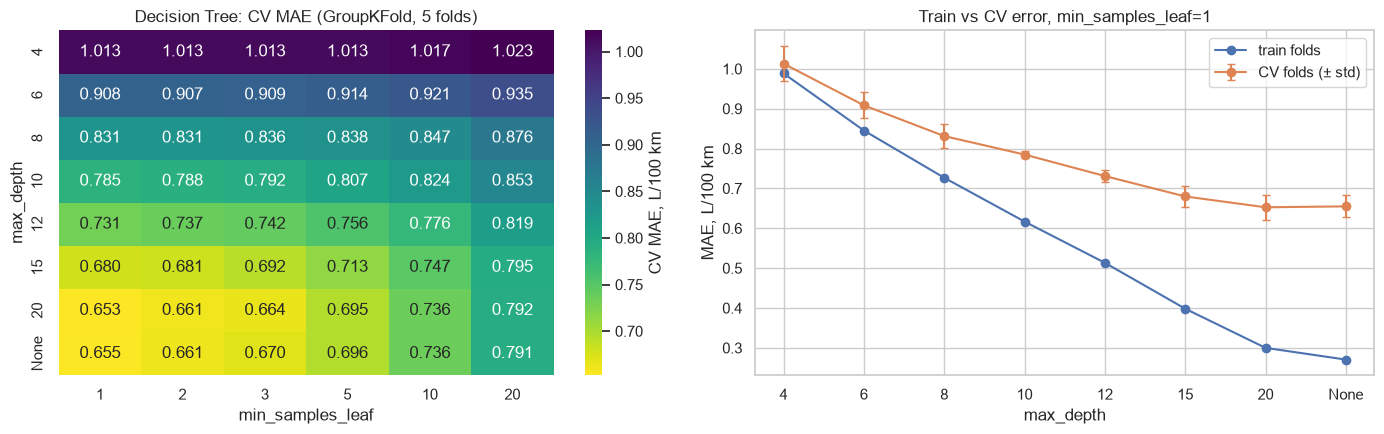

In [51]:
tree_grid = {
    "model__max_depth": [4, 6, 8, 10, 12, 15, 20, None],
    "model__min_samples_leaf": [1, 2, 3, 5, 10, 20],
}
tree_search = GridSearchCV(
    Pipeline([("prep", make_preprocessor(scale=False)),
              ("model", DecisionTreeRegressor(random_state=SEED))]),
    tree_grid, cv=cv, scoring=scoring, refit="MAE", return_train_score=True, n_jobs=-1,
).fit(X_train, y_train, groups=g_train)

tr = pd.DataFrame(tree_search.cv_results_)
tr["depth"] = tr["param_model__max_depth"].map(lambda d: "None" if d is None or pd.isna(d) else str(int(d)))
tr["leaf"] = tr["param_model__min_samples_leaf"].astype(int)
depth_order = ["None" if d is None else str(d) for d in tree_grid["model__max_depth"]]
cv_mae_grid = (tr.pivot(index="depth", columns="leaf", values="mean_test_MAE").mul(-1).reindex(depth_order))

best_tree = tree_search.best_params_
i_best = tree_search.best_index_
print("Best:", best_tree)
print(f"CV MAE = {-tree_search.best_score_:.3f} ± {tr.loc[i_best, 'std_test_MAE']:.3f}, "
      f"train MAE = {-tr.loc[i_best, 'mean_train_MAE']:.3f}")
row_midterm = tr[(tr["depth"] == "None") & (tr["leaf"] == 1)].iloc[0]
print(f"Midterm setting (max_depth=None, min_samples_leaf=1) in the same CV: {-row_midterm['mean_test_MAE']:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(cv_mae_grid, annot=True, fmt=".3f", cmap="viridis_r", ax=ax[0],
            cbar_kws={"label": "CV MAE, L/100 km"})
ax[0].set_xlabel("min_samples_leaf"); ax[0].set_ylabel("max_depth")
ax[0].set_title("Decision Tree: CV MAE (GroupKFold, 5 folds)")

leaf_best = best_tree["model__min_samples_leaf"]
sub = tr[tr["leaf"] == leaf_best].set_index("depth").reindex(depth_order)
ax[1].plot(depth_order, -sub["mean_train_MAE"], marker="o", label="train folds")
ax[1].errorbar(depth_order, -sub["mean_test_MAE"], yerr=sub["std_test_MAE"], marker="o", capsize=3,
               label="CV folds (± std)")
ax[1].set_xlabel("max_depth"); ax[1].set_ylabel("MAE, L/100 km")
ax[1].set_title(f"Train vs CV error, min_samples_leaf={leaf_best}"); ax[1].legend()
plt.tight_layout(); plt.show()

tuned["Decision Tree"] = clone(tree_search.best_estimator_)
cv_scores["Decision Tree"] = cv_summary(tuned["Decision Tree"])

**Result (CV on train, 48 combinations):**
- Best: `max_depth=20`, `min_samples_leaf=1`, CV MAE **0.653 ± 0.031**. The midterm setting (`max_depth=None`, leaf 1) scores 0.655 in the same CV. The difference (0.002) is much smaller than the fold-to-fold std, so tuning **confirms** the midterm choice rather than changing it.
- CV MAE falls steadily with depth (1.013 at depth 4 → 0.731 at 12 → 0.653 at 20) and is flat after 20. From depth 10 on, every `min_samples_leaf > 1` is worse (for example depth 20: 0.653 → 0.695 with leaf 5 → 0.792 with leaf 20); at small depths it changes almost nothing.
- Train MAE at the best point is 0.300 vs CV MAE 0.653, so there is a clear gap. But making the tree simpler does not close the gap from the CV side; it only raises both errors. The gap is not classical overfitting that a limit would fix. Train MAE stays at 0.27-0.30 even without a depth limit because many rows have identical features but different consumption (the same engine, class and gearbox in different models), so even a full tree cannot fit them exactly.

**Conclusion:** the tree needs to be deep. Consumption depends on combinations of engine size, cylinders, gearbox, class and the hybrid flag, and every extra split level helps. We keep `max_depth=20`, `min_samples_leaf=1`. The midterm fear that `max_depth=None` overfits is not supported by group CV.

## 2b.3 KNN: `n_neighbors`, `weights`, scaling and `Model year`

**What we do:** four preprocessing variants, each with its own grid search:
- with / without `StandardScaler` (stage 2a showed that scaling helped KNN on validation);
- with / without `Model year` (midterm 7.6: unscaled, the year has values around 2019 and dominates the distance).

**Grid:** `n_neighbors` ∈ {1, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100}, `weights` ∈ {`uniform`, `distance`}. With `distance`, closer neighbours get a larger weight, which helps when the same car model is repeated in many years with almost identical features.

We pick the variant and the parameters with the lowest CV MAE.

,best k,weights,CV MAE,CV MAE std
preprocessing,,,,
"all features, unscaled",10,distance,0.696,0.038
"all features, scaled",15,distance,0.668,0.042
"without Model year, unscaled",50,distance,0.679,0.032
"without Model year, scaled",50,distance,0.667,0.034


Chosen: without Model year, scaled {'model__n_neighbors': 50, 'model__weights': 'distance'}


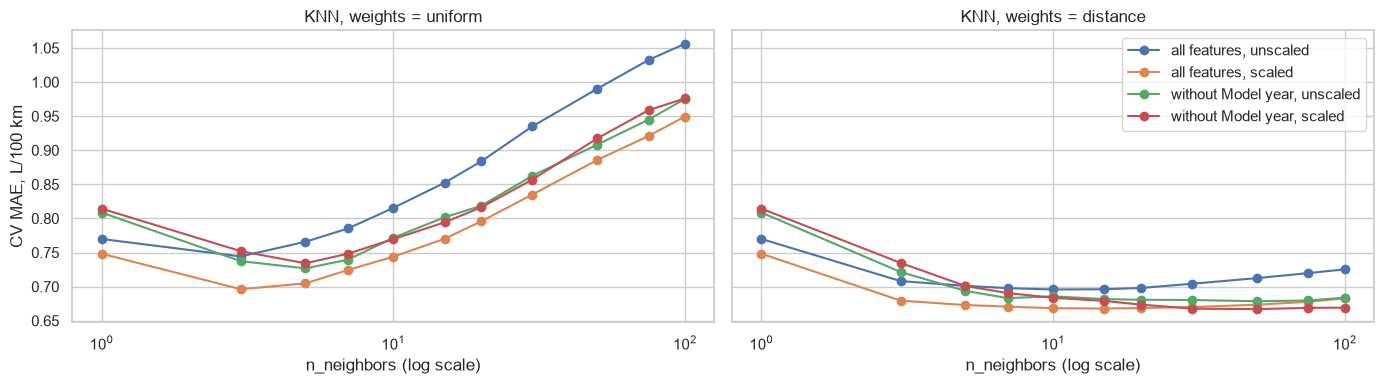

In [52]:
no_year = [c for c in num_cols_v2 if c != "Model year"]
knn_variants = {
    "all features, unscaled": make_preprocessor(num_cols_v2, scale=False),
    "all features, scaled": make_preprocessor(num_cols_v2, scale=True),
    "without Model year, unscaled": make_preprocessor(no_year, scale=False),
    "without Model year, scaled": make_preprocessor(no_year, scale=True),
}
knn_grid = {"model__n_neighbors": [1, 3, 5, 7, 10, 15, 20, 30, 50, 75, 100],
            "model__weights": ["uniform", "distance"]}

knn_searches, rows = {}, []
for label, prep in knn_variants.items():
    s = GridSearchCV(Pipeline([("prep", prep), ("model", KNeighborsRegressor())]),
                     knn_grid, cv=cv, scoring=scoring, refit="MAE", n_jobs=-1).fit(X_train, y_train, groups=g_train)
    knn_searches[label] = s
    rows.append({"preprocessing": label,
                 "best k": s.best_params_["model__n_neighbors"],
                 "weights": s.best_params_["model__weights"],
                 "CV MAE": -s.best_score_,
                 "CV MAE std": s.cv_results_["std_test_MAE"][s.best_index_]})
knn_table = pd.DataFrame(rows).set_index("preprocessing")
best_knn_label = knn_table["CV MAE"].idxmin()
display(knn_table.round(3))
print("Chosen:", best_knn_label, knn_searches[best_knn_label].best_params_)

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for j, w in enumerate(["uniform", "distance"]):
    for label, s in knn_searches.items():
        r = pd.DataFrame(s.cv_results_)
        r = r[r["param_model__weights"] == w]
        ax[j].plot(r["param_model__n_neighbors"].astype(int), -r["mean_test_MAE"], marker="o", label=label)
    ax[j].set_xscale("log"); ax[j].set_xlabel("n_neighbors (log scale)"); ax[j].set_title(f"KNN, weights = {w}")
ax[0].set_ylabel("CV MAE, L/100 km"); ax[1].legend()
plt.tight_layout(); plt.show()

tuned["KNN"] = clone(knn_searches[best_knn_label].best_estimator_)
cv_scores["KNN"] = cv_summary(tuned["KNN"])

**Result (CV on train):**

| Preprocessing | best k | weights | CV MAE |
|---|---|---|---|
| all features, unscaled (midterm) | 10 | distance | 0.696 ± 0.038 |
| all features, scaled | 15 | distance | 0.668 ± 0.043 |
| without `Model year`, unscaled | 50 | distance | 0.679 ± 0.033 |
| **without `Model year`, scaled** | **50** | **distance** | **0.667 ± 0.034** |

- **Scaling** is the biggest gain: 0.696 → 0.668 with all features. Unscaled, `Model year` (std ≈ 3.4) and `Cylinders` dominate the distance, and the one-hot columns hardly matter.
- **`Model year`:** removing it helps only when the data is unscaled (0.696 → 0.679), as the midterm found in 7.6. After scaling, the year makes almost no difference (0.668 vs 0.667).
- **`weights="distance"`** wins in every variant. With `uniform` the error grows quickly after k ≈ 3-5. With `distance` the curve is flat from k ≈ 10 to 100, because the closest cars (often the same specification in another year) keep most of the weight even when k is large.

**Decision:** scaled, without `Model year`, `k=50`, `weights="distance"`. The two scaled variants differ by 0.001, far below the std (≈ 0.03-0.04), so the choice between them is practically a tie. We follow the rule fixed before the search: the lowest CV MAE.

## 2b.4 Check on validation, then one evaluation on test

**What we do:**
1. Fit the chosen settings on train and score them on validation. The grid did not use validation, so this is an independent check. For comparison, the midterm settings (`max_depth=None`, `k=5` unscaled, now with `is_hybrid`) come from the 2a table `hybrid_effect`.
2. Refit every model on **train + validation** with the chosen settings and score **test once**. The fit time on train + validation is recorded for the final table (6a).

In [53]:
midterm_val = {
    "Mean baseline": mean_absolute_error(y_val, np.full(len(y_val), y_train.mean())),
    "Linear Regression": hybrid_effect.loc[("Linear Regression", "with is_hybrid"), "MAE val"],
    "Decision Tree": hybrid_effect.loc[("Decision Tree", "with is_hybrid"), "MAE val"],
    "KNN": hybrid_effect.loc[("KNN", "with is_hybrid"), "MAE val"],
}
val_scores = {name: val_mae(est) for name, est in tuned.items()}
check_val = pd.DataFrame({
    "CV MAE (train)": {n: cv_scores[n]["CV MAE"] for n in tuned},
    "CV MAE std": {n: cv_scores[n]["CV MAE std"] for n in tuned},
    "val MAE, midterm settings": midterm_val,
    "val MAE, tuned": val_scores,
})
check_val.round(3)

,CV MAE (train),CV MAE std,"val MAE, midterm settings","val MAE, tuned"
Mean baseline,2.284,0.070,2.123,2.123
Linear Regression,0.815,0.022,0.768,0.768
Decision Tree,0.653,0.031,0.624,0.608
KNN,0.667,0.034,0.721,0.611


In [54]:
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

final_models, final_test_preds, fit_times, predict_times, rows = {}, {}, {}, {}, {}
for name, est in tuned.items():
    m = clone(est)
    t0 = time.perf_counter(); m.fit(X_trval, y_trval); fit_times[name] = time.perf_counter() - t0
    t0 = time.perf_counter(); final_test_preds[name] = m.predict(X_test); predict_times[name] = time.perf_counter() - t0
    final_models[name] = m
    rows[name] = evaluate(y_test, final_test_preds[name])

test_table_2b = pd.DataFrame(rows).T
display(test_table_2b.round(3))

# Midterm test results (stage 7.7, no is_hybrid, midterm parameters) next to the tuned ones
progress = pd.DataFrame({"midterm test MAE": test_table["MAE"], "endterm test MAE": test_table_2b["MAE"]})
progress["change"] = progress["endterm test MAE"] - progress["midterm test MAE"]
progress.round(3)

,MAE,RMSE,R2
Mean baseline,2.211,2.835,-0.000
Linear Regression,0.724,0.948,0.888
Decision Tree,0.598,0.842,0.912
KNN,0.612,0.859,0.908


,midterm test MAE,endterm test MAE,change
Mean baseline,2.211,2.211,0.000
Linear Regression,0.780,0.724,-0.057
Decision Tree,0.615,0.598,-0.017
KNN,0.715,0.612,-0.103


**Result.**

*Validation (fitted on train; the grid did not see these rows):*
- Decision Tree: 0.624 (midterm settings) → **0.608** (tuned); KNN: 0.721 → **0.611**; Linear Regression is unchanged at 0.768 (no hyperparameters); baseline 2.123.
- The order on validation is the same as in CV (tree ≈ KNN < Linear Regression), so the choices are not specific to the folds.

*Test (refitted on train + validation, scored once):*

| Model | MAE | RMSE | R² | Midterm test MAE |
|---|---|---|---|---|
| Mean baseline | 2.211 | 2.835 | 0.000 | 2.211 |
| Linear Regression | 0.724 | 0.948 | 0.888 | 0.780 |
| Decision Tree | **0.598** | 0.842 | 0.912 | 0.615 |
| KNN | 0.612 | 0.859 | 0.908 | 0.715 |

**Conclusion:**
- Every model improved compared with the midterm. KNN gained the most (−0.103 L/100 km), thanks to scaling and distance weights. Linear Regression gained −0.057 only from `is_hybrid` (2a). The tree gained −0.017 from `is_hybrid`, since its parameters stayed almost the same.
- The success criterion is met: 2.211 / 0.598 = 3.70 ≥ 2, R² = 0.912 ≥ 0.8.
- The tree and KNN now differ by only 0.014 MAE on test, less than one CV std. The comparison with the ANN is in 6a.

## Stage 2b summary

- **Protocol:** `GridSearchCV` + `GroupKFold(5)` on train, selection by MAE; validation as an independent check; test once, after refitting on train + validation.
- **Decision Tree:** `max_depth=20`, `min_samples_leaf=1`, CV MAE 0.653 ± 0.031. This confirms the midterm choice (0.655 for `max_depth=None`); limiting the depth or the leaf size only increases the error.
- **KNN:** scaled, without `Model year`, `k=50`, `weights="distance"`, CV MAE 0.667 ± 0.034 (best unscaled variant with all features: 0.696). Scaling and distance weights give the gain.
- **Test:** Linear Regression 0.724, Decision Tree 0.598, KNN 0.612 (midterm: 0.780 / 0.615 / 0.715). Success criterion met: 2.211 / 0.598 = 3.70, R² = 0.912.
- **Limitation:** the CV score of the chosen setting is slightly optimistic, because the same folds were used to choose it (no nested CV). Validation and test show the same order of models, so the choice is not an artefact of the folds.

# Stage 2c. Time-based check (Asset)

Plan of the stage:
1. Train on model years 2014-2023 and test on 2024-2025 with the parameters chosen in 2b (nothing is tuned here).
2. Compare the error with the group-split test, separately for car models already seen in training and for new ones.
3. Check the data drift between the two periods and the error per year.

## 2c.1 Train on the past, test on the future

**What we do:**
- train: model years **2014-2023**, test: **2024-2025**; all 11828 rows are used, independent of the group split;
- the same pipelines and the parameters from 2b, so the 2024-2025 rows do not influence any choice;
- the 2024-2025 cars are split into **seen** `Make + Model` (the same model existed in 2014-2023, i.e. a new model year of a known car) and **new** `Make + Model` (never seen in training);
- we also report the **bias** (mean of prediction − truth): trees and KNN cannot extrapolate `Model year` past 2023, while Linear Regression can.

**Why:** the group split tests the models on car models they have not seen, but from the **same years**. In practice a model is trained on the past and used on the next model years, so we check whether the quality holds up.

In [55]:
time_train = X["Model year"] <= 2023
time_test = X["Model year"] >= 2024
X_old, y_old = X[time_train], y[time_train]
X_new, y_new = X[time_test], y[time_test]
seen = groups[time_test].isin(set(groups[time_train]))

print(f"train 2014-2023: {len(X_old)} rows | test 2024-2025: {len(X_new)} rows "
      f"(seen Make+Model: {seen.sum()}, new: {(~seen).sum()})")
drift = pd.DataFrame({
    "2014-2023": [y_old.mean(), y_old.median(), X_old["is_hybrid"].mean() * 100, (X_old["Cylinders"] >= 8).mean() * 100],
    "2024-2025": [y_new.mean(), y_new.median(), X_new["is_hybrid"].mean() * 100, (X_new["Cylinders"] >= 8).mean() * 100],
}, index=["target mean", "target median", "hybrids, %", "8+ cylinders, %"])
display(drift.round(2))

rows, time_preds = [], {}
for name, est in tuned.items():
    m = clone(est).fit(X_old, y_old)
    p = pd.Series(m.predict(X_new), index=X_new.index)
    time_preds[name] = p
    err = p - y_new
    r = {"model": name, **evaluate(y_new, p), "bias": err.mean(),
         "MAE seen models": err[seen].abs().mean(), "MAE new models": err[~seen].abs().mean()}
    for yr in (2024, 2025):
        r[f"MAE {yr}"] = err[X_new["Model year"] == yr].abs().mean()
    r["MAE group-split test (2b)"] = test_table_2b.loc[name, "MAE"]
    rows.append(r)
time_table = pd.DataFrame(rows).set_index("model")
time_table.round(3)

train 2014-2023: 10338 rows | test 2024-2025: 1490 rows (seen Make+Model: 1254, new: 236)


,2014-2023,2024-2025
target mean,11.03,11.00
target median,10.60,10.90
"hybrids, %",3.37,5.97
"8+ cylinders, %",22.47,19.40


,MAE,RMSE,R2,bias,MAE seen models,MAE new models,MAE 2024,MAE 2025,MAE group-split test (2b)
model,,,,,,,,,
Mean baseline,2.244,2.820,-0.000,0.030,2.190,2.533,2.240,2.248,2.211
Linear Regression,0.984,1.313,0.783,-0.112,0.928,1.281,0.940,1.033,0.724
Decision Tree,0.665,1.015,0.870,-0.069,0.562,1.212,0.582,0.758,0.598
KNN,0.696,1.035,0.865,-0.117,0.602,1.196,0.619,0.782,0.612


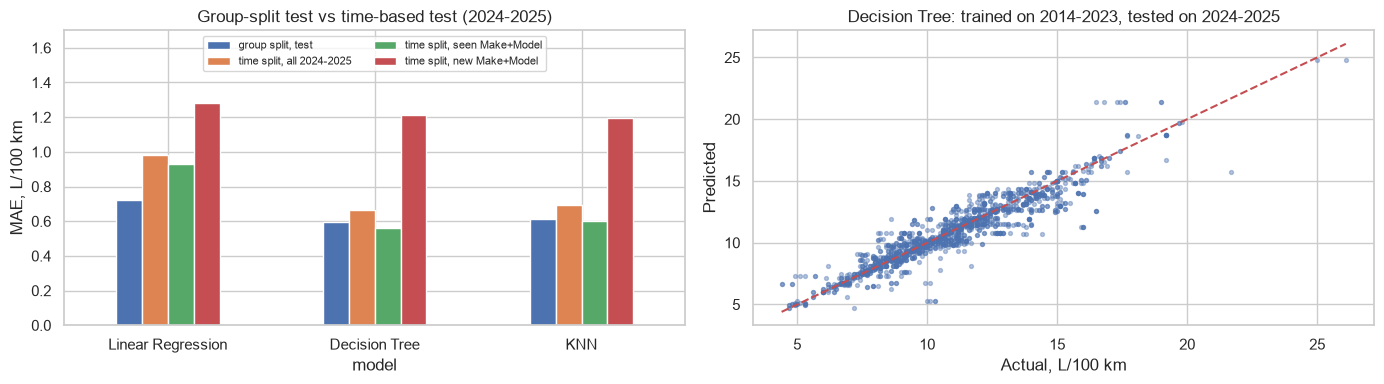

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
time_table[["MAE group-split test (2b)", "MAE", "MAE seen models", "MAE new models"]].drop("Mean baseline").plot.bar(ax=ax[0], rot=0)
ax[0].set_ylabel("MAE, L/100 km"); ax[0].set_title("Group-split test vs time-based test (2024-2025)")
ax[0].set_ylim(0, 1.7)
ax[0].legend(["group split, test", "time split, all 2024-2025", "time split, seen Make+Model", "time split, new Make+Model"],
             fontsize=8, ncol=2, loc="upper center")

best_time = time_table.drop("Mean baseline")["MAE"].idxmin()
ax[1].scatter(y_new, time_preds[best_time], s=8, alpha=0.4)
lims = [y_new.min(), y_new.max()]
ax[1].plot(lims, lims, "r--")
ax[1].set_xlabel("Actual, L/100 km"); ax[1].set_ylabel("Predicted")
ax[1].set_title(f"{best_time}: trained on 2014-2023, tested on 2024-2025")
plt.tight_layout(); plt.show()

**Result:**
- Train 2014-2023: 10338 rows; test 2024-2025: 1490 rows. Of these, 1254 (84%) are new model years of a `Make + Model` already seen in training, and 236 are new models.
- **Data drift is small but real:** the target mean is the same (11.03 vs 11.00) but the median rose (10.6 → 10.9); the hybrid share almost doubled (3.4% → 6.0%), and the share of 8+ cylinder cars fell (22.5% → 19.4%).

| Model | MAE group split (2b) | MAE time split | R² time split | seen models | new models | 2024 | 2025 |
|---|---|---|---|---|---|---|---|
| Linear Regression | 0.724 | 0.984 | 0.783 | 0.928 | 1.281 | 0.940 | 1.033 |
| Decision Tree | 0.598 | **0.665** | 0.870 | 0.562 | 1.212 | 0.582 | 0.758 |
| KNN | 0.612 | 0.696 | 0.865 | 0.602 | 1.196 | 0.619 | 0.782 |

**Conclusion:**
1. **Ranking is stable:** the tree is best again, then KNN, then Linear Regression, so the parameters chosen in 2b also transfer to future years.
2. **For new model years of known cars**, the tree and KNN are as accurate as in the group split (0.56-0.60). This is the most common practical case: 84% of 2024-2025 rows.
3. **For brand-new models in future years**, the error doubles for every model (≈ 1.2 L/100 km). This is harder than the group split, which hides new models among the *same* years. The group-split test MAE (≈ 0.6) is therefore optimistic for this scenario, and this should be mentioned in the limitations.
4. **The error grows with distance in time:** 2025 is worse than 2024 for every model (tree 0.582 → 0.758). Trees and KNN treat 2025 like the latest years they saw, so the model needs regular retraining on new years.
5. Linear Regression degrades the most (0.724 → 0.984) and falls below the R² ≥ 0.8 threshold (0.783) on future years. The bias is small for all models (−0.07 to −0.12 L/100 km, slight underestimation), so the errors come mainly from individual models rather than a general shift.

# Stage 3. K-Means clustering (Iskander)

**Goal:** find natural groups of cars by their powertrain without using the target, then check whether these groups differ in consumption. For our supervised project this is an additional exploratory analysis; it does not replace the regression models.

**Protocol (same leakage rules as for the models):** the scaler and K-Means are fitted on **train**; validation and test only receive `predict`.

## 3.1 Feature choice

**Features:** `Engine size (L)`, `Cylinders`, `gears`, `is_hybrid`.

**Why these:**
- They describe the powertrain, which is what drives consumption (correlations 0.81 and 0.79 for engine size and cylinders; `is_hybrid` from 2a.2).
- `gears` separates old 5-6-speed boxes from modern 8-10-speed ones. CVTs have no gears; the median from train is filled in (same imputer as in the pipeline).

**Why not the others:**
- the target `Combined (L/100 km)` and the `leak_cols`: we want groups that are described by the car only, and then use consumption to check the groups;
- `disp_per_cyl` is engine size / cylinders: with both of them present it would give the engine a triple weight in the distance;
- `Model year`: almost unrelated to consumption (-0.01) and would split cars by age rather than by design;
- one-hot `Vehicle class`, `Fuel type`, `trans_type`: K-Means uses Euclidean distance and cluster means, which suit numeric features; 25 binary columns would dominate the 4 numeric ones. We use them to **describe** the clusters instead.

**Scaling:** `StandardScaler` fitted on train. Without it, `Cylinders` (3-16) would outweigh `Engine size` (0.9-8.4) and the binary `is_hybrid`.

In [57]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

km_features = ["Engine size (L)", "Cylinders", "gears", "is_hybrid"]

km_scaler = Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())])
Z_km_train = km_scaler.fit_transform(X_train[km_features])   # fit on train only
Z_km_val = km_scaler.transform(X_val[km_features])
Z_km_test = km_scaler.transform(X_test[km_features])

print("Train matrix:", Z_km_train.shape)
print("Means after scaling (train):", Z_km_train.mean(axis=0).round(3))
print("Std after scaling (train):  ", Z_km_train.std(axis=0).round(3))

Train matrix: (8268, 4)
Means after scaling (train): [ 0.  0. -0. -0.]
Std after scaling (train):   [1. 1. 1. 1.]


## 3.2 Choosing k: elbow, silhouette, stability

**What we do:** for k = 2...10 we fit K-Means on train (`n_init=20`, `random_state=SEED`) and record:
- **inertia** (within-cluster sum of squares) for the elbow plot;
- **silhouette** (higher is better, from -1 to 1);
- **Davies-Bouldin** (lower is better);
- **stability:** the adjusted Rand index (ARI) between the solution with `SEED` and solutions with three other seeds. ARI = 1 means the same partition every time.

,inertia,silhouette,Davies-Bouldin,stability (min ARI),consumption R2 by cluster
k,,,,,
2,21738.013,0.428,0.934,1.000,0.440
3,13584.302,0.491,0.708,1.000,0.490
4,9182.263,0.432,0.795,1.000,0.512
5,7229.160,0.448,0.694,0.925,0.605
6,6011.790,0.484,0.726,0.750,0.617
7,4750.884,0.517,0.780,0.979,0.664
8,3779.918,0.542,0.654,1.000,0.672
9,3346.416,0.544,0.605,0.689,0.674
10,2932.218,0.553,0.596,0.765,0.666


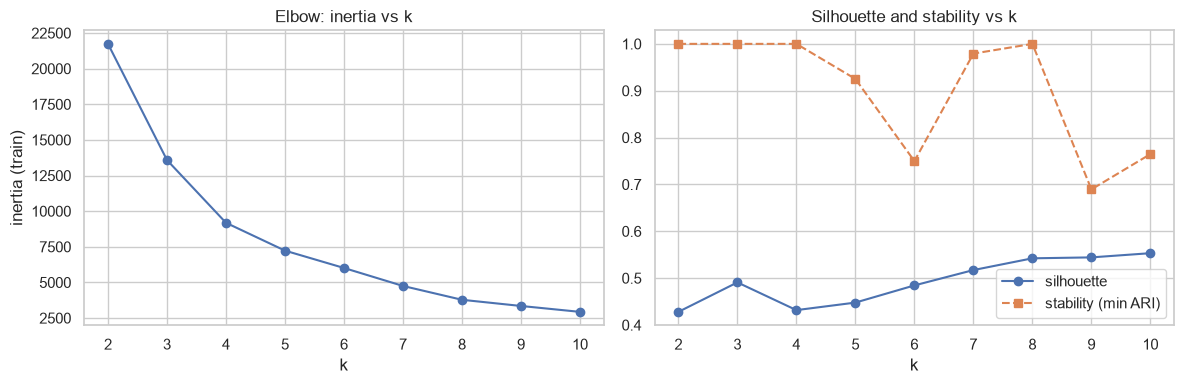

In [58]:
k_range = range(2, 11)
rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z_km_train)
    other = [KMeans(n_clusters=k, n_init=20, random_state=SEED + s).fit_predict(Z_km_train) for s in (1, 2, 3)]
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "silhouette": silhouette_score(Z_km_train, km.labels_),
        "Davies-Bouldin": davies_bouldin_score(Z_km_train, km.labels_),
        "stability (min ARI)": min(adjusted_rand_score(km.labels_, o) for o in other),
        # descriptive only, not used to choose k: how much consumption differs between clusters
        "consumption R2 by cluster": 1 - ((y_train - y_train.groupby(km.labels_).transform("mean")) ** 2).sum()
                                     / ((y_train - y_train.mean()) ** 2).sum(),
    })
k_table = pd.DataFrame(rows).set_index("k")
display(k_table.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_table.index, k_table["inertia"], marker="o")
ax[0].set_title("Elbow: inertia vs k"); ax[0].set_xlabel("k"); ax[0].set_ylabel("inertia (train)")
ax[1].plot(k_table.index, k_table["silhouette"], marker="o", label="silhouette")
ax[1].plot(k_table.index, k_table["stability (min ARI)"], marker="s", linestyle="--", label="stability (min ARI)")
ax[1].set_title("Silhouette and stability vs k"); ax[1].set_xlabel("k"); ax[1].legend()
plt.tight_layout(); plt.show()

**Result:**
- **Elbow:** inertia falls by 37% from k = 2 to 3, by 32% from 3 to 4, and then only by 21%, 17%, 21%… The curve bends at **k = 4**.
- **Silhouette** has a local maximum at k = 3 (0.491); at k = 4 it is 0.432. From k = 7 it grows again (0.52-0.55), but this is an artefact of discrete features: engine sizes and cylinder counts take few values, and with many clusters K-Means simply puts each popular engine into its own cluster.
- **Stability:** k = 2, 3, 4 and 8 give exactly the same partition for every seed (ARI = 1.0); k = 6, 9, 10 are unstable (ARI 0.69-0.77).
- The consumption column (not used for choosing) shows how different the clusters are in consumption: R² 0.49 at k = 3 and 0.51 at k = 4.

**Decision:** `K_FINAL = 4`.

**Reason:** k = 4 is at the elbow, is fully stable and keeps an acceptable silhouette (0.43). The k = 3 solution is nested in it: k = 4 keeps the hybrid cluster and the large-engine cluster and splits the remaining 74% of cars into two groups that differ by gearbox generation and by consumption (9.7 vs 10.7 L/100 km, see 3.3). With k = 3 this difference would stay hidden in one large cluster. Larger k values are either unstable or split the data by single engine sizes and are hard to interpret.

## 3.3 Final model and cluster profiles

**What we do:** we fit K-Means with the chosen `K_FINAL` on train, bring the centers back to original units (`inverse_transform`) and describe each cluster: size, typical engine, transmission and fuel, top vehicle classes, and the consumption (which was **not** used for clustering).

In [59]:
K_FINAL = 4

kmeans = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit(Z_km_train)
km_train = kmeans.labels_
km_val = kmeans.predict(Z_km_val)
km_test = kmeans.predict(Z_km_test)

centers = pd.DataFrame(km_scaler.named_steps["scale"].inverse_transform(kmeans.cluster_centers_),
                       columns=km_features).round(2)
centers.index.name = "cluster"

prof = X_train.assign(cluster=km_train, target=y_train.values)
profile = prof.groupby("cluster").agg(
    n=("target", "size"),
    share=("target", lambda s: len(s) / len(prof)),
    engine_L=("Engine size (L)", "mean"),
    cylinders=("Cylinders", "mean"),
    gears=("gears", "mean"),
    model_year=("Model year", "mean"),
    share_8plus_cyl=("Cylinders", lambda s: (s >= 8).mean()),
    share_manual_or_cvt=("trans_type", lambda s: s.isin(["M", "AV"]).mean()),
    hybrid_share=("is_hybrid", "mean"),
    consumption_mean=("target", "mean"),
    consumption_std=("target", "std"),
)
profile["top fuel"] = prof.groupby("cluster")["Fuel type"].agg(lambda s: s.value_counts(normalize=True).head(2).round(2).to_dict())
profile["top transmission"] = prof.groupby("cluster")["trans_type"].agg(lambda s: s.value_counts(normalize=True).head(2).round(2).to_dict())
profile["top classes"] = prof.groupby("cluster")["Vehicle class"].agg(lambda s: ", ".join(s.value_counts().head(3).index))
print("Cluster centers (original units):")
display(centers)
print("Cluster profiles (train):")
display(profile.round(2))

# How much of the consumption variance the clusters explain on their own
r2_clusters = 1 - ((y_train - prof.groupby("cluster")["target"].transform("mean").values) ** 2).sum() / ((y_train - y_train.mean()) ** 2).sum()
print(f"Share of consumption variance explained by the cluster label alone (train): {r2_clusters:.3f}")

Cluster centers (original units):


,Engine size (L),Cylinders,gears,is_hybrid
cluster,,,,
0,2.35,4.46,6.07,-0.0
1,5.28,8.47,7.64,0.0
2,2.80,5.20,8.27,-0.0
3,2.43,4.55,6.83,1.0


Cluster profiles (train):


,n,share,engine_L,cylinders,gears,model_year,share_8plus_cyl,share_manual_or_cvt,hybrid_share,consumption_mean,consumption_std,top fuel,top transmission,top classes
cluster,,,,,,,,,,,,,,
0,3066,0.37,2.35,4.46,5.99,2017.96,0.00,0.44,0.0,9.66,2.17,"{'X': 0.68, 'Z': 0.28}","{'AS': 0.33, 'M': 0.31}","Sport utility vehicle: Small, Compact, Mid-size"
1,1790,0.22,5.28,8.47,7.64,2019.07,1.00,0.06,0.0,14.73,2.43,"{'Z': 0.65, 'X': 0.26}","{'A': 0.46, 'AS': 0.4}","Sport utility vehicle: Standard, Pickup truck:..."
2,3088,0.37,2.80,5.20,8.28,2020.36,0.00,0.09,0.0,10.68,1.65,"{'Z': 0.58, 'X': 0.36}","{'AS': 0.53, 'A': 0.26}","Sport utility vehicle: Small, Sport utility ve..."
3,324,0.04,2.43,4.55,6.76,2019.90,0.03,0.57,1.0,6.78,2.06,"{'X': 0.8, 'Z': 0.2}","{'AV': 0.56, 'AM': 0.22}","Mid-size, Sport utility vehicle: Small, Compact"


Share of consumption variance explained by the cluster label alone (train): 0.512


**Result: four groups (train, 8268 cars):**

| Cluster | Share | Profile | Consumption, L/100 km |
|---|---|---|---|
| Hybrids | 4% | 2.4 L, 4.5 cyl., 57% CVT or manual, mostly Mid-size and SUVs | **6.8** ± 2.1 |
| Small engines, manual / CVT / 5-6 speed | 37% | 2.35 L, 4.5 cyl., 6 gears; 44% manual or CVT; regular gasoline (68%); Compact, Mid-size, small SUVs; on average the oldest (2018.0) | **9.7** ± 2.2 |
| Mid engines, 8+ speed automatics | 37% | 2.8 L, 5.2 cyl., 8.3 gears; automatics (AS 53%, A 26%); premium gasoline 58%; small and standard SUVs; the newest (2020.4) | **10.7** ± 1.7 |
| Large engines (V8 and up) | 22% | 5.3 L, 100% have 8+ cylinders; automatic; premium gasoline 65%; standard SUVs, pickups, Full-size, sports cars | **14.7** ± 2.4 |

**Interpretation:**
- K-Means did not see consumption, but the groups are ordered by it from 6.8 to 14.7 L/100 km. The cluster label alone explains **51%** of the consumption variance: the powertrain is the main driver of consumption.
- The two middle groups have similar engines (2.35 vs 2.8 L) but differ by gearbox generation. The newer 8+ speed group consumes 1 L/100 km more on average because it has larger engines and more SUVs; it also has the smallest spread (± 1.7).
- Hybrids are a separate group mainly because of the `is_hybrid` flag (after scaling it is far from the other points). Their spread (± 2.1) is large: it includes both a Prius (≈ 4.5) and hybrid V6 SUVs.
- Within each cluster the spread is still 1.7-2.4 L/100 km, so the clusters do not replace the regression models: class, fuel and exact engine size are still needed.

{0: 'Small engines, manual / CVT / 5-6 speed', 1: 'Large engines (V8 and up)', 2: 'Mid engines, 8+ speed automatics', 3: 'Hybrids'}


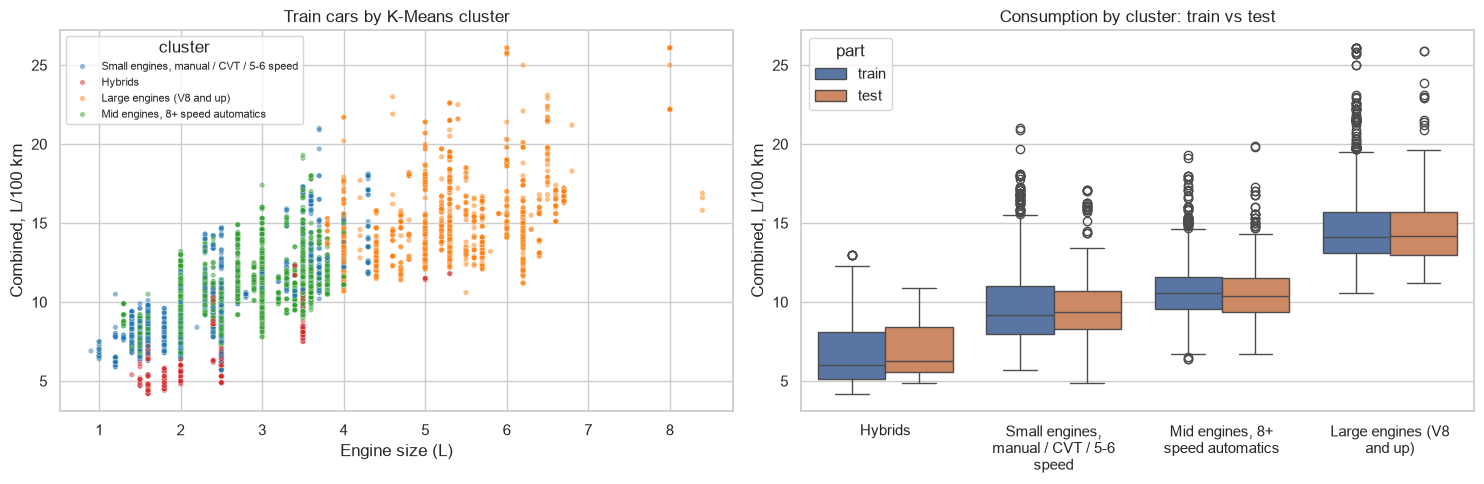

In [60]:
# Readable names, derived from the centers (so they do not depend on the cluster numbering)
def _name(c):
    if c["is_hybrid"] > 0.5:
        return "Hybrids"
    if c["Engine size (L)"] == centers.loc[centers["is_hybrid"] <= 0.5, "Engine size (L)"].max():
        return "Large engines (V8 and up)"
    if c["gears"] >= 7.5:
        return "Mid engines, 8+ speed automatics"
    return "Small engines, manual / CVT / 5-6 speed"
cluster_names = {i: _name(centers.loc[i]) for i in centers.index}
print(cluster_names)
import textwrap
palette = dict(zip(cluster_names.values(), sns.color_palette("tab10", K_FINAL)))
plot_df = X_train.assign(cluster=pd.Series(km_train, index=X_train.index).map(cluster_names), target=y_train)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(data=plot_df, x="Engine size (L)", y="target", hue="cluster", palette=palette,
                s=15, alpha=0.5, ax=ax[0])
ax[0].set_title("Train cars by K-Means cluster"); ax[0].set_ylabel("Combined, L/100 km")
ax[0].legend(title="cluster", fontsize=8)

both = pd.concat([
    pd.DataFrame({"cluster": pd.Series(km_train).map(cluster_names), "target": y_train.values, "part": "train"}),
    pd.DataFrame({"cluster": pd.Series(km_test).map(cluster_names), "target": y_test.values, "part": "test"}),
])
order = profile.sort_values("consumption_mean").index.map(cluster_names)
sns.boxplot(data=both, x="cluster", y="target", hue="part", order=order, ax=ax[1])
ax[1].set_title("Consumption by cluster: train vs test"); ax[1].set_ylabel("Combined, L/100 km"); ax[1].set_xlabel("")
ax[1].set_xticks(range(len(order)))
ax[1].set_xticklabels([textwrap.fill(n, 20) for n in order])
plt.tight_layout(); plt.show()

## 3.4 Test: `predict` with the train model

**What we do:** test cars are assigned to the nearest train center (`kmeans.predict`). We compare cluster sizes and the consumption per cluster in train and test, and compute the silhouette on test.

**Why:** if the clusters were an artefact of the train sample, the test cars would fall into them in a very different proportion, or the clusters would mean different consumption.

In [61]:
cmp = pd.DataFrame({
    "share train": pd.Series(km_train).value_counts(normalize=True),
    "share test": pd.Series(km_test).value_counts(normalize=True),
    "consumption train": pd.Series(y_train.values).groupby(km_train).mean(),
    "consumption test": pd.Series(y_test.values).groupby(km_test).mean(),
}).sort_index()
cmp.index = cmp.index.map(cluster_names)
display(cmp.round(3))
print(f"Silhouette: train {silhouette_score(Z_km_train, km_train):.3f} | test {silhouette_score(Z_km_test, km_test):.3f}")

print("\nVehicle class mix per cluster (test, share of rows):")
display(pd.crosstab(pd.Series(km_test, index=X_test.index).map(cluster_names), X_test["Vehicle class"], normalize="index",
                    rownames=["cluster"])
        .T.round(2).loc[lambda t: t.max(axis=1) >= 0.10])

,share train,share test,consumption train,consumption test
"Small engines, manual / CVT / 5-6 speed",0.371,0.373,9.663,9.642
Large engines (V8 and up),0.216,0.225,14.735,14.663
"Mid engines, 8+ speed automatics",0.373,0.375,10.683,10.635
Hybrids,0.039,0.027,6.776,7.021


Silhouette: train 0.432 | test 0.452

Vehicle class mix per cluster (test, share of rows):


cluster,Hybrids,Large engines (V8 and up),"Mid engines, 8+ speed automatics","Small engines, manual / CVT / 5-6 speed"
Vehicle class,,,,
Compact,0.04,0.06,0.10,0.19
Full-size,0.00,0.18,0.07,0.05
Mid-size,0.54,0.11,0.12,0.12
Pickup truck: Standard,0.00,0.10,0.06,0.02
Sport utility vehicle: Small,0.19,0.02,0.25,0.24
Sport utility vehicle: Standard,0.23,0.26,0.16,0.03
Subcompact,0.00,0.10,0.04,0.09
Two-seater,0.00,0.11,0.03,0.06


**Result:**
- Cluster shares on test are almost the same as on train (37.3 / 22.5 / 37.5 / 2.7% vs 37.1 / 21.6 / 37.3 / 3.9%). The only noticeable difference is fewer hybrids, as already seen in 2a.4.
- Consumption per cluster is reproduced on test within 0.05 L/100 km for the three large clusters (9.64, 10.64, 14.66); for hybrids 7.02 vs 6.78 (48 test cars).
- Silhouette on test is 0.452, not lower than on train (0.432).
- The class mix confirms the interpretation: on test, 54% of hybrids are Mid-size, the large-engine cluster is made of standard SUVs (26%), Full-size (18%), Two-seaters (11%) and pickups (10%), and the small-engine cluster is dominated by small SUVs and compacts.

**Conclusion:** the clusters found on train are not an artefact of the sample: new car models fall into them in the same proportions and with the same consumption.

## 3.5 Objects for PCA (Bigali)

PCA must also be fitted on train only. Two scaled matrices are ready (scalers fitted on train):
- `Z_km_train`, `Z_km_test`: the 4 K-Means features (`km_features`), scaled;
- `X_pca_train`, `X_pca_test`: the full model feature set (6 numeric scaled + one-hot), columns in `pca_feature_names`.

Labels for the scatter plots: `km_train`, `km_test` (cluster), `cluster_names`, `class_train`, `class_test` (`Vehicle class`), `y_train`, `y_test`. Use `PCA(random_state=SEED)`.

In [62]:
prep_pca = make_preprocessor(scale=True).fit(X_train)
X_pca_train = prep_pca.transform(X_train)
X_pca_test = prep_pca.transform(X_test)
if hasattr(X_pca_train, "toarray"):
    X_pca_train, X_pca_test = X_pca_train.toarray(), X_pca_test.toarray()
pca_feature_names = prep_pca.get_feature_names_out().tolist()
class_train, class_test = X_train["Vehicle class"].values, X_test["Vehicle class"].values

handoff_3 = ["Z_km_train", "Z_km_test", "km_features", "km_train", "km_test", "cluster_names",
             "X_pca_train", "X_pca_test", "pca_feature_names", "class_train", "class_test"]
assert not [n for n in handoff_3 if n not in globals()]
print("X_pca_train:", X_pca_train.shape, "| X_pca_test:", X_pca_test.shape)
print("Stage 3 objects are ready:", ", ".join(handoff_3))

X_pca_train: (8268, 31) | X_pca_test: (1751, 31)
Stage 3 objects are ready: Z_km_train, Z_km_test, km_features, km_train, km_test, cluster_names, X_pca_train, X_pca_test, pca_feature_names, class_train, class_test


## Stage 3 summary

- **Features:** `Engine size`, `Cylinders`, `gears`, `is_hybrid`; `StandardScaler` and the median fitted on train; target not used.
- **k = 4:** at the elbow, stable for every seed (ARI = 1.0), silhouette 0.43 (train) / 0.45 (test). k = 3 had a slightly higher silhouette but hid the difference between the two middle groups.
- **Groups:** hybrids (6.8 L/100 km), small engines with manual / CVT / 5-6 speed boxes (9.7), mid engines with 8+ speed automatics (10.7), large V8+ engines (14.7). Without seeing consumption, the clusters explain 51% of its variance.
- **Test:** the same shares and the same consumption per cluster, so the structure generalises to new models.
- **Limitations:** with only 4 discrete-valued features the clusters are close to "engine-size bands", and silhouette keeps growing at large k for that reason. The hybrid cluster is driven by a binary flag. K-Means assumes round clusters of similar size; the small hybrid cluster (4%) is a case where this assumption is weak.

# Stage 4. PCA (Bigali)

**What we do:** PCA on the scaled feature matrix of the models: 6 numeric features and one-hot columns, 31 columns in total, produced by `make_preprocessor(scale=True)` fitted on train. PCA is fitted on train only; validation and test receive `transform`.

**Why:** PCA shows the main directions of variation in the features, whether vehicle classes and K-Means clusters separate along them, and whether a reduced set of components keeps the model quality. It is used for interpretation and visualization; the final models use the original features.

Components: 31
Explained variance, first 6: [0.314 0.174 0.125 0.087 0.067 0.048]
Components for 90%: 10, for 95%: 14


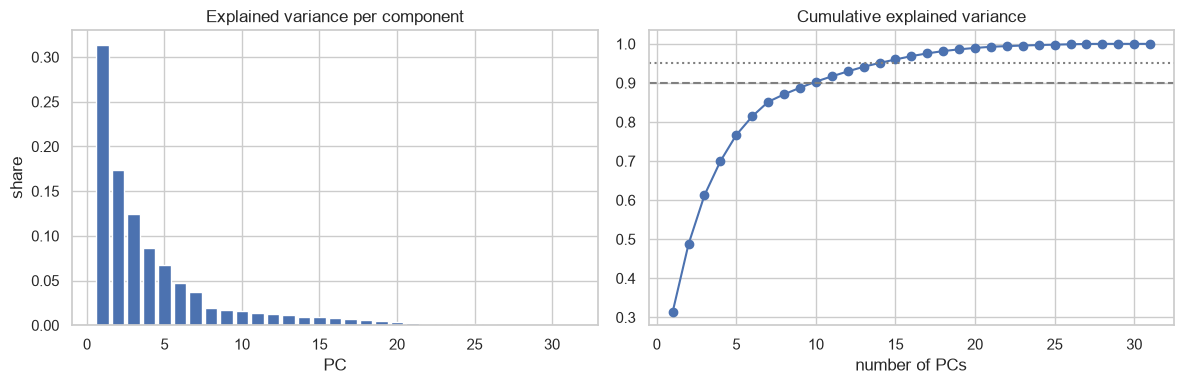

Largest loadings (PC1-PC3):


,PC1,PC2,PC3
num__is_hybrid,-0.12,0.03,0.94
num__Model year,0.04,0.71,0.12
num__gears,0.22,0.66,-0.08
num__Engine size (L),0.61,-0.13,0.08
num__Cylinders,0.56,-0.07,-0.00
num__disp_per_cyl,0.46,-0.15,0.21
cat__Fuel type_X,-0.09,-0.06,0.12
cat__Fuel type_Z,0.07,0.07,-0.11
cat__trans_type_AV,-0.05,0.01,0.10
cat__trans_type_A,0.09,0.00,0.00


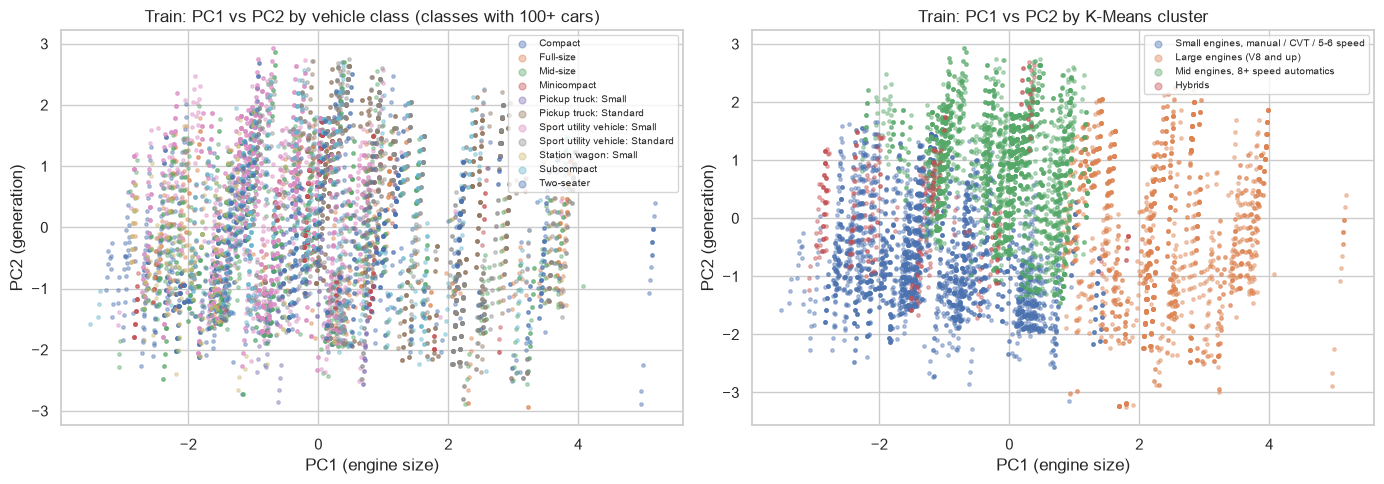

Correlation of PC1-PC3 with consumption (train):
PC1    0.818
PC2   -0.097
PC3   -0.149
dtype: float64


,MAE val (Decision Tree)
input,
all 31 features,0.621
"PCA, 10 PCs (90%)",0.802
"PCA, 14 PCs (95%)",0.677


In [63]:
from sklearn.decomposition import PCA

pca = PCA(random_state=SEED).fit(X_pca_train)          # fitted on train only
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)
n90 = int(np.argmax(cum >= 0.90) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)
print("Components:", len(evr))
print("Explained variance, first 6:", np.round(evr[:6], 3))
print(f"Components for 90%: {n90}, for 95%: {n95}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(range(1, len(evr) + 1), evr)
ax[0].set_title("Explained variance per component"); ax[0].set_xlabel("PC"); ax[0].set_ylabel("share")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o")
ax[1].axhline(0.90, color="gray", ls="--"); ax[1].axhline(0.95, color="gray", ls=":")
ax[1].set_title("Cumulative explained variance"); ax[1].set_xlabel("number of PCs")
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:3].T, index=pca_feature_names,
                        columns=["PC1", "PC2", "PC3"]).round(2)
print("Largest loadings (PC1-PC3):")
display(loadings.loc[loadings.abs().max(axis=1).sort_values(ascending=False).index[:12]])

Z_pc_train = pca.transform(X_pca_train)
Z_pc_test = pca.transform(X_pca_test)

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for lab in sorted(set(class_train)):
    m = class_train == lab
    if m.sum() >= 100:
        ax[0].scatter(Z_pc_train[m, 0], Z_pc_train[m, 1], s=6, alpha=0.4, label=lab)
ax[0].set_title("Train: PC1 vs PC2 by vehicle class (classes with 100+ cars)")
ax[0].set_xlabel("PC1 (engine size)"); ax[0].set_ylabel("PC2 (generation)")
ax[0].legend(fontsize=7, markerscale=2)
for k_lab in sorted(cluster_names):
    m = km_train == k_lab
    ax[1].scatter(Z_pc_train[m, 0], Z_pc_train[m, 1], s=6, alpha=0.4, label=cluster_names[k_lab])
ax[1].set_title("Train: PC1 vs PC2 by K-Means cluster")
ax[1].set_xlabel("PC1 (engine size)"); ax[1].set_ylabel("PC2 (generation)")
ax[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

pc_corr = pd.Series({f"PC{i+1}": np.corrcoef(Z_pc_train[:, i], y_train)[0, 1] for i in range(3)})
print("Correlation of PC1-PC3 with consumption (train):"); print(pc_corr.round(3))

# Does a reduced PCA input keep the quality? Validation only, Decision Tree with the midterm depth.
X_pca_val = prep_pca.transform(X_val)
if hasattr(X_pca_val, "toarray"):
    X_pca_val = X_pca_val.toarray()
Z_pc_val = pca.transform(X_pca_val)
rows = []
for name, ncomp in [("all 31 features", None), (f"PCA, {n90} PCs (90%)", n90), (f"PCA, {n95} PCs (95%)", n95)]:
    if ncomp is None:
        Xtr, Xva = X_pca_train, X_pca_val
    else:
        Xtr, Xva = Z_pc_train[:, :ncomp], Z_pc_val[:, :ncomp]
    dt = DecisionTreeRegressor(max_depth=best_depth, random_state=SEED).fit(Xtr, y_train)
    rows.append({"input": name, "MAE val (Decision Tree)": round(mean_absolute_error(y_val, dt.predict(Xva)), 3)})
display(pd.DataFrame(rows).set_index("input"))

**Result (train, 8268 cars):**
- **Explained variance:** PC1 31.4%, PC2 17.4%, PC3 12.5%, PC4 8.7%. Ten components explain 90.3% and 14 components reach 95% of the 31 scaled features.
- **PC1 (31%) is an engine-size axis:** loadings `Engine size` 0.61, `Cylinders` 0.56, `disp_per_cyl` 0.46. Its correlation with consumption is 0.82.
- **PC2 (17%) is a generation axis:** loadings `Model year` 0.71 and `gears` 0.66. Its correlation with consumption is -0.10, so the year is almost unrelated to consumption here as well.
- **PC3 (12.5%) is the hybrid flag:** loading of `is_hybrid` 0.94. Correlation with consumption -0.15.
- **K-Means clusters in PC1-PC2 (mean PC1 / PC2):** Large engines +2.39 / -0.25; Mid engines, 8+ speed automatics -0.12 / +0.83; Small engines, manual/CVT/5-6 speed -1.11 / -0.71; Hybrids -1.51 / +0.18, with PC3 +4.75. The two middle groups are separated mainly along PC2. The silhouette in the PC1-PC2 plane is about 0.21, lower than 0.43 in the full feature space, so the clusters are not compact in these two components alone; the hybrid group separates on PC3.
- **Vehicle classes along PC1:** Station wagon Small -1.72, Compact -0.97, SUV Small -0.84 on the small-engine side; Two-seater +0.73, SUV Standard +1.11, Pickup Standard +1.56 on the large-engine side.
- **Validation check (Decision Tree):** MAE 0.621 with all 31 features, 0.802 with the first 10 PCs (90%), 0.677 with the first 14 PCs (95%).

**Conclusion:** PCA gives a clear interpretation: the first component is engine size and power, the second is the generation of the car, and the hybrid flag becomes a separate direction. Reducing the dimension costs quality for the tree (0.621 → 0.677 with 14 components), because a tree works better with the original features. **Decision:** PCA is used for visualization and interpretation; the models in 2b, 5 and 6a use the original features.

# Stage 5. ANN (Asset)

Plan of the stage:
1. Choose the framework and the architecture of a feedforward network (MLP): activations, loss, optimizer, learning rate, early stopping.
2. Tune the network size, the learning rate and dropout on validation.
3. Show the training history and discuss convergence and overfitting.
4. Cross-validate with the same `GroupKFold(5)` and evaluate on test once, after refitting on train + validation.

## 5.1 Framework, input and architecture

**Framework:** PyTorch. It gives full control over the training loop (early stopping, restoring the best weights, saving the history) with a few lines of code, and `torch.manual_seed(SEED)` makes the runs repeatable. The data is ordinary tabular data, so the required deep-learning model is a **feedforward network (MLP)**; CNN or NLP models do not fit these features.

**Input:** the same `make_preprocessor(scale=True)` as for KNN: median imputation + `StandardScaler` for the 6 numeric columns, one-hot for the 3 categorical ones (31 inputs). It is fitted on train only. Scaling matters for a network: inputs on very different scales (`Model year` ≈ 2019 vs `is_hybrid` 0/1) make gradient descent slow and unstable.

**Target:** standardised with the train mean and std (`(y − mean) / std`); predictions are converted back to L/100 km. This keeps the output on the same scale as the initial weights.

**Architecture and training:**
- hidden layers `Linear → ReLU (→ Dropout)`; ReLU is the standard choice for hidden layers and does not saturate for large inputs;
- output: one neuron **without activation** (linear), since this is regression and the target is unbounded;
- loss: **MSE** (the standard regression loss, smooth gradient); we report MAE as the main metric, as for the other models;
- optimizer: **Adam**, mini-batches of 64, shuffled every epoch with a seeded generator;
- **EarlyStopping:** at most 300 epochs; training stops when the validation loss has not improved for 20 epochs, and the weights of the best epoch are restored.

The cell below defines the network (`MLP`) and the training function (`train_mlp`).

In [64]:
import copy
import torch
from torch import nn

torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
device = torch.device("cpu")     # the network is small; CPU keeps the results identical between machines with the same setup
print("torch", torch.__version__)


def to_dense(a):
    return a.toarray() if hasattr(a, "toarray") else np.asarray(a)


class MLP(nn.Module):
    def __init__(self, n_in, hidden=(64, 32), dropout=0.0):
        super().__init__()
        layers, prev = [], n_in
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            prev = h
        layers.append(nn.Linear(prev, 1))          # linear output for regression
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def train_mlp(Xtr, ytr, Xva=None, yva=None, hidden=(64, 32), dropout=0.0, lr=1e-3,
              batch_size=64, max_epochs=300, patience=20, fixed_epochs=None, seed=SEED):
    # With Xva: early stopping on the validation loss and restore of the best weights.
    # With fixed_epochs: train exactly that many epochs (no validation data is used).
    torch.manual_seed(seed)
    y_mean, y_std = float(np.mean(ytr)), float(np.std(ytr))       # train statistics only
    Xt = torch.tensor(Xtr, dtype=torch.float32)
    yt = torch.tensor((np.asarray(ytr) - y_mean) / y_std, dtype=torch.float32)
    model = MLP(Xt.shape[1], hidden, dropout).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    gen = torch.Generator().manual_seed(seed)
    use_val = Xva is not None and fixed_epochs is None
    if use_val:
        Xv = torch.tensor(Xva, dtype=torch.float32)
        yv = torch.tensor((np.asarray(yva) - y_mean) / y_std, dtype=torch.float32)
    hist = {"train_loss": [], "val_loss": [], "val_mae": []}
    best_loss, best_state, best_epoch, wait = np.inf, None, 0, 0

    for epoch in range(fixed_epochs or max_epochs):
        model.train()
        perm, total = torch.randperm(len(Xt), generator=gen), 0.0
        for i in range(0, len(Xt), batch_size):
            idx = perm[i:i + batch_size]
            opt.zero_grad()
            loss = loss_fn(model(Xt[idx]), yt[idx])
            loss.backward()
            opt.step()
            total += loss.item() * len(idx)
        hist["train_loss"].append(total / len(Xt))
        if use_val:
            model.eval()
            with torch.no_grad():
                pv = model(Xv)
            hist["val_loss"].append(loss_fn(pv, yv).item())
            hist["val_mae"].append(float(torch.mean(torch.abs(pv - yv))) * y_std)
            if hist["val_loss"][-1] < best_loss - 1e-5:
                best_loss, best_state, best_epoch, wait = hist["val_loss"][-1], copy.deepcopy(model.state_dict()), epoch + 1, 0
            else:
                wait += 1
                if wait >= patience:
                    break
    if use_val:
        model.load_state_dict(best_state)
    else:
        best_epoch = fixed_epochs
    model.eval()

    def predict(Xp):
        with torch.no_grad():
            return model(torch.tensor(Xp, dtype=torch.float32)).numpy() * y_std + y_mean

    return predict, hist, best_epoch

torch 2.15.0+cpu


## 5.2 Tuning on validation

**What we do:** we train 16 networks on train: hidden layers {(32), (64, 32), (128, 64), (128, 64, 32)} × learning rate {0.001, 0.003} × dropout {0, 0.1}. Each one uses early stopping on validation; the configuration with the lowest validation MAE wins.

**Why:** the size of the network decides whether it underfits (too few neurons) or overfits (too many); the learning rate decides how fast and how stably it converges; dropout is a regularizer against overfitting. A full grid with CV would mean 80 trainings, so for the network we tune on validation and use CV only for the final comparison (5.4).

In [65]:
import itertools

prep_ann = make_preprocessor(scale=True).fit(X_train)
A_train = to_dense(prep_ann.transform(X_train)).astype(np.float32)
A_val = to_dense(prep_ann.transform(X_val)).astype(np.float32)
print("Network input:", A_train.shape)

ann_grid = {"hidden": [(32,), (64, 32), (128, 64), (128, 64, 32)], "lr": [1e-3, 3e-3], "dropout": [0.0, 0.1]}
rows, histories = [], {}
for hidden, lr, dropout in itertools.product(*ann_grid.values()):
    t0 = time.perf_counter()
    pred_fn, hist, best_epoch = train_mlp(A_train, y_train.values, A_val, y_val.values,
                                          hidden=hidden, lr=lr, dropout=dropout)
    key = (hidden, lr, dropout)
    histories[key] = (hist, best_epoch)
    p_tr, p_va = pred_fn(A_train), pred_fn(A_val)
    rows.append({"hidden": str(hidden), "lr": lr, "dropout": dropout,
                 "best epoch": best_epoch, "epochs run": len(hist["train_loss"]),
                 "train MAE": mean_absolute_error(y_train, p_tr),
                 "val MAE": mean_absolute_error(y_val, p_va),
                 "time, s": time.perf_counter() - t0})
ann_search = pd.DataFrame(rows).sort_values("val MAE")
best_row = ann_search.iloc[0]
best_cfg = next(k for k in histories if str(k[0]) == best_row["hidden"] and k[1] == best_row["lr"] and k[2] == best_row["dropout"])
ANN_EPOCHS = histories[best_cfg][1]
print("Chosen:", {"hidden": best_cfg[0], "lr": best_cfg[1], "dropout": best_cfg[2]}, "| best epoch:", ANN_EPOCHS)
ann_search.round(3)

Network input: (8268, 31)
Chosen: {'hidden': (128, 64, 32), 'lr': 0.003, 'dropout': 0.0} | best epoch: 76


,hidden,lr,dropout,best epoch,epochs run,train MAE,val MAE,"time, s"
14,"(128, 64, 32)",0.003,0.0,76,96,0.440,0.576,46.744
7,"(64, 32)",0.003,0.1,57,77,0.519,0.591,26.215
8,"(128, 64)",0.001,0.0,95,115,0.439,0.594,41.756
13,"(128, 64, 32)",0.001,0.1,69,89,0.473,0.594,27.823
10,"(128, 64)",0.003,0.0,95,115,0.439,0.597,44.329
15,"(128, 64, 32)",0.003,0.1,41,61,0.507,0.599,32.898
11,"(128, 64)",0.003,0.1,69,89,0.477,0.600,38.035
9,"(128, 64)",0.001,0.1,69,89,0.496,0.613,36.904
5,"(64, 32)",0.001,0.1,57,77,0.535,0.616,26.459
12,"(128, 64, 32)",0.001,0.0,53,73,0.487,0.623,27.530


**Result (16 networks, trained on train, scored on validation):**
- **Size matters most:** one hidden layer of 32 neurons gives val MAE 0.657-0.680; (64, 32): 0.591-0.646; (128, 64): 0.594-0.613; (128, 64, 32): 0.576-0.623. A small network underfits (train MAE ≈ 0.59-0.64, almost equal to the validation error).
- **Dropout 0.1 has no consistent effect:** it lowered the validation MAE in 4 of 8 pairs and raised it in the other 4 (for example (64, 32), lr 0.003: 0.646 → 0.591, but (128, 64, 32), lr 0.003: 0.576 → 0.599).
- **Chosen:** (128, 64, 32), lr = 0.003, no dropout, val MAE **0.576**, best epoch 76. The next configurations are at 0.591-0.594, so the margin is small and partly depends on the validation split.
- Train MAE 0.440 vs val MAE 0.576: the network fits train better than unseen car models.

## 5.3 Training history of the chosen network

**What we do:** we plot the training history of the chosen configuration.

Left: the loss (MSE on the standardised target) on train and validation per epoch. Right: validation MAE in L/100 km. The dashed line marks the epoch whose weights were restored.

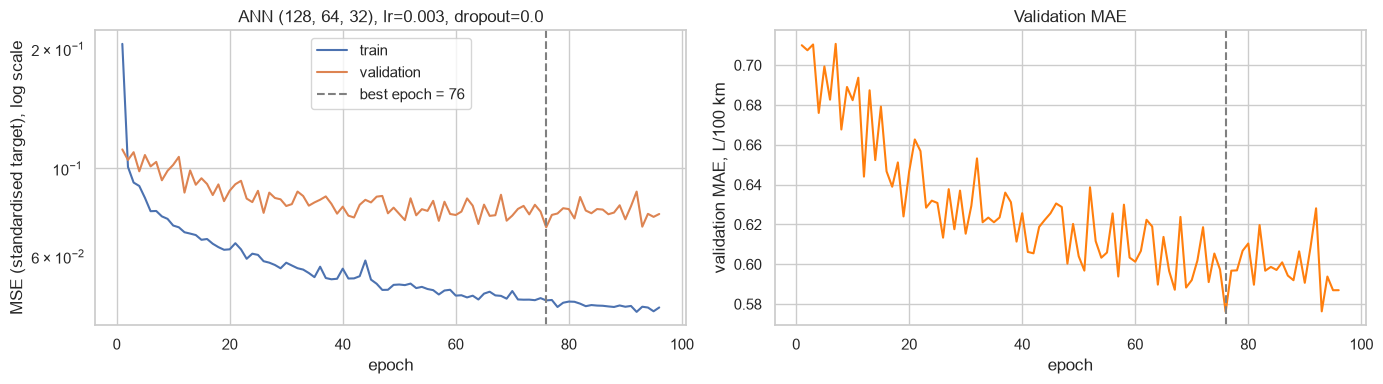

At the best epoch: train loss 0.0465, val loss 0.0711, val MAE 0.576
Last epoch (96): train loss 0.0447, val loss 0.0768, val MAE 0.587
Minimum val loss 0.0711 at epoch 76


In [66]:
hist, _ = histories[best_cfg]
epochs = np.arange(1, len(hist["train_loss"]) + 1)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(epochs, hist["train_loss"], label="train")
ax[0].plot(epochs, hist["val_loss"], label="validation")
ax[0].axvline(ANN_EPOCHS, color="grey", ls="--", label=f"best epoch = {ANN_EPOCHS}")
ax[0].set_yscale("log"); ax[0].set_xlabel("epoch"); ax[0].set_ylabel("MSE (standardised target), log scale")
ax[0].set_title(f"ANN {best_cfg[0]}, lr={best_cfg[1]}, dropout={best_cfg[2]}"); ax[0].legend()
ax[1].plot(epochs, hist["val_mae"], color="tab:orange")
ax[1].axvline(ANN_EPOCHS, color="grey", ls="--")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation MAE, L/100 km"); ax[1].set_title("Validation MAE")
plt.tight_layout(); plt.show()

b = ANN_EPOCHS - 1
print(f"At the best epoch: train loss {hist['train_loss'][b]:.4f}, val loss {hist['val_loss'][b]:.4f}, val MAE {hist['val_mae'][b]:.3f}")
print(f"Last epoch ({len(epochs)}): train loss {hist['train_loss'][-1]:.4f}, val loss {hist['val_loss'][-1]:.4f}, "
      f"val MAE {hist['val_mae'][-1]:.3f}")
print(f"Minimum val loss {min(hist['val_loss']):.4f} at epoch {int(np.argmin(hist['val_loss'])) + 1}")

**Result:**
- **Convergence:** the train loss keeps decreasing slowly until the end (0.0465 at epoch 76, 0.0447 at epoch 96), and the validation loss reaches its minimum of 0.0711 at epoch 76, so the network has converged.
- **Overfitting:** after epoch 76 the train loss still goes down while the validation loss rises (0.0711 → 0.0768 at epoch 96, val MAE 0.576 → 0.587). This is the start of overfitting. Early stopping handled it: after 20 epochs without improvement training stopped at epoch 96, and the weights of epoch 76 were restored.
- **Gap:** at the best epoch the train loss is 0.0465 vs 0.0711 on validation. Without dropout the network fits train noticeably better than unseen car models, so the stopping point matters.
- **Noise:** the validation curve jumps from epoch to epoch (mini-batches of 64, lr 0.003, 1809 validation rows). Part of the val MAE 0.576 is therefore a lucky epoch, which is why the fair comparison uses CV and test (5.4) and not the validation number.

## 5.4 Cross-validation and one run on test

**What we do:**
- **CV:** the same `GroupKFold(5)` on train as for the other models. In every fold the preprocessor is fitted on the training folds, and the network is trained for a fixed `ANN_EPOCHS` epochs, because using the CV test fold for early stopping would leak.
- **Test:** the preprocessor and the network are refitted on train + validation for `ANN_EPOCHS` epochs (as the other models were refitted in 2b) and scored on test once.

**Why:** this is the same protocol as for the models in 2b, so the comparison in 6a is fair.

In [67]:
hidden, lr, dropout = best_cfg
fold_mae = []
for tr_i, te_i in cv.split(X_train, y_train, g_train):
    p = make_preprocessor(scale=True).fit(X_train.iloc[tr_i])
    pred_fn, _, _ = train_mlp(to_dense(p.transform(X_train.iloc[tr_i])).astype(np.float32), y_train.iloc[tr_i].values,
                              hidden=hidden, lr=lr, dropout=dropout, fixed_epochs=ANN_EPOCHS)
    fold_mae.append(mean_absolute_error(y_train.iloc[te_i], pred_fn(to_dense(p.transform(X_train.iloc[te_i])).astype(np.float32))))
cv_scores["ANN"] = {"CV MAE": np.mean(fold_mae), "CV MAE std": np.std(fold_mae)}
val_scores["ANN"] = best_row["val MAE"]
print("ANN CV MAE per fold:", np.round(fold_mae, 3), f"-> {np.mean(fold_mae):.3f} ± {np.std(fold_mae):.3f}")

# Final fit on train + validation, one evaluation on test
t0 = time.perf_counter()
prep_ann_final = make_preprocessor(scale=True).fit(X_trval)
ann_predict, ann_hist_final, _ = train_mlp(to_dense(prep_ann_final.transform(X_trval)).astype(np.float32), y_trval.values,
                                           hidden=hidden, lr=lr, dropout=dropout, fixed_epochs=ANN_EPOCHS)
fit_times["ANN"] = time.perf_counter() - t0
t0 = time.perf_counter()
final_test_preds["ANN"] = ann_predict(to_dense(prep_ann_final.transform(X_test)).astype(np.float32))
predict_times["ANN"] = time.perf_counter() - t0
ann_test = evaluate(y_test, final_test_preds["ANN"])
print("ANN on test:", {k: round(float(v), 3) for k, v in ann_test.items()}, f"| training time {fit_times['ANN']:.1f} s")

ANN CV MAE per fold: [0.699 0.62  0.706 0.677 0.658] -> 0.672 ± 0.031
ANN on test: {'MAE': 0.601, 'RMSE': 0.836, 'R2': 0.913} | training time 35.9 s


**Result:**
- **CV (GroupKFold, 5 folds, 76 epochs):** MAE per fold 0.699 / 0.620 / 0.706 / 0.677 / 0.658 → **0.672 ± 0.031**. This is worse than the tuned Decision Tree (0.653 ± 0.031) and KNN (0.667 ± 0.034). The val MAE of 5.2 (0.576) was clearly optimistic, because validation was used both for early stopping and for choosing the configuration.
- **Test (trained on train + validation, one run):** MAE **0.601**, RMSE **0.836**, R² **0.913**. Training took about 36 s on CPU.

**Conclusion:** the ANN is in the same accuracy group as the tree and KNN. It does not win on MAE, but it has the lowest RMSE and the highest R² of all models on test, so it makes slightly fewer large errors. The full comparison is in 6a.

## Stage 5 summary

- **Model:** MLP 31 → 128 → 64 → 32 → 1, ReLU, linear output, MSE on the standardised target, Adam with lr = 0.003, no dropout, batches of 64, early stopping (patience 20) → 76 epochs.
- **Tuning:** larger networks are better (one layer of 32 neurons: val MAE 0.657-0.680; three layers: 0.576-0.623); dropout had no consistent effect (better in 4 of 8 pairs).
- **Training:** the network converged; after epoch 76 the validation loss started to rise, and early stopping restored the best weights.
- **Results:** CV MAE 0.672 ± 0.031, test MAE 0.601, RMSE 0.836 (the lowest of all models), R² 0.913 (the highest).
- **Limitations:** the validation curve is noisy, so the chosen configuration and epoch are partly luck (val MAE 0.576 vs CV 0.672); training takes ≈ 36 s vs ≈ 0.4 s for the tree; the result is for one seed, and PyTorch results can differ slightly between machines.

# Stage 6a. Final comparison table (Asset)

Plan of the stage:
1. Collect all models in one table with the same protocol: CV MAE, validation MAE, test MAE / RMSE / R², training and prediction time.
2. Check the success criterion and choose the final model.
3. Compare the errors on hybrids with the midterm model.
4. Hand over the final test predictions to the error analysis (6b, Bigali).

## 6a.1 Final table

**What we do:** one table for all models with the same protocol:
- **CV MAE:** `GroupKFold(5)` on train (groups = `Make + Model`), with the chosen settings;
- **val MAE:** fitted on train, scored on validation;
- **test MAE / RMSE / R²:** refitted on train + validation, scored on test once (2b for the classical models, 5.3 for the ANN);
- **fit time:** the final fit on train + validation (for the ANN: preprocessing + `ANN_EPOCHS` epochs on CPU); **predict time:** predicting the 1751 test cars.

Note: for the tree and KNN the validation set was not used for the choice (the grid used CV), while the ANN used validation for early stopping and for picking the configuration, so its val MAE is slightly optimistic. Test is the fair comparison.

In [68]:
model_order = ["Mean baseline", "Linear Regression", "Decision Tree", "KNN", "ANN"]
settings = {
    "Mean baseline": "mean of train",
    "Linear Regression": "OLS, unscaled",
    "Decision Tree": f"max_depth={best_tree['model__max_depth']}, min_samples_leaf={best_tree['model__min_samples_leaf']}",
    "KNN": f"{best_knn_label}, k={knn_searches[best_knn_label].best_params_['model__n_neighbors']}, "
           f"{knn_searches[best_knn_label].best_params_['model__weights']}",
    "ANN": f"MLP {best_cfg[0]}, ReLU, Adam lr={best_cfg[1]}, dropout={best_cfg[2]}, {ANN_EPOCHS} epochs",
}
final_table = pd.DataFrame({
    name: {
        "settings": settings[name],
        "CV MAE": cv_scores[name]["CV MAE"],
        "CV MAE std": cv_scores[name]["CV MAE std"],
        "val MAE": val_scores[name],
        **{f"test {k}": v for k, v in evaluate(y_test, final_test_preds[name]).items()},
        "fit time, s": fit_times[name],
        "predict time, s": predict_times[name],
    } for name in model_order
}).T
num_c = final_table.columns.drop("settings")
final_table[num_c] = final_table[num_c].astype(float)

final_best_name = final_table.drop("Mean baseline")["test MAE"].idxmin()
ratio = final_table.loc["Mean baseline", "test MAE"] / final_table.loc[final_best_name, "test MAE"]
print(f"Best model on test: {final_best_name}")
print(f"Baseline MAE / best MAE = {ratio:.2f} (need ≥ 2) | best R² = {final_table.loc[final_best_name, 'test R2']:.3f} (need ≥ 0.8)")
print("Success criterion:", "met" if ratio >= 2 and final_table.loc[final_best_name, "test R2"] >= 0.8 else "NOT met")
fmt = {c: "{:.3f}" for c in num_c}
fmt["fit time, s"] = "{:.2f}"
final_table.style.format(fmt)

Best model on test: Decision Tree
Baseline MAE / best MAE = 3.70 (need ≥ 2) | best R² = 0.912 (need ≥ 0.8)
Success criterion: met


,settings,CV MAE,CV MAE std,val MAE,test MAE,test RMSE,test R2,"fit time, s","predict time, s"
Mean baseline,mean of train,2.284,0.070,2.123,2.211,2.835,-0.000,0.00,0.000
Linear Regression,"OLS, unscaled",0.815,0.022,0.768,0.724,0.948,0.888,0.09,0.014
Decision Tree,"max_depth=20, min_samples_leaf=1",0.653,0.031,0.608,0.598,0.842,0.912,0.42,0.014
KNN,"without Model year, scaled, k=50, distance",0.667,0.034,0.611,0.612,0.859,0.908,0.05,0.611
ANN,"MLP (128, 64, 32), ReLU, Adam lr=0.003, dropout=0.0, 76 epochs",0.672,0.031,0.576,0.601,0.836,0.913,35.94,0.014


## 6a.2 Plots and hybrids

**What we do:**
- a bar chart of CV, validation and test MAE for every model, with the success threshold (baseline MAE / 2);
- actual vs predicted consumption on test for the final model;
- MAE and bias on the 48 test hybrids for every model and for the midterm tree (no `is_hybrid`).

**Why:** the plot shows whether the three evaluation sets agree; the hybrids were the main error of the midterm (7.8).

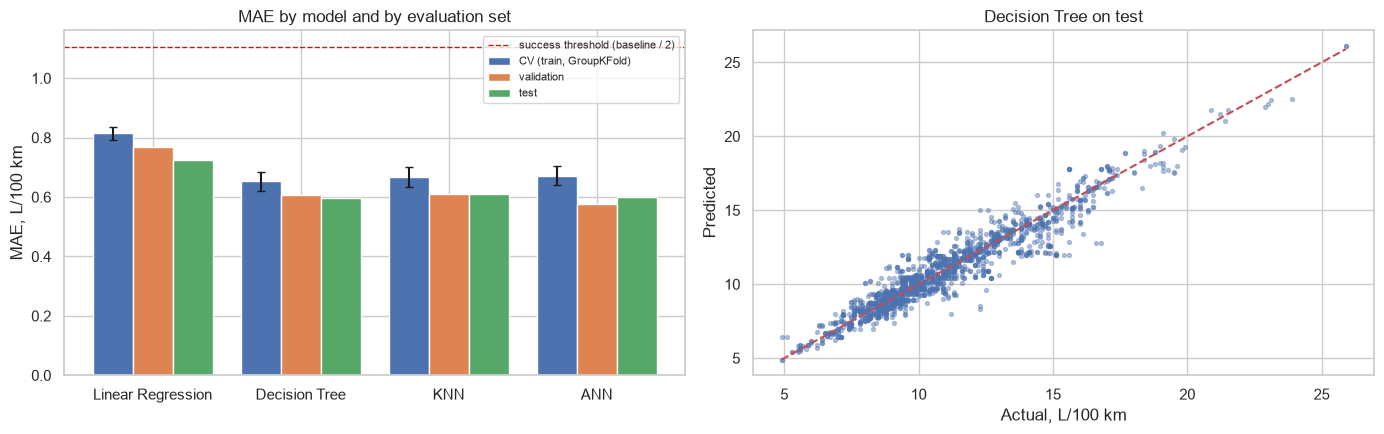

Test hybrids: 48 cars


,MAE hybrids,bias hybrids,MAE others
Linear Regression,0.645,-0.002,0.726
Decision Tree,0.520,0.312,0.600
KNN,0.497,0.000,0.615
ANN,0.528,0.225,0.603
Decision Tree (midterm),1.066,0.998,0.603


In [69]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
models_no_base = model_order[1:]
xpos = np.arange(len(models_no_base)); w = 0.27
ax[0].bar(xpos - w, final_table.loc[models_no_base, "CV MAE"], w, yerr=final_table.loc[models_no_base, "CV MAE std"],
          capsize=3, label="CV (train, GroupKFold)")
ax[0].bar(xpos, final_table.loc[models_no_base, "val MAE"], w, label="validation")
ax[0].bar(xpos + w, final_table.loc[models_no_base, "test MAE"], w, label="test")
ax[0].axhline(final_table.loc["Mean baseline", "test MAE"] / 2, color="red", ls="--", lw=1, label="success threshold (baseline / 2)")
ax[0].set_xticks(xpos); ax[0].set_xticklabels(models_no_base)
ax[0].set_ylabel("MAE, L/100 km"); ax[0].set_title("MAE by model and by evaluation set"); ax[0].legend(fontsize=8)

p = final_test_preds[final_best_name]
ax[1].scatter(y_test, p, s=8, alpha=0.4)
lims = [y_test.min(), y_test.max()]
ax[1].plot(lims, lims, "r--")
ax[1].set_xlabel("Actual, L/100 km"); ax[1].set_ylabel("Predicted")
ax[1].set_title(f"{final_best_name} on test")
plt.tight_layout(); plt.show()

# Hybrids on test: did is_hybrid + tuning fix the midterm overestimation?
hyb = X_test["is_hybrid"] == 1
hyb_rows = {name: {"MAE hybrids": np.abs(final_test_preds[name][hyb.values] - y_test[hyb]).mean(),
                   "bias hybrids": (final_test_preds[name][hyb.values] - y_test[hyb]).mean(),
                   "MAE others": np.abs(final_test_preds[name][~hyb.values] - y_test[~hyb]).mean()}
            for name in models_no_base}
hyb_rows["Decision Tree (midterm)"] = {"MAE hybrids": np.abs(test_preds["Decision Tree"][hyb.values] - y_test[hyb]).mean(),
                                       "bias hybrids": (test_preds["Decision Tree"][hyb.values] - y_test[hyb]).mean(),
                                       "MAE others": np.abs(test_preds["Decision Tree"][~hyb.values] - y_test[~hyb]).mean()}
print(f"Test hybrids: {hyb.sum()} cars")
pd.DataFrame(hyb_rows).T.round(3)

**Result (final table):**

| Model | Settings | CV MAE | val MAE | test MAE | test RMSE | test R² | fit time, s |
|---|---|---|---|---|---|---|---|
| Mean baseline | mean of train | 2.284 ± 0.070 | 2.123 | 2.211 | 2.835 | 0.000 | 0.00 |
| Linear Regression | OLS | 0.815 ± 0.022 | 0.768 | 0.724 | 0.948 | 0.888 | ≈ 0.1 |
| **Decision Tree** | max_depth=20, min_samples_leaf=1 | **0.653 ± 0.031** | 0.608 | **0.598** | 0.842 | 0.912 | ≈ 0.4 |
| KNN | scaled, no `Model year`, k=50, distance | 0.667 ± 0.034 | 0.611 | 0.612 | 0.859 | 0.908 | ≈ 0.05 (predict ≈ 0.6) |
| ANN | MLP (128, 64, 32), ReLU, Adam 0.003, no dropout, 76 epochs | 0.672 ± 0.031 | 0.576* | 0.601 | **0.836** | **0.913** | ≈ 36 |

\* optimistic: validation was used for early stopping and for picking the configuration.

**Hybrids on test (48 cars):** the midterm tree overestimated them by +1.00 L/100 km (MAE 1.066). Now the hybrid MAE is 0.52 (tree), 0.50 (KNN), 0.53 (ANN), 0.65 (Linear Regression), with bias between 0.00 and +0.31. The main midterm error is fixed.

**Conclusion:**
1. **Success criterion met:** the best test MAE (Decision Tree, 0.598) is 3.70 times lower than the baseline (2.211), R² = 0.912. All four models pass the criterion on the group-split test.
2. **The three non-linear models are practically tied:** on test the tree, ANN and KNN differ by at most 0.014 MAE (0.598 / 0.601 / 0.612), which is less than one CV std (≈ 0.03). Linear Regression is clearly behind (0.724), so the relationship is non-linear (interactions of engine, gearbox, class and hybrid).
3. **ANN vs classical models:** the network has the lowest test RMSE and the highest R² (slightly fewer large errors), but the worst CV MAE of the three (0.672) and the largest gap between validation and CV. It also takes about 85× more training time (≈ 36 s vs ≈ 0.4 s; exact times vary between runs) and is harder to explain. On 31 tabular features with about 10 000 rows, a well-tuned tree is as good as a neural network.
4. **Final model: Decision Tree** (`max_depth=20`, `min_samples_leaf=1`): the lowest test MAE (the main metric), the lowest CV MAE, fast training and an interpretable structure. Its test predictions are `final_test_preds[final_best_name]`; stage 6b should use them in place of the interim midterm tree.
5. **Caveat from 2c:** these numbers are for unseen models in the *same* years. For brand-new models in future years, the error is about twice as large (≈ 1.2 L/100 km).

## 6a.3 Objects for the next stages

For **Bigali** (6b error analysis):
- `final_best_name`: the final model (`"Decision Tree"`);
- `final_test_preds[final_best_name]`: its test predictions (a numpy array in the order of `X_test`). In the first line of the 6b cell, replace `test_preds[best_name]` with it;
- `final_test_preds`: the test predictions of every model, for comparing errors by group;
- `final_table`: the comparison table; `final_models`: the classical models fitted on train + validation.

The cell below stops the notebook if any of these objects is missing.

In [70]:
handoff_6a = ["final_table", "final_best_name", "final_test_preds", "final_models", "tuned"]
missing = [n for n in handoff_6a if n not in globals()]
assert not missing, f"Not found: {missing}"
assert len(final_test_preds[final_best_name]) == len(X_test)
print("Stage 6a objects are ready:", ", ".join(handoff_6a), "| final model:", final_best_name)

Stage 6a objects are ready: final_table, final_best_name, final_test_preds, final_models, tuned | final model: Decision Tree


# Stage 6b. Error analysis and conclusions (Bigali)

**Status: interim.** The analysis below uses the test predictions of the midterm Decision Tree, because the final table from 6a (Asset) is not ready. When 6a is done, replace `test_preds[best_name]` in the code with the final model's test predictions and re-run the cell and the text.

**What we do:** the test errors sliced by hybrid flag, K-Means cluster, fuel type, number of cylinders and vehicle class (classes with at least 20 cars).

**Why:** to show where the model is wrong and whether the errors are concentrated in a few groups. This feeds the limitations and the conclusions.

In [71]:
# Interim model: midterm Decision Tree (test predictions). Replace with the final model from 6a.
y_hat = pd.Series(test_preds[best_name], index=X_test.index)

e = pd.DataFrame({"y_true": y_test, "y_pred": y_hat})
e["error"] = e["y_pred"] - e["y_true"]
e["abs_error"] = e["error"].abs()
e["class"] = X_test["Vehicle class"]
e["fuel"] = X_test["Fuel type"]
e["cyl"] = X_test["Cylinders"]
e["hybrid"] = X_test["is_hybrid"].map({0: "no", 1: "yes"})
e["cluster"] = pd.Series(km_test, index=X_test.index).map(cluster_names)
e["cyl_group"] = pd.cut(e["cyl"], [0, 4, 6, 8, 20], labels=["3-4", "5-6", "8", "10+"])

def by(col, min_n=0):
    t = e.groupby(col, observed=True).agg(n=("abs_error", "size"), MAE=("abs_error", "mean"), bias=("error", "mean"))
    return t[t["n"] >= min_n].round(2).sort_values("MAE", ascending=False)

print(f"Overall test MAE: {e['abs_error'].mean():.3f}, bias: {e['error'].mean():+.3f}")
for col in ["hybrid", "cluster", "fuel", "cyl_group"]:
    print(f"\n== by {col}")
    display(by(col))
print("\n== by vehicle class (n >= 20)")
display(by("class", 20))
print("\nShare of total absolute error by hybrid flag:")
display((e.groupby("hybrid")["abs_error"].sum() / e["abs_error"].sum()).round(3))
print("\nTop 10 errors:")
display(e.sort_values("abs_error", ascending=False).head(10)[
    ["class", "fuel", "cyl", "hybrid", "y_true", "y_pred", "abs_error"]].round(2))

Overall test MAE: 0.615, bias: -0.019

== by hybrid


,n,MAE,bias
hybrid,,,
yes,48,1.07,1.00
no,1703,0.60,-0.05



== by cluster


,n,MAE,bias
cluster,,,
Hybrids,48,1.07,1.00
Large engines (V8 and up),394,0.66,-0.25
"Mid engines, 8+ speed automatics",656,0.60,0.04
"Small engines, manual / CVT / 5-6 speed",653,0.57,-0.02



== by fuel


,n,MAE,bias
fuel,,,
E,69,0.90,-0.00
Z,832,0.65,-0.12
X,793,0.56,0.09
D,57,0.51,-0.00


... (4 outputs left out)


Share of total absolute error by hybrid flag:


hybrid
no     0.952
yes    0.048
Name: abs_error, dtype: float64


Top 10 errors:


,class,fuel,cyl,hybrid,y_true,y_pred,abs_error
7903,Full-size,X,4,no,9.1,5.00,4.10
8878,Full-size,X,4,no,9.1,5.00,4.10
1926,Compact,Z,4,no,12.3,8.30,4.00
1292,Compact,Z,8,no,16.8,12.80,4.00
3480,Subcompact,Z,8,no,15.6,11.70,3.90
823,Compact,Z,4,no,12.3,8.50,3.80
193,Compact,Z,8,no,16.6,12.80,3.80
8755,Sport utility vehicle: Standard,X,6,yes,9.6,13.38,3.78
4540,Subcompact,Z,8,no,15.4,11.70,3.70
7774,Sport utility vehicle: Standard,X,6,yes,9.6,13.07,3.47


**Result (interim: midterm Decision Tree on test, 1751 cars):**
- Overall MAE 0.615, bias -0.02.
- **Hybrids** (`is_hybrid` = 1, 48 cars): MAE 1.07, bias +1.00. The model overestimates their consumption by about 1 L/100 km. Hybrids are 2.7% of test cars and 4.8% of the total absolute error. The midterm model has no hybrid flag, so this is the error `is_hybrid` is meant to fix; in 2a it cut the Decision Tree's hybrid MAE on validation from 0.874 to 0.493. The final model has to confirm this on test.
- **Fuel type:** E85 MAE 0.90 (n = 69); premium gasoline 0.65 (bias -0.12); regular gasoline 0.56; diesel 0.51 (n = 57).
- **Cylinders:** 8-cylinder cars MAE 0.71, bias -0.27 (n = 320), so heavy engines are underestimated. 10+ cylinders have MAE 0.42, but only 74 cars.
- **K-Means clusters:** Large engines MAE 0.66, bias -0.25 (underestimated); Mid engines 0.60; Small engines 0.57; Hybrids 1.07.
- **Vehicle classes (n ≥ 20):** the largest errors are Pickup truck Small (0.98, bias +0.47, n = 84) and Subcompact (0.90, bias -0.59, n = 123). The smallest are Full-size (0.40, n = 154) and Station wagon Small (0.46, n = 72).
- **Largest single errors:** six of the top ten are Compact or Subcompact cars with 4 or 8 cylinders, and two are hybrid-flagged SUVs that are overestimated. One case needs checking in the data: a Honda Accord Sport/Touring with 4 cylinders has true consumption 9.1 and predicted 5.0. It may be a hybrid variant whose name does not contain the word "hybrid", which the name rule does not catch.

**Interim conclusions:**
1. The errors are concentrated in a few groups: hybrids have the highest MAE, and heavy or powerful cars (8 cylinders, Pickup Small, Subcompact) have the next highest. Hybrids make up only 4.8% of the absolute error on test.
2. The bias has different signs by group: hybrids and Pickup Small are overestimated, while Subcompact, 8-cylinder cars and the Large engines cluster are underestimated. A single global model averages these effects out.
3. Groups with very few test cars (E85, 10+ cylinders, vans) do not support firm conclusions.

**Limitations:**
- The data has no weight, power or drivetrain. The hybrid flag relies on the model name: it misses some hybrids and cannot see plug-in hybrids, which are not in the data.
- The test set is one random group split (its composition depends on `SEED`) and has only 48 hybrids and very few vans.
- The target is the official laboratory rating, not consumption in real driving.

**Ethical and practical considerations:**
- The model is an estimate, not an official rating. It should not replace the NRCan label in purchase, tax or regulatory decisions.
- The errors are systematic for specific groups: hybrids are overestimated and powerful cars are underestimated. The estimate is therefore least reliable for the choice buyers care about most, hybrid versus conventional.
- The data is a public government source under an open licence, and it must be cited as such.

**Final conclusions:** to be completed after 6a. Compare the final model's MAE by the same groups with the table above, and check whether the hybrid overestimation disappears and whether the underestimation of heavy cars remains.

# Stage 7. Reproducibility (Iskander)

**What is fixed:**
- one `SEED = 42` at the top of the notebook; the split (`GroupShuffleSplit`), the random-split comparison, `StratifiedGroupKFold`, the Decision Tree, K-Means and PCA all take `random_state=SEED`; the ANN sets its framework seed from `SEED`;
- the data is read from a fixed URL, so every member gets the same file;
- `requirements.txt` lists the package versions the notebook was run with.

**Check below:** we repeat the key random steps with the same `SEED` and compare them with the results stored earlier in the notebook. If anything differs, the `assert` stops the run.

In [72]:
# 1) the split gives the same rows
s1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
tmp_idx, tst_idx = next(s1.split(X, y, groups))
assert set(X.index[tst_idx]) == set(X_test.index), "test split changed"
print("Split: same test rows,", len(tst_idx))

# 2) K-Means gives the same clusters
again = KMeans(n_clusters=K_FINAL, n_init=20, random_state=SEED).fit(
    Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit_transform(X_train[km_features]))
assert adjusted_rand_score(again.labels_, km_train) == 1.0, "K-Means changed"
print("K-Means: identical partition (ARI = 1.0)")

# 3) the tuned tree from the midterm gives the same validation MAE
tree_again = Pipeline([("prep", make_preprocessor(num_without_hybrid)),
                       ("model", DecisionTreeRegressor(max_depth=best_depth, random_state=SEED))]).fit(X_train, y_train)
mae_again = mean_absolute_error(y_val, tree_again.predict(X_val))
assert np.isclose(mae_again, hybrid_effect.loc[("Decision Tree", "without is_hybrid"), "MAE val"])
print(f"Decision Tree: same validation MAE {mae_again:.4f}")

Split: same test rows, 1751
K-Means: identical partition (ARI = 1.0)
Decision Tree: same validation MAE 0.6623


In [73]:
# Versions to put into requirements.txt (run at the very end, after all stages are merged)
import importlib
packages = ["numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn"]
for extra in ["tensorflow", "torch"]:          # the ANN framework, if installed
    if importlib.util.find_spec(extra) is not None:
        packages.append(extra)
from importlib.metadata import version
print(f"# Python {sys.version.split()[0]}")
for p in packages:
    print(f"{p}=={version(p)}")

# Python 3.12.0
numpy==2.5.3
pandas==3.0.5
scikit-learn==1.9.1
scipy==1.18.1
matplotlib==3.11.2
seaborn==0.13.2
torch==2.15.0


**Final checklist (after all stages are merged):**
1. In the project environment: `pip freeze > requirements.txt` (or copy the pinned lines printed above).
2. *Kernel → Restart & Run All*; the notebook must finish without errors.
3. Compare the final table with the previous run; the numbers must be identical.